# Яндекс Недвижимость

<a id=content></a>
## Содержание
<br>[Описание проекта](#descr_proj)
<br>[Описание данных](#descr_data)
<br>
<br>[<b>Шаг 1. Загрузка данных и получение общей информации</b>](#1)
<br>
<br>[<b>Шаг 2. Предварительная обработка данных</b>](#2)
<br>[2.1. Обработка пропущенных значений](#2.1.)
<br>[2.1.1. Заполнение признака 'is apartment'](#2.1.1.)
<br>[2.1.2. Заполнение признака 'locality_name'](#2.1.2.)
<br>[2.1.3. Заполнение признака 'airport_nearest', 'cityCenters_nearest'](#2.1.3.)
<br>[2.1.4. Заполнение признака 'ceiling_height'](#2.1.4.)
<br>[2.1.5. Заполнение признака 'days_exposition'](#2.1.5.)
<br>[2.1.6. Заполнение признаков 'parks_nearest', 'parks_around3000', 'ponds_nearest', 'ponds_around3000'](#2.1.6.)
<br>[2.1.7. Заполнение признака 'balcony'](#2.1.7.)
<br>[2.1.8. Заполнение признака 'kitchen_area', 'living_area'](#2.1.8.)
<br>[2.1.9. Заполнение признака 'floors_total'](#2.1.9.)
<br>[2.2. Обработка типов данных](#2.2.)
<br>[2.3. Обработка дубликатов](#2.3.)
<br>[2.4. Обработка аномальных значений](#2.4.)
<br>[2.4.1. Аномальные значения признака 'last_price'](#2.4.1.)
<br>[2.4.2. Аномальные значения признаков 'total_area', 'living_area', 'kitchen_area'](#2.4.2.)
<br>[2.4.3. Аномальные значения признака 'rooms'](#2.4.3.)
<br>[2.4.4. Аномальные значения признака 'ceiling_height'](#2.4.4.)
<br>[2.4.5. Аномальные значения признака 'balcony'](#2.4.5.)
<br>[2.4.6. Аномальные значения признаков 'floor', 'floors_total'](#2.4.6.)
<br>[2.4.7. Аномальные значения признаков 'cityCenters_nearest', 'airports_nearest'](#2.4.7.)
<br>[2.4.8. Аномальные значения признаков 'parks_nearest', 'ponds_nearest', 'parks_around3000', 'ponds_around3000'](#2.4.8.)
<br>[2.4.9. Аномальные значения признака 'total_images'](#2.4.9.)
<br>[2.4.10. Аномальные значения признака 'days_exposition'](#2.4.10.)
<br>
<br>[<b>Шаг 3. Создание новых признаков</b>](#3)
<br>[3.1. Цена одного кв.м](#3.1.)
<br>[3.2. День недели публикации объявления](#3.2.)
<br>[3.3. Месяц публикации объявления](#3.3.)
<br>[3.4. Год публикации объявления](#3.4.)
<br>[3.5. Тип этажа квартиры](#3.5.)
<br>[3.6. Расстояние до центра города в километрах](#3.6.)
<br>
<br>[<b>Шаг 4. Исследовательский анализ данных</b>](#4)
<br>[4.1. Изучение параметров объектов](#4.1.)
<br>[4.2. Сроки продажи квартир](#4.2.)
<br>[4.3. Зависимость цены от ряда признаков](#4.3.)
<br>[4.4. Средняя цена кв.м. в топ-10 населённых пунктах по количеству объявлений](#4.4.)
<br>[4.5. Зависимость цены от расстояния до центра города](#4.5.)
<br>
<br>[<b>Шаг 5. Вывод</b>](#5)

<a id=descr_proj></a>
## Описание проекта

В нашем распоряжении данные сервиса Яндекс Недвижимость: архив объявлений за несколько лет о продаже квартир в Санкт-Петербурге и соседних населённых пунктах. В зависимости от источника поступления информации, сведения о каждой квартире мы можем классифицировать как *добавленные пользователем* и *картографические*. Например, к первому типу относятся площадь квартиры, её этаж и количество балконов, ко второму — расстояния до центра города, аэропорта и ближайшего парка. **Задача:** выполнить предобработку данных и изучить их, чтобы найти интересные особенности и зависимости, которые существуют на рынке недвижимости.

<a id=descr_data></a>
## Описание данных

Исходный датафрейм `real_estate_data.csv` содержит 23 699 строк в разрезе следующих 22 признаков:

| № п/п  | Наименование признака  | Краткое описание                            | Единицы измерения  | Значение признака    |
|--------|:-----------------------|:--------------------------------------------|:---------|:-------------------------------|
| 1.     | `locality_name`        | название населённого пункта                 | локация  | 365 адресных единиц            |
| 2.     | `last_price`           | цена на момент снятия с публикации          | тыс.руб. | от 12 190 до 763 000 000       |
| 3.     | `total_area`           | общая площадь квартиры в квадратных метрах  | м²       | от 12 до 900                   |
| 4.     | `living_area`          | жилая площадь в квадратных метрах           | м²       | от 2 до 409.7                  |
| 5.     | `kitchen_area`         | площадь кухни в квадратных метрах           | м²       | от 1.3 до 112                  |
| 6.     | `rooms`                | число комнат                                | ед.      | от 0 до 19                     |
| 7.     | `ceiling_height`       | высота потолков                             | м        | от 1 до 100                    |
| 8.     | `balcony`              | число балконов                              | шт.      | от 0 до 5                      |
| 9.     | `is_apartment`         | апартаменты                                 | да / нет | 1 / 0                          |
| 10.    | `studio`               | квартира-студия                             | да / нет | 1 / 0                          |
| 11.    | `open_plan`            | свободная планировка                        | да / нет | 1 / 0                          |
| 12.    | `floor`                | этаж                                        | ед.      | 1 - 33                         |
| 13.    | `floors_total`         | всего этажей в доме                         | ед.      | 1 - 60                         |
| 14.    | `cityCenters_nearest`  | расстояние до центра города                 | м        | от 181 до 65 968               |
| 15.    | `airports_nearest`     | расстояние до ближайшего аэропорта в метрах | м        | от 0 до 84 869                 |
| 16.    | `parks_around3000`     | число парков в радиусе 3 км                 | ед.      | от 0 до 3                      |
| 17.    | `parks_nearest`        | расстояние до ближайшего парка              | м        | от 1 до 3 190                  |
| 18.    | `ponds_around3000`     | число водоёмов в радиусе 3 км               | ед.      | от 0 до 3                      |
| 19.    | `ponds_nearest`        | расстояние до ближайшего водоёма            | м        | от 13 до 1 344                 |
| 20.    | `total_images`         | число фотографий квартиры в объявлении      | ед.      | от 0 до 50                     |
| 21.    | `first_day_exposition` | дата публикации                             | дата     | с 27.11.2014 по 03.05.2019     |
| 22.    | `days_exposition`      | длительность периода размещения объявления  | ед.      | от 1 до 1 580                  |

Значения признаков получены с помощью последовательного применения методов `min()`, `max()` и `unique()` ко всем столбцам датафрейма.

<a id=1></a>
## Шаг 1. Загрузка данных и получение общей информации

In [1]:
# импорт библиотек
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime

# настройки визуализации
%config InlineBackend.figure_format='svg' # наиболее чёткое отображение графиков
%matplotlib inline
plt.rc('figure', figsize=(12, 6), facecolor='white')

import warnings
warnings.simplefilter('ignore')

In [2]:
# загрузка файла в датафрейм
try:
    df = pd.read_csv('https://code.s3.yandex.net/datasets/real_estate_data.csv', sep='\t')
except:
    df = pd.read_csv('real_estate_data.csv', sep='\t')

In [3]:
# датафрейм хранит признаки в алфавитном порядке
# пересобираем датафрейм в порядке смыслового значения признаков
df = df[['locality_name', 'last_price', 'total_area', 'living_area', 'kitchen_area', 'rooms', 
        'ceiling_height', 'balcony', 'is_apartment', 'studio', 'open_plan', 'floor', 'floors_total',
        'cityCenters_nearest', 'airports_nearest', 'parks_around3000', 'parks_nearest', 
        'ponds_around3000', 'ponds_nearest', 'total_images', 'first_day_exposition', 'days_exposition']]

In [4]:
# выводим первые 5 строк датафрейма для ознакомления
df.head()

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,floors_total,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition
0,Санкт-Петербург,13000000.0,108.0,51.0,25.0,3,2.70,NaN,NaN,False,...,16.0,16028.0,18863.0,1.0,482.0,2.0,755.0,20,2019-03-07T00:00:00,NaN
1,посёлок Шушары,3350000.0,40.4,18.6,11.0,1,NaN,2.0,NaN,False,...,11.0,18603.0,12817.0,0.0,NaN,0.0,NaN,7,2018-12-04T00:00:00,81.0
2,Санкт-Петербург,5196000.0,56.0,34.3,8.3,2,NaN,0.0,NaN,False,...,5.0,13933.0,21741.0,1.0,90.0,2.0,574.0,10,2015-08-20T00:00:00,558.0
3,Санкт-Петербург,64900000.0,159.0,NaN,NaN,3,NaN,0.0,NaN,False,...,14.0,6800.0,28098.0,2.0,84.0,3.0,234.0,0,2015-07-24T00:00:00,424.0
4,Санкт-Петербург,10000000.0,100.0,32.0,41.0,2,3.03,NaN,NaN,False,...,14.0,8098.0,31856.0,2.0,112.0,1.0,48.0,2,2018-06-19T00:00:00,121.0


In [5]:
# выводим основную информацию о количестве записей, количестве ненулевых значений, типах признаков 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   locality_name         23650 non-null  object 
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   living_area           21796 non-null  float64
 4   kitchen_area          21421 non-null  float64
 5   rooms                 23699 non-null  int64  
 6   ceiling_height        14504 non-null  float64
 7   balcony               12180 non-null  float64
 8   is_apartment          2775 non-null   object 
 9   studio                23699 non-null  bool   
 10  open_plan             23699 non-null  bool   
 11  floor                 23699 non-null  int64  
 12  floors_total          23613 non-null  float64
 13  cityCenters_nearest   18180 non-null  float64
 14  airports_nearest      18157 non-null  float64
 15  parks_around3000   

In [6]:
# первичный статистический анализ
df.describe().astype(int)

,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,floor,floors_total,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,days_exposition
count,23699,23699,21796,21421,23699,14504,12180,23699,23613,18180,18157,18181,8079,18181,9110,23699,20518
mean,6541548,60,34,10,2,2,1,5,10,14191,28793,0,490,0,517,9,180
std,10887013,35,22,5,1,1,1,4,6,8608,12630,0,342,0,277,5,219
min,12190,12,2,1,0,1,0,1,1,181,0,0,1,0,13,0,1
25%,3400000,40,18,7,1,2,0,2,5,9238,18585,0,288,0,294,6,45
50%,4650000,52,30,9,2,2,1,4,9,13098,26726,0,455,1,502,9,95
75%,6800000,69,42,12,3,2,2,8,16,16293,37273,1,612,1,729,14,232
max,763000000,900,409,112,19,100,5,33,60,65968,84869,3,3190,3,1344,50,1580


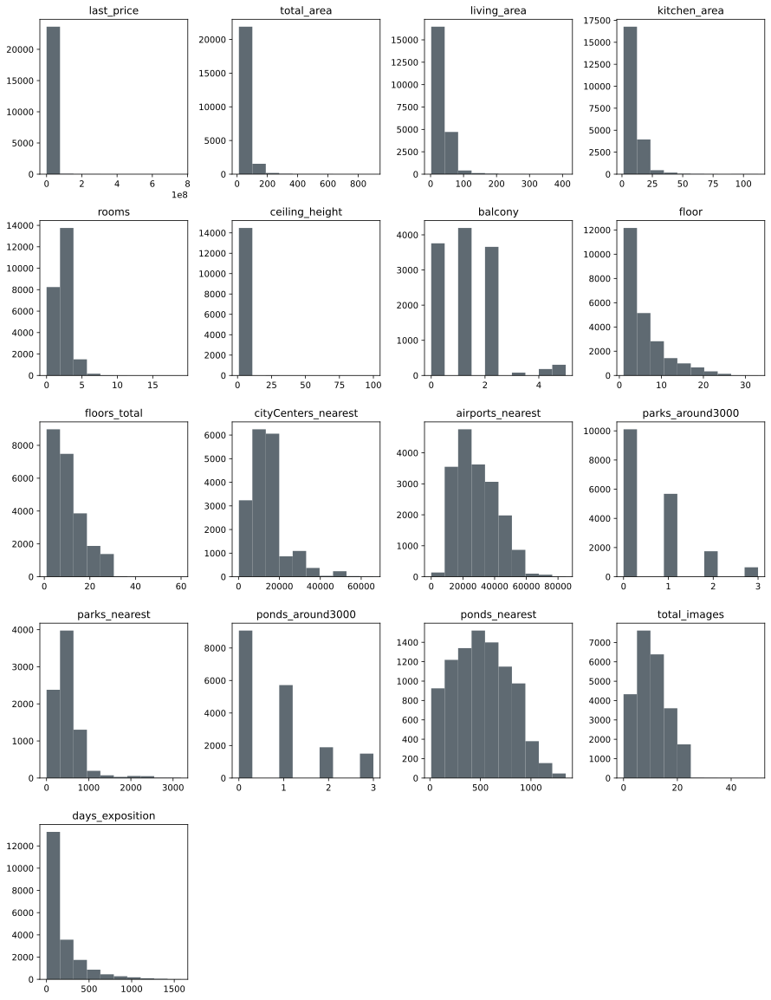

In [7]:
# гистограмма для всех числовых признаков датафрейма
df.hist(figsize=(15,20), grid=False, color='#5f6a72');

**Вывод:** на основании результатов последовательного применения методов `info()`, `describe()` и визуализации гистограммы числовых признаков датафрейма методом `hist()` мы получили информацию для первичного статистического анализа. 

Так, исходный датафрейм содержит 23 699 строк в разрезе 22 признаков: 17 количественных, 4 категориальных и 1 временной. При этом имеются многочисленные пропуски значений, несоответствие типов признаков хранимой информации, а также аномальные и дублирующие значения. Данные существенно загрязнены, требуется проведение комплексной предобработки данных для дальнейшего исследования. Подробная информация о необходимых видах предварительной обработки представлена в таблице ниже.

*Таблица 1. Виды необходимой предварительной обработки данных*

| № п/п | Название               | Наличие пропусков                | Наличие аномалий                                                                          | Изменение типа | Дублирующие записи                              |
|-------|:----------------------------|:--------------------------------------|:----------------------------------------------------------------------------------------|:---------------------|:-----------------------------------------------------|
| 1.    | `locality_name`          | <font color='red'>49 пропусков         | нет                                                                                                  | нет                    | <font color='red'>требуется проверка значений методом `unique()`, высокая вероятность наличия дублей |
| 2.    | `last_price`                | нет                                        | <font color='red'>требуют проверки `max()` значения стоимости 763 000 000 тыс.руб.                                     | нет                    |                                                               | 
| 3.    | `total_area`                | нет                                       | <font color='red'>в большинстве квартир указана площадь порядка 70 $м^2$, требует проверки `max()` значение площади 900 $м^2$ | нет ||
| 4.    | `living_area`               | <font color='red'>1 903 пропуска     | <font color='red'>требуют проверки `min()` и `max()` площади величиной 2.0 и 409.7 $м^2$ соответственно | нет ||
| 5.    | `kitchen_area`            | <font color='red'>2 278 пропусков    | <font color='red'>требуют проверки `max()` площади величиной до 112.0 $м^2$| нет ||
| 6.    | `rooms`                     | нет                                        | <font color='red'>требуют проверки `max()` количество комнат числом 19| нет ||
| 7.    | `ceiling_height`          | <font color='red'>9 195 пропусков    | <font color='red'>требуют проверки `max()` высота потолка 100.0 м при средней высоте 2.65 – 2.80 м | нет ||
| 8.    | `balcony`                   | <font color='red'>11 519 пропусков  | <font color='red'>требуют проверки `max()` количество балконов числом 5|<font color='red'>требуется замена на целочисленный тип данных int64 ||
| 9.    | `is_apartment`           | <font color='red'>20 924 пропуска    | нет |<font color='red'>требуется замена на булев тип данных bool ||
| 10.   | `studio`                    | нет                                        | нет  | нет ||
| 11.   | `open_plan`              | нет                                        | нет | нет ||
| 12.   | `floor`                      | нет                                        | <font color='red'>требуют проверки `max()` 33 этаж | нет ||
| 13.   | `floors_total`             | <font color='red'>86 пропусков        | <font color='red'>требуют проверки `max()` высота здания в 60 этажей | <font color='red'>требуется замена на целочисленный тип данных int64 ||
| 14.   | `cityCenters_nearest` | <font color='red'>5 519 пропусков    | нет | нет ||
| 15.   | `airports_nearest`       | <font color='red'>5 542 пропуска     |<font color='red'>требуют проверки `min()` 0 м до ближайшего аэропорта | нет ||
| 16.   | `parks_around3000`    | <font color='red'>5 518 пропусков   | нет |<font color='red'>требуется замена на целочисленный тип данных int64 |  ||
| 17.   | `parks_nearest`          | <font color='red'>15 620 пропусков  | <font color='red'>требуют проверки `min()` 0 м до ближайшего парка| <font color='red'>требуется замена на целочисленный тип данных int64||
| 18.   | `ponds_around3000`   | <font color='red'>5 518 пропусков   | нет |<font color='red'>требуется замена на целочисленный тип данных int64 ||
| 19.   | `ponds_nearest`          | <font color='red'>14 589 пропусков | нет| <font color='red'>требуется замена на целочисленный тип данных int64||
| 20.   | `total_images`            | нет                                       | нет| нет ||
| 21.   | `first_day_exposition`  | нет                                       | нет| <font color='red'>требуется замена на тип данных дата datetime ||
| 22.   | `days_exposition`        | <font color='red'>3 181 пропуск      |нет | нет ||


<a id=2></a>
## Шаг 2. Предварительная обработка данных

<a id=2.1.></a>
### 2.1. Обработка пропущенных значений

* Определите, в каких столбцах есть пропуски.
* Заполните пропущенные значения там, где это возможно. Например, если продавец не указал число балконов, то, скорее всего, в его квартире их нет. Такие пропуски правильно заменить на 0. Если логичную замену предложить невозможно, то оставьте эти значения пустыми. Пропуски — тоже важный сигнал, который нужно учитывать.
* Укажите причины, которые могли привести к пропускам в данных.

In [8]:
# выявление пропусков значений в признаках
df_missing = pd.DataFrame(columns=['название признака', 'количество пропусков', '% пропущенных значений'])
j = 0
for i, col in enumerate(df.columns):
    percent_missing = np.mean(df[col].isnull())
    value_missing = np.sum(df[col].isnull())
    if percent_missing != 0:
        df_missing.loc[j] = [col, value_missing, (percent_missing*100).round(2)]
        j +=1

print('Таблица 2. Информация о количестве пропусков', '\n\n', df_missing.sort_values(by='количество пропусков', ascending=False))

Таблица 2. Информация о количестве пропусков 

       название признака  количество пропусков  % пропущенных значений
5          is_apartment                 20924                   88.29
10        parks_nearest                 15620                   65.91
12        ponds_nearest                 14589                   61.56
4               balcony                 11519                   48.61
3        ceiling_height                  9195                   38.80
8      airports_nearest                  5542                   23.38
7   cityCenters_nearest                  5519                   23.29
11     ponds_around3000                  5518                   23.28
9      parks_around3000                  5518                   23.28
13      days_exposition                  3181                   13.42
2          kitchen_area                  2278                    9.61
1           living_area                  1903                    8.03
6          floors_total                   

Загрязнения и потери данных в таких больших масштабах обязывают нас разработать стратегию восстановления данных в тех случаях, когда это возможно. В случае невозможности логичной замены, нами будут сохранены пропуски. Рассмотрим данные признаки.

2.1.1. **`is_apartment`** изобилует пропусками: 20 924 или 88.24% потери данных. Этот булев признак соотносит жильё, выставленное на продажу, с типом `апартаменты`. **Решение: заменить `NaN` на `False`, поскольку пользователи, заполнявшие карточку объекта на платформе Яндекс Недвижимость, пренебрегли этими сведениями в силу принадлежности продаваемой недвижимости к типу `квартира`.**


2.1.2. **`locality_name`** обладает самым малым количеством пропусков в данных, таких строк всего 49. Предположим, что причина может заключаться в умозрительной очевидности локации выставленного на продажу имущества, поскольку эта информация является тематическим разделом "Санкт-Петербург" платформы Яндекс Недвижимость. Таким образом, пользователи из Санкт-Петербурга пропустили заполнение этого пункта. Однако, следует учесть значения признака `cityCener_nearest`. В настоящее время приблизительный радиус Санкт-Петербурга составляет порядка 16.5 - 17.0 км, и увеличивается ежегодно за счёт агломерации прилегающих территорий. Следуя этой логике, мы предлагаем следующее **решение: восстановить значение `locality_name` как `Санкт-Петербург` при условии значения признака `'cityCenters_nearest'` <= 17 000 метров.** В остальных случаях стоит оставить пропуски, поскольку, потенциально, мы имеем дело с умышленным искажением данных, в которых продавец недвижимости выдаёт желаемое за действительное, то есть квартиру в Ленинградской области за квартиру на окраине Санкт-Петербурга.


2.1.3. Пропущенные значения по признакам **`airports_nearest`** и **`cityCenters_nearest`** в датафрейме существуют примерно в равном количестве 5 542 и 5 519 строк соответственно, что говорит о наличии системной ошибки при формировании изначальных данных. Предполагаем, что относительно населённого пункта в определённом оптимальном радиусе отсутствует аэропорт, поэтому возник пропуск. Тем не менее, в тех строках, где указано наименование населённого пункта за исключением Санкт-Петербурга, мы можем применить следующее **решение: найти наименование населённого пункта и вручную рассчитать расстояние от него до Санкт-Петербурга и заполнить `cityCenters_nearest` и так же рассчитать расстояние от этого населённого пункта до аэропорта и заполнить `airports_nearest`.**


2.1.4. **`ceiling_height`** не передаёт данные о высоте потолка в 9 195 строках, а это порядка 40% всех записей в датафрейме. В недвижимости до 1955 года постройки высота потолка может варьироваться от 3 до 4 метров. Такими же техническими параметрами в современной России может похвастаться только элитное жильё класса "люкс". Многоквартирные дома второй половины XX века и современные новостройки возводились как массовое и доступное жильё с высотой потолков от 2.1 до 2.6 метров. Пропуски в данных `ceiling_height` могут быть как случайными, так и преднамеренными в случае, если высота потолка маленькая. Мы можем заполнить отсутствующие значения, опираясь на СНиП 2.08.01-89.Жилые здания, нормирующий высоту потолка от пола следующим образом: 1) высота жилых помещений от пола до потолка - 2.5 м - 2.7 м, 2) высота внутриквартирных коридоров (при наличии антресолей) должна быть не менее 2.1 м. Таким образом, у нас формируется вилка высоты потолка от 2.1 м до 2.7 м. Примечательно, что медианное значение высоты потолка во всём датафрейме составляет 2.65 м. **Решение: заполнить пропуски медианными значениями в соответствии с нормативными документами, удалённостью квартиры от центра города.**


2.1.5. **`days_exposition`** имеет значение для изучения тенденций и динамики спроса / предложений на рынке недвижимости. Данные по этому признаку отсутствуют в 3 181 строке. С учётом исчерпывающей полноты данных по признаку `first_day_exposition`, становится очевидной причина пропусков: это сделки по купле-продаже, закрытые в реальности и незакрытые на платформе Яндекс Недвижимость. **Решение: заменим пропущенные значения числа дней размещения объявления групповым средним по конкретному населённому пункту, а остальные значения заполним статистически устойчивой величиной к выбросам - медианой.**


2.1.6. Пары признаков **`parks_nearest`**, **`parks_around3000 `** и **`ponds_nearest`**, **`ponds_around3000`** взаимосвязаны. Равномерные потери в данных в размере 5 518 строк предположительно можно объяснить ошибкой выгрузки, однако, оставшиеся потери порядка 10 000 записей по каждому признаку можем попробовать восстановить по значениям смежных признаков. Также существует вероятность, что данные были пропущены при заполнении сознательно ввиду их малой ценности для пользователя. Однако, тенденции последнего десятилетия свидетельствуют, что значение благоустройства прилегающей территории и экологическая чистота района проживания становятся всё более весомым фактором при выборе места проживания. **Решение: выполним проверку и обработку строк, в которых есть значение `parks_nearest` и пропущено значение `parks_around3000`, и аналогично по `ponds_nearest` и `ponds_around3000`, а также наоборот. Если известно расстояние до объекта, то, следуя логике, рядом имеется 1 парк или 1 пруд. Оставшиеся пропуски по признаку `parks_around3000` и `ponds_around3000` заполним значением `0`, то есть в зоне пешеходной доступности радиусом 3 км нет ни парка, ни пруда, и добраться до зоны рекреации можно только на транспорте. Тогда мы можем заполнить оставшиеся пропуски `park_nearest` и `ponds_nearest` значением `5000`, которое соответствует радиусу 5 км.**


2.1.7. **`balcony`** отсутствуют в 11 519 строках. Самой естественной и логичной причиной представляется отсутствие балкона в квартире. **Решение: заменить `NaN` на `0`.**


2.1.8. Признаки **`kitchen_area`** и **`living_area`** находятся в прямой зависимости от `total_area`, `studio`, `open_plan` и отсутствуют в датафрейме в количестве 2 278 и 1 903 строк соответственно. С высокой вероятностью мы можем предположить, что массовые пропуски в этих признаках являются ожидаемой закономерностью, поскольку многие пользователи довольствуются заполнением признака `total_area`, описывающим общую площадь квартиры. Пропуски в указанных признаках для `studio`, `open_plan` в количестве 50 строк являются также ожидаемыми в связи с потребительскими параметрами жилья такого типа. **Решение: для заполнения пропусков прибегнем к действующим нормативным документам, а именно СП 54.13330.2016, нормирующему жилую площадь квартиры и минимальную площадь кухни в зависимости от числа комнат.**

2.1.9. **`floors_total`** находится во взаимосвязи с признаком `ceiling_height`, и в общем масштабе массива данных показывает малое количество пропусков в данных, всего 86 строк. Мы можем выдвинуть сразу несколько предположений: 1) для пользователя, заполняющего сведения об объекте недвижимости на платформе Яндекс Недвижимость, является очевидным, что это одноэтажное здание в посёлке или деревне Ленинградской области, следовательно, он пренебрегает заполнением этих данных, 2) пользователь умышленно скрывает количество этажей в доме, поскольку, квартира на последнем этаже является потенциальным источником проблем с водоснабжением и крышей, 3) пользователь безотносительно причин пренебрегает заполнением этих данных. **Решение: этажность здания напрямую зависит от его места расположения. Поскольку, исторический центр Санкт-Петербурга - это охранная территория, на которой запрещено высотное строительство, то высотность вновь возводимых зданий потенциально может быть связана с удалённостью от центра города. Мы можем прибегнуть к этой логике при восстановлении пропущенных значений.**

<a id=2.1.1.></a>
#### 2.1.1. Заполнение признака **`'is_apartment'`**

In [9]:
# заменяем NaN на False
df['is_apartment'] = df['is_apartment'].fillna(False)

# выводим уникальные значения признака `is_apartment` после заполнения
list(df['is_apartment'].unique())

[np.False_, np.True_]

In [10]:
# с помощью цепочки методов считаем количество пропусков по этому признаку и проверям полноту заполнения
df['is_apartment'].isna().sum()

np.int64(0)

<a id=2.1.2.></a>
#### 2.1.2. Заполнение признака **`'locality_name'`**

Ранее для заполнения пропусков по признаку `ceiling_height` мы предлагали условное зонирование Санкт-Петербурга на категории в зависимости от удалённости от исторического центра города: 

*Фрагмент таблицы 3. Предлагаемые категории зонирования Санкт-Петербурга и Ленинградской области*

| Радиус, км   | Название категории          | Примерный ориентир по локациям внутри этого диаметра |
|:-------------|:----------------------------|:-----------------------------------------------------|
| > 17         | `Ленинградская область`     | недвижимость, расположенная в городах, посёлках городского типа, посёлках и деревнях на территориях за КАДом (кольцевой автомобильной дорогой вокруг Санкт-Петербурга) |

По признаку `locality_name` в датафрейме отсутствуют данные в 49 строках. Здесь же имеется информация об удалённости от центра города `'cityCenters_nearest'`. Следовательно, мы можем безопасно восстановить значение  `locality_name` как `Санкт-Петербург` при условии значения признака `'cityCenters_nearest'` <= 17 000 метров. Остальные пропуски по этому признаку корректному восстановлению не подлежат.

In [11]:
# расчитаем количество пропусков по признаку `locality_name`
df['locality_name'].isna().sum()

np.int64(49)

In [12]:
# создадим группировку с пропущенными значениями 'locality_name' и имеющимися данными по 'cityCenters_nearest'
df[(df['locality_name'].isnull())][['locality_name', 'cityCenters_nearest']].head()

,locality_name,cityCenters_nearest
1097,NaN,4258.0
2033,NaN,NaN
2603,NaN,17369.0
2632,NaN,17369.0
3574,NaN,8127.0


In [13]:
# заполняем пропуски в тех строках, где удалённость от центра не более 17 000 м
df.loc[(df['locality_name'].isna()) & (df['cityCenters_nearest'] < 17000), 'locality_name'] = 'Санкт-Петербург'

In [14]:
# заполняем пропуски в тех строках, где расстояние до аэропорта меньше либо равно 15692.6665
# это километраж, характерный для Санкт-Петербурга
df.loc[(df['airports_nearest'] <= 15692.6665) & (df['locality_name'].isna()), 'locality_name'] = 'Санкт-Петербург'

In [15]:
# проверка заполнения признака новыми данными
df['locality_name'].isna().sum()

np.int64(20)

In [16]:
# соотнесём сроки с пропущенными значениями в наименовании населённого пункта и имеющимися данными по расстоянию до ближайшего центра города
df.loc[(df['locality_name'].isna())]['cityCenters_nearest']

2033         NaN
2603     17369.0
2632     17369.0
6765     17369.0
8986     31813.0
13223    17369.0
13690    23659.0
14273    17369.0
14342        NaN
16499    17369.0
17535        NaN
19972    17369.0
20382        NaN
20590        NaN
21119    31897.0
21276    41294.0
21715        NaN
21898        NaN
22717        NaN
22933    17369.0
Name: cityCenters_nearest, dtype: float64

Мы видим, что у нас осталось всего 20 строк с пропущенными значениями признака. Поскольку для нас данные, даже в таком загрязнённом виде, представляют ценность, постараемся вручную восстановить значения в соответствии с логикой и следующим километражом:

In [17]:
# заполняем пропуски в тех строках, где удалось установить километраж и наименование населённого пункта
df.loc[(df['locality_name'].isna()) & (df['cityCenters_nearest'] == 17369.00), 'locality_name'] = 'Санкт-Петербург'
df.loc[(df['locality_name'].isna()) & (df['cityCenters_nearest'] == 41294.00), 'locality_name'] = 'деревня Агалатово'
df.loc[(df['locality_name'].isna()) & (df['cityCenters_nearest'] == 23659.00), 'locality_name'] = 'Всеволожск'
df.loc[(df['locality_name'].isna()) & (df['cityCenters_nearest'] == 31813.00), 'locality_name'] = 'Отрадное'
df.loc[(df['locality_name'].isna()) & (df['cityCenters_nearest'] == 31897.00), 'locality_name'] = 'посёлок Ленинское'

In [18]:
# проверка заполнения признака новыми данными
df['locality_name'].isna().sum()

np.int64(8)

In [19]:
# удаляем 12 строк с пропусками по списку индексов
locality_name_isna = df.query('locality_name .isna()')
locality_name_isna_index = locality_name_isna.index
df.drop(locality_name_isna_index, inplace=True)

In [20]:
# проверка заполнения признака новыми данными
df['locality_name'].isna().sum()

np.int64(0)

<a id=2.1.3.></a>
#### 2.1.3. Заполнение признака **`'airports_nearest'`** и **`'cityCenters_nearest'`**

По этим двум признакам данные пропущены в 5 542 и 5 519 строках соответственно. Проверим одновременное отсутствие обоих значений в строках датафрейма.

In [21]:
# одновременное отсутствие обоих значений в строках датафрейма
df.query('airports_nearest != airports_nearest and cityCenters_nearest != cityCenters_nearest').shape[0]

5510

Итак, одновременно оба признака пропущены в 5 510 строках датафрейма. Предположим, что объекты недвижимого имущества, расположенные в одном населённом пункте, будут примерно одинаково удалены от ближайшего аэропорта.

In [22]:
# заполняем пропуски средним значением по конкретному населённому пункту
df['airports_nearest'] = df.groupby('locality_name')['airports_nearest'].transform(lambda x: x.fillna(x.mean()))

In [23]:
# подсчитаем оставшееся количество пропусков
df['airports_nearest'].isna().sum()

np.int64(4902)

In [24]:
# выводим результат для ознакомления
df[df['locality_name'] != 'Санкт-Петербург'][['locality_name', 'cityCenters_nearest', 'airports_nearest']].head(10)

,locality_name,cityCenters_nearest,airports_nearest
1,посёлок Шушары,18603.0,12817.0
5,городской посёлок Янино-1,NaN,NaN
6,посёлок Парголово,19143.0,52996.0
8,посёлок Мурино,NaN,NaN
11,Ломоносов,51677.0,48252.0
12,Сертолово,NaN,NaN
13,Петергоф,33058.0,37868.0
14,Пушкин,30759.0,20782.0
20,посёлок Парголово,19311.0,53134.0
22,деревня Кудрово,NaN,NaN


In [25]:
# проверка заполнения признаков новыми данными по расстояниям до центра и до аэропорта
df[['airports_nearest', 'cityCenters_nearest']].isna().sum()

airports_nearest       4902
cityCenters_nearest    5511
dtype: int64

In [26]:
# выясним название населённого пунка в оставшихся пропусках
df[df['airports_nearest'].isna()]['locality_name'].unique()

array(['городской посёлок Янино-1', 'посёлок Мурино', 'Сертолово',
       'деревня Кудрово', 'Коммунар',
       'поселок городского типа Красный Бор', 'Гатчина',
       'деревня Фёдоровское', 'Выборг', 'Кировск',
       'деревня Новое Девяткино', 'посёлок городского типа Лебяжье',
       'посёлок городского типа Сиверский', 'поселок Молодцово',
       'поселок городского типа Кузьмоловский',
       'садовое товарищество Новая Ропша', 'деревня Пикколово', 'Волхов',
       'Кингисепп', 'Приозерск', 'деревня Куттузи', 'посёлок Аннино',
       'поселок городского типа Ефимовский', 'посёлок Плодовое',
       'деревня Заклинье', 'поселок Торковичи', 'поселок Первомайское',
       'Сясьстрой', 'деревня Старая', 'деревня Лесколово',
       'посёлок Новый Свет', 'Сланцы', 'село Путилово', 'Ивангород',
       'Мурино', 'Шлиссельбург', 'Никольское', 'Сосновый Бор',
       'поселок Новый Свет', 'деревня Оржицы', 'деревня Кальтино',
       'Кудрово', 'поселок Романовка', 'посёлок Бугры', 'поселок Б

In [27]:
# выясним название населённого пунка по которому есть пропуски по ближайшему городскому центру
df[df['cityCenters_nearest'].isna()]['locality_name'].unique()

array(['городской посёлок Янино-1', 'посёлок Мурино', 'Сертолово',
       'деревня Кудрово', 'Коммунар',
       'поселок городского типа Красный Бор', 'Гатчина', 'поселок Мурино',
       'деревня Фёдоровское', 'Выборг', 'Кировск',
       'деревня Новое Девяткино', 'Санкт-Петербург',
       'посёлок городского типа Лебяжье',
       'посёлок городского типа Сиверский', 'поселок Молодцово',
       'поселок городского типа Кузьмоловский',
       'садовое товарищество Новая Ропша', 'деревня Пикколово',
       'Всеволожск', 'Волхов', 'Кингисепп', 'Приозерск',
       'деревня Куттузи', 'посёлок Аннино',
       'поселок городского типа Ефимовский', 'посёлок Плодовое',
       'деревня Заклинье', 'поселок Торковичи', 'поселок Первомайское',
       'Сясьстрой', 'деревня Старая', 'деревня Лесколово',
       'посёлок Новый Свет', 'Сланцы', 'село Путилово', 'Ивангород',
       'Мурино', 'Шлиссельбург', 'Никольское', 'Сосновый Бор',
       'поселок Новый Свет', 'деревня Оржицы', 'деревня Кальтино',
 

In [28]:
# вручную заполним пропуск по городу Пушкин, расстояние от него до Санкт-Петербурга равно 25200.0000
df.loc[(df['cityCenters_nearest'].isna()) & (df['locality_name'] == 'Пушкин'), 'cityCenters_nearest'] = 25200.0000

In [29]:
# вручную заполним пропуск по городу Санкт-Петербург в части расстояния до аэропорта Пулково, равное 15692.6665
df.loc[(df['airports_nearest'].isna()) & (df['locality_name'] == 'Санкт-Петербург'), 'airports_nearest'] = 15692.6665

In [30]:
# заполним пропуски по городу Санкт-Петербург в части расстояния центра города медианым значением для этого города
df.loc[(df['cityCenters_nearest'].isna()) & (df['locality_name'] == 'Санкт-Петербург'), 
       'cityCenters_nearest'] = df.loc[df['locality_name'] == 'Санкт-Петербург']['cityCenters_nearest'].median()

In [31]:
# оставшиеся пропуски значений 'airports_nearest' заполним числом максимального расстояния
# исходя из следующей логики: аэропорт находится настолько далеко от населённого пункта, что нет смысла указывать километраж
max_dist = df['airports_nearest'].max()
df['airports_nearest'].fillna(max_dist, inplace = True)

In [32]:
# проверка заполнения признаков новыми данными по расстояниям до аэропорта
df[['airports_nearest', 'cityCenters_nearest']].isna().sum()

airports_nearest          0
cityCenters_nearest    5449
dtype: int64

Восполнение пропусков по признаку `cityCenters_nearest` будет выполнено в той же последовательности и логике: если у нас имеются данные по наименованию населённого пункта, в котором продаётся объект, то соответствующее значение удалённости до ближайшего городского центра мы заполним групповым средним известных нам расстояний до центра в этом населённом пункте. Оставшимся пропущенным значениям будет присвоено максимальное значение расстояния.

In [33]:
# заполняем расстояние до городского центра средним значением в соответствии с наименованием населённого пункта 
df['cityCenters_nearest'] = df.groupby('locality_name')['cityCenters_nearest'].transform(lambda x: x.fillna(x.mean()))

In [34]:
# проверям заполнение пропусков по этому признаку
df['cityCenters_nearest'].isna().sum()

np.int64(4902)

In [35]:
# Оставшиеся значения по признаку cityCenters_nearest заполняем максимальным расстоянием до центра. 
max_dist = df['cityCenters_nearest'].max()
df['cityCenters_nearest'].fillna(max_dist, inplace = True)

In [36]:
df[['airports_nearest', 'cityCenters_nearest']].isna().sum()

airports_nearest       0
cityCenters_nearest    0
dtype: int64

<a id=2.1.4.></a>
#### 2.1.4. Заполнение признака **`'ceiling_height'`**

Высота потолка от пола нормируется СНиП 2.08.01-89. Жилые здания, СНиП 31-01-2003. Здания жилые многоквартирные, но это далеко не исчерпывающий перечень нормативной документации по данному вопросу. Ряд документов устанавливает следующие нормы в части возведени жилых многоквартирных зданий:
* В тёплых климатических зонах потолок должен располагаться на высоте не менее 2.7 метра
* Для остальных регионов России **минимальная** высота потолка составляет 2.5 метра
* В проходных помещениях (например, коридорах) высота потолка может быть снижена до 2.1 метра 

**Максимальная** высота потолка нормативными документами не ограничивается. Дополнительно нами рассчитано медианное значение высоты потолка 2.65 м, характерное для текущего датафрейма.

**Решение:** заполнить пропуски медианными значениями в соответствии с нормативными документами, удалённостью квартиры от центра города.

In [37]:
# выясним количество пропусков по высоте потолка
df['ceiling_height'].isnull().sum()

np.int64(9189)

В зависимости от удалённости недвижимости от центра, содержащейся в признаке `cityCenters_nearest`, попробуем разделить строки по категориям, вычислить среднее значение высоты потолков в каждой категории и этим значением заполнить пропуски по условию.

*Таблица 3. Предлагаемые категории зонирования Санкт-Петербурга и Ленинградской области*

| Радиус, км   | Название категории          | Примерный ориентир по локациям внутри этого диаметра |
|:-------------|:----------------------------|:-----------------------------------------------------|
| 0 - 2.5      | `исторический центр города` | Дворцовая набережная, набережная реки Фонтанки       |
| 2.5 - 6      | `центральные районы города` | Василеостровский р-н, Петроградский р-н, Московсий, Витебский, Финляндский вокзалы |
| 6 - 12       | `удалённые районы города`   | Купчино, Янино-1, Ладожский вокзал, Фильмофонд, стадион Химик |
| 12 - 17      | `пригородные районы`        | Парголово, Пушкин, Новое Девяткино, Зеленогорск |
| > 17         | `Ленинградская область`     | недвижимость, расположенная в городах, посёлках городского типа, посёлках и деревнях на территориях за КАДом (кольцевой автомобильной дорогой вокруг Санкт-Петербурга) |

In [38]:
# создадим функцию для создания категорий жилья в зависимости от удалённости от центра города
def ceiling_height(row):
    if row['cityCenters_nearest'] < 2500:
        return 'исторический центр города'
    elif row['cityCenters_nearest'] < 6000:
        return 'центральные районы города'
    elif row['cityCenters_nearest'] < 12000:
        return 'удалённые районы города'
    elif row['cityCenters_nearest'] < 17000:
        return 'пригородные районы'
    elif row['cityCenters_nearest'] >= 17000:
        return 'Ленинградская область'

In [39]:
# применим эту функцию и создадим новый признак
df['cityCenters_category'] = df.apply(ceiling_height, axis=1)

In [40]:
# выведем для озакомления полученные значения
df[['locality_name', 'cityCenters_nearest', 'cityCenters_category']].head()

,locality_name,cityCenters_nearest,cityCenters_category
0,Санкт-Петербург,16028.0,пригородные районы
1,посёлок Шушары,18603.0,Ленинградская область
2,Санкт-Петербург,13933.0,пригородные районы
3,Санкт-Петербург,6800.0,удалённые районы города
4,Санкт-Петербург,8098.0,удалённые районы города


Теперь в соответствии с созданными категориями жилья, рассчитаем медианное значение высоты потолка в каждой из полученных категорий и заполним пропуски в признаке `ceiling_height` соответствующими значениями. Безусловно, речь не идёт о строках, где остались пропуски `NaN` в признаке `cityCenters_nearest`.

In [41]:
# заполняем медианным значением высоты потолка пропуски по каждой категории удалённости жилья
df.groupby('cityCenters_category')['ceiling_height'].median().sort_values(ascending=False).to_frame()

,ceiling_height
cityCenters_category,
исторический центр города,3.2
центральные районы города,3.0
удалённые районы города,2.7
Ленинградская область,2.6
пригородные районы,2.6


In [42]:
# заполняем медианными знаяениями высоту потолка, характерную для каждого типа удалённости от Сантк-Петербурга
medians = df.groupby('cityCenters_category')['ceiling_height'].transform('median')
df['ceiling_height'] = df['ceiling_height'].fillna(medians)

In [43]:
# выведем для озакомления полученные значения
df.head()

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition,cityCenters_category
0,Санкт-Петербург,13000000.0,108.0,51.0,25.0,3,2.70,NaN,False,False,...,16028.0,18863.0,1.0,482.0,2.0,755.0,20,2019-03-07T00:00:00,NaN,пригородные районы
1,посёлок Шушары,3350000.0,40.4,18.6,11.0,1,2.60,2.0,False,False,...,18603.0,12817.0,0.0,NaN,0.0,NaN,7,2018-12-04T00:00:00,81.0,Ленинградская область
2,Санкт-Петербург,5196000.0,56.0,34.3,8.3,2,2.60,0.0,False,False,...,13933.0,21741.0,1.0,90.0,2.0,574.0,10,2015-08-20T00:00:00,558.0,пригородные районы
3,Санкт-Петербург,64900000.0,159.0,NaN,NaN,3,2.70,0.0,False,False,...,6800.0,28098.0,2.0,84.0,3.0,234.0,0,2015-07-24T00:00:00,424.0,удалённые районы города
4,Санкт-Петербург,10000000.0,100.0,32.0,41.0,2,3.03,NaN,False,False,...,8098.0,31856.0,2.0,112.0,1.0,48.0,2,2018-06-19T00:00:00,121.0,удалённые районы города


In [44]:
# проверка заполнения признака новыми данными
df['ceiling_height'].isna().sum()

np.int64(0)

<a id=2.1.5.></a>
#### 2.1.5. Заполнение признака **`'days_exposition'`** 

Никаких оригинальных предположений относительно заполнения пропущенных значений этого признака нет. Применим все ту же стратегию: если известен населенный пункт, то заменим пропущенные значения числа дней размещения объявления групповым средним по этому населенному пункту; остальные значения заполним медианой, как более устойчивой к выбросам.

In [45]:
# выясним количество пропусков по длительности размещения объявления
df['days_exposition'].isna().sum()

np.int64(3180)

In [46]:
# заменим пропуски на средние значения в соответствии с названием каждого населённого пункта
df['days_exposition'] = df.groupby('locality_name')['days_exposition'].transform(lambda x: x.fillna(x.mean()))

После применения лямбда-функции в массиве данных осталось 100 населённых пунктов, представленных единичными объявлениями, по которым группировка данных и расчёт медианы невозможен. Предлагаем заполнить оставшиеся пропуски общей медианой данных по всему массиву.

In [47]:
# заполнение оставшихся пропусков по `days_exposition` общей медианой
median_exp = df['days_exposition'].median()
df['days_exposition'].fillna(median_exp, inplace = True)

In [48]:
# проверка заполнения признака новыми данными
df['days_exposition'].isnull().sum()

np.int64(0)

<a id=2.1.6.></a>
#### 2.1.6. Заполнение признаков **`'parks_nearest'`**, **`'parks_around3000'`**, **`'ponds_nearest'`**, **`'ponds_around3000'`**

По умолчанию платформой Яндекс Недвижимость установлено условие попадания парка или водоёма в радиус 3 км от квартиры. Проверим данные на соответствие этому условию.

In [49]:
# парки за пределом радиуса 3 км от квартиры
df[df.parks_nearest > 3000]['parks_nearest'].value_counts()

parks_nearest
3190.0    2
3064.0    1
3013.0    1
Name: count, dtype: int64

Итак, в общем объёме данных имеются 4 парка с удалённостью более `3000` метров от квартиры. Разница между предустановленным системой значением и показателем, внесённым в систему пользователем, чрезвычайно мала и составляет диапазон от 13 до 190 метров. На этом основании полагаем возможным заменить эти значения на `3000`. Все данные по водоёмам корректные, замены не требуется.

In [50]:
# применим метод .where() с заменой значений
df.parks_nearest.where(df.parks_nearest.isna() | (df.parks_nearest <=3000), other=3000, inplace=True)

# парки за пределом радиуса 3 км от квартиры
df[df.parks_nearest > 3000]['parks_nearest'].value_counts()

Series([], Name: count, dtype: int64)

Мы скорректировали предельные значения радиуса наличия парка и водоёма рядом с квартирой. Теперь мы проверим наличие строк, в которых значение `parks_around3000` пропущено, но есть данные о расстоянии до парка `parks_nearest`. Если такие записи есть, то для них присвоим признаку `parks_around3000` значение `1`.

In [51]:
# проверка для выявления пропусков по условию
mis_val_parks = df[df.parks_nearest.notna()]['parks_around3000'].isna().sum()

if mis_val_parks != 0:
    df.parks_around3000 = df[df.parks_nearest.notna()].parks_around3000.fillna(1)
    print('Такие строки есть. Заполнено{: d} значений признака `parks_around3000`.'.format(mis_val_parks))
else:
    print('Таких строк нет.')

Таких строк нет.


Выполним проверку условия выше в обратном направлении. Проверим наличие строк, в которых имеются данные о наличии парков в радиусе 3 км `parks_around3000` и при этом пропущено значение по признаку `park_nearest`. Заполним такие строки значением `3000`.

In [52]:
# проверка обратного условия
mis_val_parks = df[df.parks_around3000.notna()]['parks_nearest'].isna().sum()

if mis_val_parks != 0:
    df.parks_nearest = df[df.parks_around3000.notna()].parks_nearest.fillna(3000)
    print('Такие строки есть. Заполнено{: d} значений по признаку `parks_nearest`.'.format(mis_val_parks))
else:
    print('Таких строк нет.')

Такие строки есть. Заполнено 10102 значений по признаку `parks_nearest`.


In [53]:
df[['parks_nearest', 'parks_around3000']].isna().sum()

parks_nearest       5510
parks_around3000    5510
dtype: int64

Оставшиеся пропуски по признаку `parks_around3000` заполним значением `0`, то есть в зоне пешеходной доступности радиусом 3 км нет парка и добраться до зоны рекреации можно только на транспорте. Тогда мы можем заполнить оставшиеся пропуски `park_nearest` значением `5000`, которое соответствует радиусу 5 км. Проверим результат выполненных операций.

In [54]:
# замена признака наличия парка на 0
df['parks_around3000'].fillna(0, inplace=True)

In [55]:
# замена признака расстояния до ближайшего парка на 5 км
df['parks_nearest'].fillna(5000, inplace=True)

In [56]:
# проверка заполнения признаков новыми данными по паркам
df[['parks_nearest', 'parks_around3000']].isna().sum()

parks_nearest       0
parks_around3000    0
dtype: int64

Повторим тот же алгоритм обработки в отношении пары признаков `ponds_nearest` и `ponds_around3000`. Для начала проверим соответствие признака предустановленному рубежу в 3 км.

In [57]:
# пруды за пределом радиуса 3 км от квартиры
df[df.ponds_nearest > 3000]['ponds_nearest'].value_counts()

Series([], Name: count, dtype: int64)

Все водоёмы находятся в радиусе 3 км от выставленной на продажу недвижимости. Обработки данных по этому признаку не требуется. Теперь мы проверим наличие строк, в которых значение `ponds_around3000` пропущено, но есть данные о расстоянии до водоёма `ponds_nearest`. Если такие записи есть, то для них присвоим признаку `ponds_around3000` значение `1`.

In [58]:
# проверка на наличие оставшихся пропусков
mis_val_ponds = df[df.ponds_nearest.notna()]['ponds_around3000'].isna().sum()

if mis_val_ponds != 0:
    df.ponds_around3000 = df[df.ponds_nearest.notna()].ponds_around3000.fillna(1)
    print('Такие строки есть. Заполнено{: d} значений признака `ponds_around3000`.'.format(mis_val_parks))
else:
    print('Таких строк нет.')

Таких строк нет.


Выполним проверку условия выше в обратном направлении. Проверим наличие строк, в которых имеются данные о наличии парков в радиусе 3 км `parks_around3000` и при этом пропущено значение по признаку `park_nearest`. Заполним такие строки значением `3000`.

In [59]:
# проверка обратного условия
mis_val_ponds = df[df.ponds_around3000.notna()]['ponds_nearest'].isna().sum()

if mis_val_ponds != 0:
    df.ponds_nearest = df[df.ponds_around3000.notna()].ponds_nearest.fillna(3000)
    print('Такие строки есть. Заполнено{: d} значений признака `ponds_nearest`.'.format(mis_val_ponds))
else:
    print('Таких строк нет.')

Такие строки есть. Заполнено 9071 значений признака `ponds_nearest`.


Оставшиеся пропуски по признаку `parks_around3000` заполним значением `0`, то есть в зоне пешеходной доступности радиусом 3 км нет парка и добраться до зоны рекреации можно только на транспорте. Тогда мы можем заполнить оставшиеся пропуски `park_nearest` значением `5000`, которое  соответствует радиусу 5 км. Проверим результат выполненных операций.

In [60]:
# замена признака наличия парка на 0
df['ponds_around3000'].fillna(0, inplace=True)

In [61]:
# замена признака расстояния до ближайшего парка на 5000 м
df['ponds_nearest'].fillna(5000, inplace=True)

In [62]:
# проверка заполнения признаков новыми данными по водоёмам
df[['ponds_nearest', 'ponds_around3000']].isna().sum()

ponds_nearest       0
ponds_around3000    0
dtype: int64

<a id=2.1.7.></a>
#### 2.1.7. Заполнение признака **`'balcony'`**

Поскольку самой естественной и логичной причиной представляется отсутствие балкона в квартире, заполним пропуски по признаку `balcony` значением `0`.

In [63]:
# замена пропусков на нулевое значение
df.balcony.fillna(0, inplace=True)

In [64]:
# проверка заполнения признака новыми данными
df['balcony'].isna().sum()

np.int64(0)

<a id=2.1.8.></a>
#### 2.1.8. Заполнение признака **`'kitchen_area'`** и **`'living_area'`**

Количество пропусков по этим признакам в датафрейме достигает значений 2 278 и 1 903 строк соответственно. На первый взгляд, потеря этих данных может показаться несущественной, однако, для анализа рынка недвижимости эти параметры являются ключевыми в формировании рейтинга недвижимости. Существующие пропуски по обоим признакам не могут быть заполнены нулями, равно как и не могут быть рассчитаны как разница между общей площадью квартиры и другими признаками ввиду существования технических и вспомогательных помещений, площадь которых в датафрейме не фигурирует.

Прибегнем к действующим нормативным документам, а именно СП 54.13330.2016, нормирующему жилую площадь квартиры и минимальную площадь кухни в зависимости от числа комнат `rooms`. Согласно пункту 5.2 "Требования к зданиям и помещениям" СП 54.13330.2016 в многоквартирных зданиях государственного жилищного фонда минимальные площади квартир и число их комнат рекомендуется принимать в соответствии с таблицей ниже:

*Таблица 4. Минимальные требования по площади квартир и числу комнат*

| Число комнат:                        | 1       | 2       | 3       | 4       | 5       | 6         |
|:-------------------------------------|---------|---------|---------|---------|---------|-----------|
| Рекомендуемая площадь квартир, $м^2$ | 28 - 38 | 44 - 53 | 56 - 65 | 70 - 77 | 84 - 96 | 103 - 109 |

*Таблица 5. Минимальные требования по площади кухни и числу комнат*

| Число комнат:                      | 1 | 2 и больше |
|:-----------------------------------|---|---|
| Рекомендуемая площадь кухни, $м^2$ | 5 | 6 и больше |

Минимальная площадь сантехнического помещения в квартире колеблется от 2.5 до 3.3 м, и это необходимо учесть при проверке площадей. 

В датафрейме присутствуют данные по квартирам с нулевым количеством комнат. Это характерный признак, который выявляет квартиры-студии `studio` и квартиры с открытой планировкой `open_plan`. Заменять `0` на `1` в данных случаях будет неправомерным, поскольку это противоречит существующей нормативной правовой документации. Последовательно заполним все пропуски минимальными значениями в соответствии с нормативами.

In [65]:
# заполним пропуски признака `kitchen_area` для:
# квартир-студий и квартир с открытой планировкой и 1-комнатных квартир
df.loc[(df['rooms'] <= 1) & (df['kitchen_area'].isna()), 'kitchen_area'] = 5

In [66]:
# заполним пропуски признака `kitchen_area` для остальных квартир
df.loc[(df['rooms'] > 1) & (df['kitchen_area'].isna()), 'kitchen_area'] = 6

In [67]:
# заполним пропуски признака `living_area` для квартир за вычетом минимальных 2.5 кв.м сантехнических помещений 
df.loc[(df['rooms'] <= 1) & (df['living_area'].isna()), 'living_area'] = 25.5
df.loc[(df['rooms'] <= 2) & (df['living_area'].isna()), 'living_area'] = 41.5
df.loc[(df['rooms'] <= 3) & (df['living_area'].isna()), 'living_area'] = 53.5
df.loc[(df['rooms'] <= 4) & (df['living_area'].isna()), 'living_area'] = 67.5
df.loc[(df['rooms'] <= 5) & (df['living_area'].isna()), 'living_area'] = 81.5
df.loc[(df['rooms'] > 5) & (df['living_area'].isna()), 'living_area'] = 100.5

In [68]:
# проверка заполнения признаков новыми данными
df[['kitchen_area', 'living_area']].isna().sum()

kitchen_area    0
living_area     0
dtype: int64

<a id=2.1.9.></a>
#### 2.1.9. Заполнение признака **`'floors_total'`**

Этажность многоквартирного жилого здания напрямую зависит от его места расположения и даты постройки. Поскольку, исторический центр Санкт-Петербурга - это охранная территория, на которой запрещено высотное строительство, то и высотность вновь возводимых жилых зданий зависит от удалённости от исторического центра города. Мы можем прибегнуть к этой логике при восстановлении пропущенных значений и повторить алгоритм действий заполнения пропусков признака `ceiling_height`.

In [69]:
# выясним количество пропусков по этажности здания
df['floors_total'].isnull().sum()

np.int64(86)

Рассчитаем медианное значение этажности здания в соответствии с созданными зонами удалённости объектов недвижимости. Заполним пропущенные значения в признаке `floors_total` там, где это возможно и есть информация по признаку `cityCenters_nearest`.

In [70]:
# заполняем медианным значением этажности здания пропуски по каждой категории удалённости жилья
df.groupby('cityCenters_category')['floors_total'].median().sort_values(ascending=False).to_frame()

,floors_total
cityCenters_category,
пригородные районы,12.0
удалённые районы города,9.0
Ленинградская область,7.0
центральные районы города,6.0
исторический центр города,5.0


In [71]:
# заполняем пропуски медианной этажностью здания в соответствии с категорией удалённости от Санкт-Петербурга 
medians = df.groupby('cityCenters_category')['floors_total'].transform('median')
df['floors_total'] = df['floors_total'].fillna(medians)

In [72]:
# проверка заполнения признака новыми данными
df['floors_total'].isna().sum()

np.int64(0)

In [73]:
# подведём итоги по заполнению пропусков в датафрейме
df.isna().sum().sort_values(ascending=False)

locality_name           0
last_price              0
total_area              0
living_area             0
kitchen_area            0
rooms                   0
ceiling_height          0
balcony                 0
is_apartment            0
studio                  0
open_plan               0
floor                   0
floors_total            0
cityCenters_nearest     0
airports_nearest        0
parks_around3000        0
parks_nearest           0
ponds_around3000        0
ponds_nearest           0
total_images            0
first_day_exposition    0
days_exposition         0
cityCenters_category    0
dtype: int64

In [74]:
# размер массива данных по итогам обработки пропусков
df.shape

(23691, 23)

**Вывод по возможным причинам появления пропусков:**

В целях выявления пропусков значений в признаках была реализована цепочка методов `isna()`, `sum()`, `sort_values()`, а также создан `heatmap` для визуализации полученных результатов. Из общего количества значений по всем признакам числом 521 378, в датафрейме отсутствует 101 441 значение (или 19,46%) в разрезе 14 признаков, и только 8 признаков обладают полным набором данных.

В связи со значительным загрязнением данных, была разработана и реализована комплексная стратегия заполнения пропущенных значений. Так, по некоторым признакам нам удалось восстановить естественные данные, или восполнить пропуски логически восстановленными значениями или синтетическими данными - минимальными нормативными значениями с учётом МОП (мест общего пользования).

Из числа возможных причин появления пропусков мы можем обозначить следующие:

* Ошибка выгрузки данных (пропуски по парам признаков `parks_nearest`, `parks_around3000` в равном количестве строк).

* Значение не было указано пользователем при заполнении карточки объекта на платформе Яндекс Недвижимость в виду очевидных для него истин: балкона - нет; квартира - в Санкт-Петербурге; квартира - это не апартаменты в люксовом жилом комплексе с охраняемой территорией, своим парком и бесcменным консьержем на входной группе (`balcony`, `locality_name`, `is_apartment`).

* Значение не было указано пользователем умышленно в целях сокрытия негативных пользовательских характеристик жилья: квартира - не в Санкт-Петербурге, а в пригороде, а то и вовсе в Ленинградской области; ближайший сосед - шумный аэропорт "Пулково", этаж - первый или последний, что ставит ребром вопрос безопасности проживания или вопрос сохранности имущества в случае слабого напора воды, коммунальной аварии и сезонно протекающей крыши; а высота потолка в 2.1 метра вызывает острое желание перейти к просмотру следующего объявления (`locality_name`, `airports_nearest`, `floors_total`, `ceiling_height`). В эту же группу характеристик попадают признаки `kitchen_area` и `living_area`, которые своими малыми значениями могут оттолкнуть потенциального покупателя. 

* В соответствующей ячейке признака данные введены с механической ошибкой или введены корректно, но в ошибочную ячейку, упущен знак десятичной дроби (`ceiling_height`, `kitchen_area`, `living_area`).

* У пользователя нет объективных данных для корректного заполнения объявления о продаже либо он попросту пренебрегает этими данными в виду их малой значимости для него (`airports_nearest`, `cityCenters_nearest`, `parks_nearest`, `ponds_nearest`, `parks_around3000`, `ponds_around3000`). А для соответствующей целевой аудитории вопрос экологической благонадёжности района проживания стоит на первом месте, но эти объявления остаются без внимания из-за таких пропущенных значений.

* В `days_exposition` 3 181 объявление так и не было закрыто. С большой долей вероятности в реальности сделка по купле-продаже состоялась, но карточка объявления так и не была снята на платформе Яндекс Недвижимость.

<a id=2.2.></a>
### 2.2. Обработка типов данных

* Найдите столбцы, в которых нужно изменить тип данных.
* Преобразуйте тип данных в выбранных столбцах.
* Поясните, почему нужно изменить тип данных

In [75]:
# удаляем оставшиеся пропуски
df = df.dropna()

In [76]:
# сбрасываем индекс датафрейма
df = df.reset_index(drop=True)

Требуется преобразование следующих типов признаков:
    
* число этажей в здании
* расстояние до ближайшего парка в метрах
* расстояние до ближайшего водоёма в метрах
* количество парков в радиусе 3 км от объекта
* количество водоёмов в радиусе 3 км от объекта
* количество балконов
* принадлежность к типу недвижимости `апартаменты`

Все вышеперечисленные признаки описываются целочисленными значениями.

* день размещения объявления о продаже

содержит информацию особого типа, описывающую дату и время публикации объявления. Системой было предустановлено сохранение сведений только о дате, поэтому значения времени отсутствуют.

In [77]:
# преобразование типов данных
df['floors_total'] = df['floors_total'].astype(int)
df['balcony'] = df['balcony'].astype(int)
df['parks_nearest'] = df['parks_nearest'].astype(int)
df['ponds_nearest'] = df['ponds_nearest'].astype(int)
df['parks_around3000'] = df['parks_around3000'].astype(int)
df['ponds_around3000'] = df['ponds_around3000'].astype(int)
df['is_apartment'] = df['is_apartment'].astype(bool)
df['first_day_exposition'] = pd.to_datetime(df['first_day_exposition'], format='%Y-%m-%dT%H:%M:%S')

In [78]:
# выполняем проверку результата преобразования типов данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23691 entries, 0 to 23690
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   locality_name         23691 non-null  object        
 1   last_price            23691 non-null  float64       
 2   total_area            23691 non-null  float64       
 3   living_area           23691 non-null  float64       
 4   kitchen_area          23691 non-null  float64       
 5   rooms                 23691 non-null  int64         
 6   ceiling_height        23691 non-null  float64       
 7   balcony               23691 non-null  int64         
 8   is_apartment          23691 non-null  bool          
 9   studio                23691 non-null  bool          
 10  open_plan             23691 non-null  bool          
 11  floor                 23691 non-null  int64         
 12  floors_total          23691 non-null  int64         
 13  cityCenters_near

<a id=2.3.></a>
### 2.3. Обработка дубликатов

In [79]:
# выведем уникальные значения признака с наименованиями населённых пунктов
df['locality_name'].unique()
print('В датафрейме присутствует',len(df['locality_name'].unique()), 'уникальных наименования населённых пунктов.')

В датафрейме присутствует 364 уникальных наименования населённых пунктов.


In [80]:
# подсчитаем частотность вхождения того или иного населённого пункта
# уже здесь заметно наличие дубликатов `поселок` и `посёлок`
df['locality_name'].value_counts()

locality_name
Санкт-Петербург              15758
посёлок Мурино                 522
посёлок Шушары                 440
Всеволожск                     399
Пушкин                         369
                             ...  
деревня Нижняя                   1
коттеджный посёлок Лесное        1
деревня Тихковицы                1
деревня Борисова Грива           1
посёлок Дзержинского             1
Name: count, Length: 364, dtype: int64

Последовательное применение методов `unique()` и `value_counts()` позволило выявить дубликаты записей. Тип населённого пункта `поселок` указан и через `е`, и через `ё`. В целях унификации везде заменим `ё` на `е`, а также и `Ё` на `Е`. Также присутствуют смысловые синонимы, которые мы в рамках исследования можем укрупнить и к типу `поселок` отнести `городской поселок`, `городского типа`, `городской`, `коттеджный`, `при железнодорожной станции`, а к `садовому товариществу` отнести `садоводческое некоммерческое товарищество`.

In [81]:
# выполним последовательную замену значений
df['locality_name'] = df['locality_name'].str.replace('ё', 'е')
df['locality_name'] = df['locality_name'].str.replace('Ё', 'Е')
df['locality_name'] = df['locality_name'].str.replace('городской ', '')
df['locality_name'] = df['locality_name'].str.replace(' городского типа', '')
df['locality_name'] = df['locality_name'].str.replace('коттеджный ', '')
df['locality_name'] = df['locality_name'].str.replace(' при железнодорожной станции', '')
df['locality_name'] = df['locality_name'].str.replace('садоводческое некоммерческое', 'садовое')

In [82]:
# подсчитаем частотность вхождения того или иного населённого пункта
df['locality_name'].value_counts()

locality_name
Санкт-Петербург                      15758
поселок Мурино                         556
поселок Шушары                         440
Всеволожск                             399
Пушкин                                 369
                                     ...  
деревня Кисельня                         1
поселок Калитино                         1
поселок Высокоключевой                   1
садовое товарищество Приладожский        1
поселок Дзержинского                     1
Name: count, Length: 321, dtype: int64

In [83]:
# проверим датафрейм на наличие дубликатов
df.duplicated().sum()

np.int64(0)

<a id=2.4.></a>
### 2.4. Обработка аномальных значений

* Если природа аномалии понятна и данные действительно искажены, то восстановите корректное значение.
* В противном случае удалите редкие и выбивающиеся значения.
* Опишите, какие особенности в данных вы обнаружили.

In [84]:
# перед обработкой выбросов установим размер датафрейма, подлежащего очистке
df.shape

(23691, 23)

In [85]:
# выберем список всех признаков из датафрейма
df.columns

Index(['locality_name', 'last_price', 'total_area', 'living_area',
       'kitchen_area', 'rooms', 'ceiling_height', 'balcony', 'is_apartment',
       'studio', 'open_plan', 'floor', 'floors_total', 'cityCenters_nearest',
       'airports_nearest', 'parks_around3000', 'parks_nearest',
       'ponds_around3000', 'ponds_nearest', 'total_images',
       'first_day_exposition', 'days_exposition', 'cityCenters_category'],
      dtype='object')

<a id=2.4.1.></a>
#### 2.4.1. Аномальные значения признака **`'last_price'`**

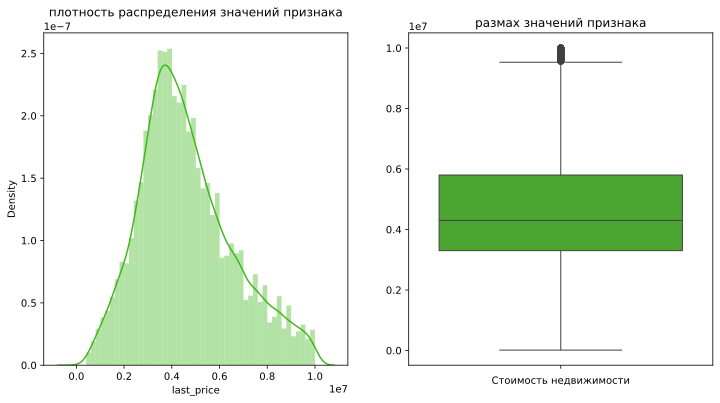

In [86]:
# парные диаграммы признака `last_price`
# поскольку абсолютное большинство сделок находятся в ценовом диапазоне до 10 000 000 руб, 
# сделаем соответствующий срез и его визуализацию
price_detailed = df.query('last_price < 10000000')

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(price_detailed['last_price'], color = '#42b71d')

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y=price_detailed['last_price'], color = '#42b71d').set(ylabel = '', xlabel = 'Стоимость недвижимости')

plt.show()

In [87]:
# описательная статистика по признаку
df['last_price'].describe().astype(int)

count        23691
mean       6542277
std       10888742
min          12190
25%        3400000
50%        4650000
75%        6800000
max      763000000
Name: last_price, dtype: int64

In [88]:
# медианное значение признака
df['last_price'].median()

4650000.0

In [89]:
# выявление некорректных значений признака
df[df['last_price'] == df['last_price'].min()]

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition,cityCenters_category
8792,Санкт-Петербург,12190.0,109.0,32.0,40.5,2,2.75,0,False,False,...,9176.0,36421.0,1,805,0,3000,7,2019-03-20,8.0,удалённые районы города


In [90]:
# замена некорректного значения в тыс.руб. на корректное значение в руб.
df['last_price'] = df['last_price'].replace(12190.0, 12190000.0)

In [91]:
print('Люксовый сегмент:', df.query('last_price > 11000000').shape[0], 'сделок.')
print('Средний сегмент:', df.query('last_price > 4650000 and last_price <= 11000000').shape[0], 'сделок.')
print('Экономичный сегмент:', df.query('last_price <= 4650000').shape[0], 'сделок.')

Люксовый сегмент: 2285 сделок.
Средний сегмент: 9449 сделок.
Экономичный сегмент: 11957 сделок.


**Вывод:** в датафрейме присутствует очень большой ценовой диапазон от 12 190 руб. до 763 000 000 руб. Вызывает сомнение корректность указанного минимального значения сделки. Мы установили, что это строка `df.loc[8789]` содержит информацию о продаже квартиры площадью 109 кв.м в Санкт-Петербурге. Предположим, что это ошибка ввода данных пользователем ввиду незнания единиц измерения, и заменим это значение на 12 190 000 руб. Данные по признаку `last_price` скорректированы, удалений аномалий не требуется. 

В люксовом сегменте присутствуют 2 285 квартир стоимостью от 11 000 000 руб. до 763 000 000 руб. Это 9.5% всех записей в датафрейме. Средний ценовой сегмент составляют квартиры стоимостью от 4 650 000 до 11 000 000 рублей. Насчитывается 9 449 записей в этом виде сделок, или 40% всех записей датафрейма. Экономичный ценовой сегмент представлен сделками в диапазоне до 4 650 000 руб. Это самый мощный сегмент данных, который насчитывает 11 957 единиц или 50.5% всех записей датафрейма.

<a id=2.4.2.></a>
#### 2.4.2. Аномальные значения признаков **`'total_area'`**, **`'living_area'`**, **`'kitchen_area'`**

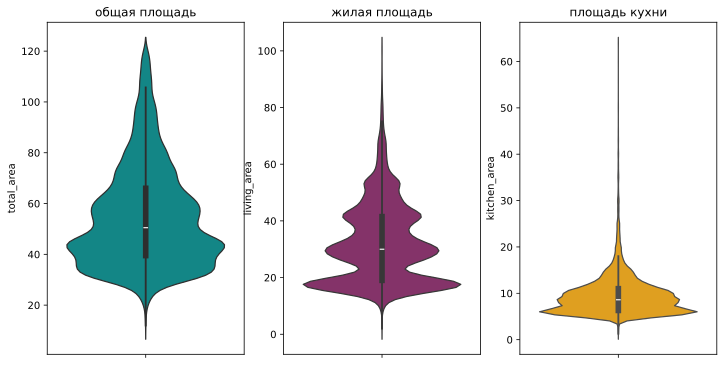

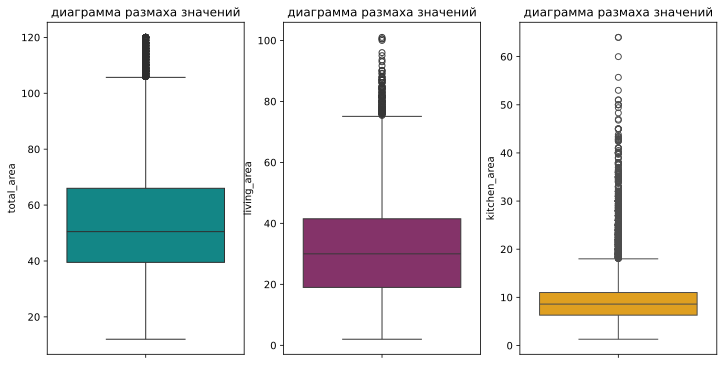

In [92]:
# диаграммы оценки плотности распределения значений площадей

# за пределами значений общей площади 200 кв.м начинаются значения, характерные для люксового сегмента
# средний (в том числе средний высокий) ценовой сегмент ограничивается общей площадью 120 кв.м
# сделаем срез по этому условию и построим диаграммы
area_detailed = df.query('total_area <= 120')

plt.figure(figsize=(12, 6))

plt.subplot(1,3,1)
plt.title('общая площадь')
sns.violinplot(y = area_detailed['total_area'], color = '#009999')

plt.subplot(1,3,2)
plt.title('жилая площадь')
sns.violinplot(y = area_detailed['living_area'], color = '#92256E')

plt.subplot(1,3,3)
plt.title('площадь кухни')
sns.violinplot(y = area_detailed['kitchen_area'], color = '#FFAA00')

plt.show()

plt.subplot(1,3,1)
plt.title('диаграмма размаха значений')
sns.boxplot(y = area_detailed['total_area'], color = '#009999')

plt.subplot(1,3,2)
plt.title('диаграмма размаха значений')
sns.boxplot(y = area_detailed['living_area'], color = '#92256E')

plt.subplot(1,3,3)
plt.title('диаграмма размаха значений')
sns.boxplot(y = area_detailed['kitchen_area'], color = '#FFAA00')

plt.show()

In [93]:
# описательная статистика по признакам
df[['total_area', 'living_area', 'kitchen_area']].describe().astype(int)

,total_area,living_area,kitchen_area
count,23691,23691,23691
mean,60,34,10
std,35,21,5
min,12,2,1
25%,40,19,6
50%,52,30,9
75%,69,42,11
max,900,409,112


In [94]:
# медианное значение признаков
df[['total_area', 'living_area', 'kitchen_area']].median()

total_area      52.0
living_area     30.3
kitchen_area     9.0
dtype: float64

In [95]:
# выявление некорректных значений жилой площади
df[df['living_area'] == df['living_area'].min()]

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition,cityCenters_category
13914,Санкт-Петербург,6350000.0,52.0,2.0,9.0,2,3.0,0,False,False,...,6521.0,32453.0,0,3000,1,1012,20,2018-02-06,91.0,удалённые районы города
21752,поселок Мурино,2330000.0,23.0,2.0,5.0,0,2.6,0,False,True,...,65968.0,84869.0,0,5000,0,5000,0,2018-01-01,66.0,Ленинградская область


Полученные строки свидетельствуют о высокой вероятности допущенной механической ошибки пользователя при вводе значений. Так, вместо цифры `20` была допущена типичная опечатка, которая привела к появлению усечённого до `2.0` значения площади. Проверим остальные минимальные значения и заменим. Также полагаем важным учесть, что большая часть квартир, представленных в датафрейме, относится к советскому жилому фонду, где в "хрущёвках" 6 кв.м приходились на 3 проживающих.

In [96]:
# выберем по условию строки с некорректными значениями признака жилой площади
df.loc[df['living_area'] < 6]

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition,cityCenters_category
3241,Санкт-Петербург,4440000.0,41.0,3.0,11.0,1,2.6,0,False,False,...,13073.0,19272.0,0,3000,0,3000,7,2017-07-02,216.0,пригородные районы
13914,Санкт-Петербург,6350000.0,52.0,2.0,9.0,2,3.0,0,False,False,...,6521.0,32453.0,0,3000,1,1012,20,2018-02-06,91.0,удалённые районы города
17579,Санкт-Петербург,2680000.0,22.0,5.0,5.0,0,2.7,2,False,True,...,11618.0,22735.0,1,835,1,652,11,2018-08-11,70.0,удалённые районы города
21752,поселок Мурино,2330000.0,23.0,2.0,5.0,0,2.6,0,False,True,...,65968.0,84869.0,0,5000,0,5000,0,2018-01-01,66.0,Ленинградская область
21936,Санкт-Петербург,6100000.0,77.6,5.4,9.8,4,2.5,0,False,False,...,11270.0,29338.0,1,584,0,3000,15,2019-02-28,33.0,удалённые районы города
23566,Санкт-Петербург,64990000.0,139.0,3.0,16.0,3,3.0,1,False,False,...,5975.0,33255.0,1,630,3,100,14,2015-11-24,280.0,центральные районы города


In [97]:
# заменим значения до минимальных размеров жилой площади
df.loc[(df['living_area'] < 6), 'living_area'] = 6.0

Также выполним проверку численного превосходства общей площади квартиры сумме жилой площади и площади кухни.

In [98]:
# выявление некорректных значений признака `total_area`
anomal_total_area = df.query('(kitchen_area + living_area ) > total_area')
print('Всего', anomal_total_area.shape[0], 'строк с некорректными данными по площадям квартиры.')

Всего 548 строк с некорректными данными по площадям квартиры.


In [99]:
# создадим индекс квартир с некорректными значениями признака `total_area`
anomal_total_area_index = anomal_total_area.index

In [100]:
# удаляем из датафрейма эти квартиры по индексу
df.drop(anomal_total_area_index, inplace=True)

Изучим значения площади кухни и выявим аномальные отклонения.

In [101]:
# поиск аномально малых значений площади кухни 
df.loc[(df['kitchen_area'] < 5)].shape[0]

104

In [102]:
# удаление некорректных значений площади кухни за исключением квартир-студий и квартир с открытой планировкой
df.drop(df[~(df.studio | df.open_plan) & (df.kitchen_area < 5)].index, inplace=True)

In [103]:
# проверяем результат удаления
df.query('~(studio | open_plan) & (kitchen_area < 5)')

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition,cityCenters_category


**Вывод:** в группе взаимосвязанных признаков, описывающих ту или иную площадь квартиры, мы видим наиболее равномерное распределение данных по признаку `total_area` и `kitchen_area`. При детальном изучении графиков ярко выделяются 2 сильно "пережатые" области значений в диапазоне от 20 до 40 кв.м по признаку `living_area` при общей площади квартиры от 40 до 60 кв.м и площади кухни незначительно больше нормативных 5 - 6 кв.м. Это говорит о том, что перед нами квартиры в элитных новостройках, где под вспомогательные помещения, балконы, лоджии, встроенную мебель отводятся гораздо б***о***льшие площади, чем в советском жилом фонде.

Площадь квартиры является одним из ключевых признаков, по которому потенциальный покупатель проводит отбор и оценку жилья. В датафрейме в экономичной ценовой категории находятся 11 425 квартир площадью до 52 кв.м., что составляет 49.6% от общего числа записей. Средний низкий ценовой сегмент занимают 5 900 квартир площадью от 52 кв.м до 70 кв.м., это 25.6% всех объявлений. Средний высокий представлен жильём площадью от 70 кв.м до 120 кв.м. - этим параметрам соответствуют 4 642 квартиры, или 20.1% данных. Выше этого значения находится элитная недвижимость площадью до 900 кв.м. Таких записей в датафрейме незначительное количество: 1 061 или 4.6%, но они являются ценным источником информации, подтверждающим полноту представленной недвижимости всех типов на рынке Санкт-Петербурга и Ленинградской области. В целом, характер взаимосвязи этих 3 признаков в той или иной степени соотносится с государственной градостроительной политикой и описывает потребительские параметры жилого фонда того или иного периода возведения. 

<a id=2.4.3.></a>
#### 2.4.3. Аномальные значения признака **`'rooms'`**

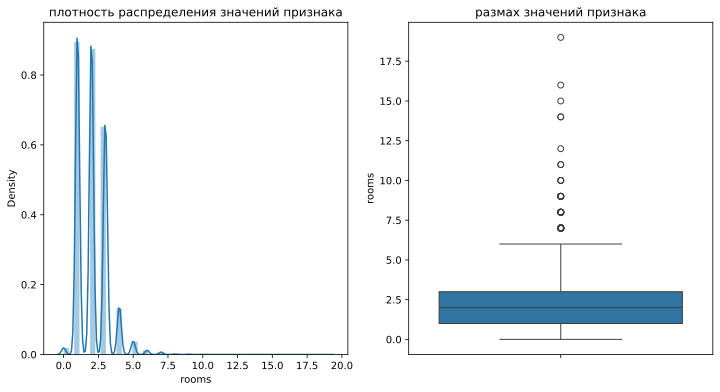

In [104]:
# парные диаграммы признака 'rooms'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['rooms'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['rooms'])

plt.show()

In [105]:
# описательная статистика по признаку
df['rooms'].describe().astype(int)

count    23039
mean         2
std          1
min          0
25%          1
50%          2
75%          3
max         19
Name: rooms, dtype: int64

In [106]:
# медианное значение признака
df['rooms'].median()

2.0

In [107]:
# проверим значение признака для квартир-студий
# в этом типе жилья число комнат должно быть равным нулю 
df[df['studio']]['rooms'].value_counts()

rooms
0    112
1      9
Name: count, dtype: int64

In [108]:
# проверим значение признака для квартир с открытой планировкой
# в этом типе жилья число комнат должно быть равным нулю 
df[df['open_plan']]['rooms'].value_counts()

rooms
0    49
1     3
3     2
2     1
5     1
4     1
Name: count, dtype: int64

Выполним замену некорректных значений по каждому из этих типов квартир.

In [109]:
# замена некорректных значений признака
df.loc[(df['studio'] == True) & (df['rooms'] == 1), 'rooms'] = 0
df.loc[(df['open_plan'] == True) & (df['rooms'] > 0), 'rooms'] = 0

In [110]:
# проверим значение признака для многокомнатых квартир
anomal_rooms_index = df.query('rooms >= 5 and total_area < 84')
anomal_rooms_index

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition,cityCenters_category
542,Кингисепп,1750000.0,40.0,28.6,5.0,5,2.60,0,False,False,...,65968.0,84869.0,0,5000,0,5000,8,2016-04-28,127.0,Ленинградская область
2736,Санкт-Петербург,5200000.0,72.0,59.0,6.5,5,2.60,0,False,False,...,15009.0,14237.0,1,1362,2,555,7,2015-10-16,362.0,пригородные районы
11222,Санкт-Петербург,4900000.0,67.0,28.0,7.0,5,2.50,0,False,False,...,13614.0,12287.0,0,3000,1,611,15,2018-03-19,107.0,пригородные районы
19369,Санкт-Петербург,7500000.0,62.2,55.1,6.0,5,3.02,0,False,False,...,3249.0,24920.0,2,84,1,533,6,2014-12-18,694.0,центральные районы города
20394,Санкт-Петербург,4650000.0,66.3,50.9,6.8,5,2.70,0,False,False,...,10913.0,12422.0,0,3000,1,946,1,2017-10-13,117.0,удалённые районы города
23094,Санкт-Петербург,5800000.0,66.0,55.5,6.0,5,2.70,0,False,False,...,11933.0,12007.0,0,3000,0,3000,0,2017-06-09,21.0,удалённые районы города
23297,Санкт-Петербург,4950000.0,67.0,51.2,7.5,5,2.60,0,False,False,...,12035.0,12109.0,0,3000,0,3000,9,2018-10-29,89.0,пригородные районы


В датафрейме присутствует 515 многокомнатных квартир (от 5 комнат и более), из них 7 квартир не соответствуют установленным нормативам жилья в части общей площади квартиры: организация 5 комнат и более допускается в жилье общей площадью более 84 кв.м. Удалим строки с некорректными данными.

In [111]:
# создадим индекс квартир с некорректным числом комнат
anomal_rooms_index = anomal_rooms_index.index

In [112]:
# удаляем из датафрейма эти квартиры по индексу
df.drop(anomal_rooms_index, inplace=True)

In [113]:
# посчитаем количество комнат в квартирах, выставленных на продажу
df.pivot_table(index='rooms', values='locality_name', aggfunc='count')

,locality_name
rooms,
0,178
1,7824
2,7658
3,5703
4,1161
5,316
6,103
7,58
8,12


**Вывод:** нами выполнена проверка значений признака количества комнат в квартирах, выявлены и удалены строки с некорректными данными. Самыми многочисленными и популярными объектами купли-продажи являются ожидаемо `однокомнатные` и `двухкомнатные` квартиры. По ним в датафрейме суммарно присутствует 15 473 объявления или 67.2%. Третье место по популярности занимают `трёхкомнатные` квартиры - их 5 701 или 24.7%. `Четырёхкомнтатные` квартиры как объект сделки с недвижимостью встречаются ощутимо реже, таких предложений на рынке в указанный период было зафиксировано всего 1 161 или 5.5%. `Многокомнатные` квартиры, равно как и `квартиры-студии` и `квартиры с открытой планировкой`, безусловно, находят своего покупателя, но присутствуют на рынке недвижимости Санкт-Петербурга и Ленинградской области в малом количестве: от 178 до 316 объявлений или 1.4%. Многокомнатные квартиры с `7 комнатами и более` являются буквально штучным товаром: 89 объявлений из общего массива данных в 23 021 запись или 0.4%.

<a id=2.4.4.></a>
#### 2.4.4. Аномальные значения признака **`'ceiling_height'`**

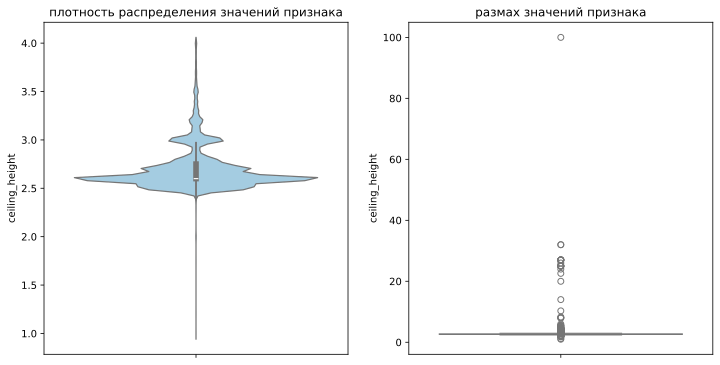

In [114]:
# парные диаграммы признака 'ceiling_height'
plt.figure(figsize=(12,6))

# срез данных по типовой высоте 4 м
ceil_delailed = df.query('ceiling_height <= 4')

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.violinplot(y=ceil_delailed['ceiling_height'], color='#9acfeb')

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['ceiling_height'], color='#9acfeb')

plt.show()

In [115]:
# описательная статистика по признаку
df['ceiling_height'].describe().round(2)

count    23032.00
mean         2.73
std          0.98
min          1.00
25%          2.60
50%          2.60
75%          2.75
max        100.00
Name: ceiling_height, dtype: float64

In [116]:
# медианное значение признака
df['ceiling_height'].median()

2.6

In [117]:
# выявление некорректных значений признака
# высота потолка 100 м это явная опечатка, заменим это значение
df.loc[(df['ceiling_height'] == 100), 'ceiling_height'] = 10

In [118]:
# выявление некорректных значений признака
# удаляем 13 строк с квартирами, высота потолка в которых меньше 2.1 м
ceil_low = df.query('ceiling_height < 2.1')

In [119]:
# создаём индекс таких квартир
ceil_low_index = ceil_low.index

In [120]:
# удаляем из датафрейма по индексу квартиры с аномально низкими потолками
df.drop(ceil_low_index, inplace=True)

Проверим оставшиеся значения признака. В датасете остались аномальные высоты потолков с очевидными опечатками и искажениями. Обработаем эти значения.

In [121]:
# выявление некорректных значений признака
ceil_high = df.query('ceiling_height <= 20.0 and ceiling_height >= 10.30')

In [122]:
# создаём индекс таких квартир
ceil_high_index = ceil_high.index

In [123]:
# удаляем из датафрейма по индексу квартиры с аномально высокими потолками
df.drop(ceil_high_index, inplace=True)

In [124]:
# с помощью цикла перебираем все аномальные двухзначные высоты потолков и заменяем их
for i in df['ceiling_height']:
    if i > 10:
        df['ceiling_height'] = df['ceiling_height'].replace(i, i/10)

In [125]:
# проверяем значения признака после очистки от аномалий
df['ceiling_height'].describe().round(2)

count    23016.00
mean         2.71
std          0.25
min          2.25
25%          2.60
50%          2.60
75%          2.75
max         10.00
Name: ceiling_height, dtype: float64

**Вывод:** в результате выявления аномальных значений по признаку `ceiling_height` были выявлены искажённые данные, которые были заменены или удалены. Минимальная высота потолка составляет 2.25 м, максимальная - 10 м. Средние значения, характерные для абсолютного большинства квартир, находятся в очень узком диапазоне от 2.6 м до 2.75 м. Такая высота потолка встречается в 14 434 объявлениях и составляет 62.74% всех записей. Чуть большей высотой потолка от 2.75 до 3 м включительно обладают 3 490 квартир (15.2% объявлений). Эту условную вторую ступень с ними делят квартиры с низкими потолками от 2.25 до 2.5 включительно, это 3 443 квартиры (15% объявлений). Малочисленное для этого датафрейма элитное жильё характеризуется потолками выше 3 метров и присутствует в количестве 1 638 квартир (7.1% объявлений). Для люксовой недвижимости тренд последних лет - создание не только второго, но и третьего яруса квартиры с дополнительным освещением, поэтому высота потолка здесь может достигать 10 м.

<a id=2.4.5.></a>
#### 2.4.5. Аномальные значения признака **`'balcony'`**

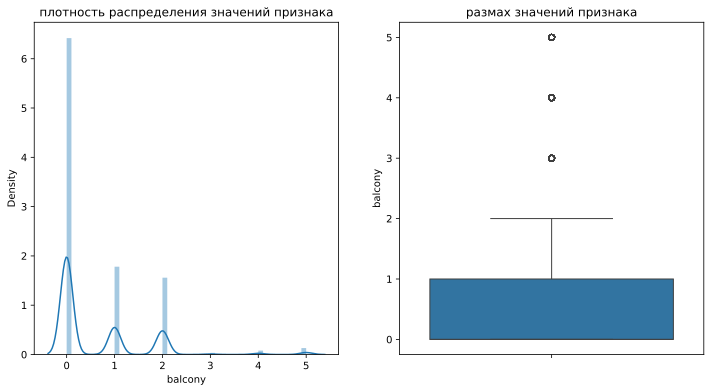

In [126]:
# парные диаграммы признака 'balcony'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['balcony'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['balcony'])

plt.show()

In [127]:
# описательная статистика по признаку
df['balcony'].describe().astype(int)

count    23016
mean         0
std          0
min          0
25%          0
50%          0
75%          1
max          5
Name: balcony, dtype: int64

In [128]:
# медианное значение признака
df['balcony'].median()

0.0

In [129]:
# выявление некорректных значений признака
df['balcony'].max()

5

В данных имеются 300 квартир с 5 балконами. В соответствии с действующей нормативной документацией и общероссийской строительной практикой, мы можем сформировать ряд условий, которые помогут выявить некорректные данные в этом конкретном случае:

* 1 балкон для каждой 1 комнаты в многокомнатной квартире
* 5 балконов правдиво в случае, если общая площадь квартиры в 5 комнат от 84 кв.м до 96 кв.м
* 5 балконов правдиво в случае, если общая площадь квартиры в 6 комнат от 103 кв.м до 109 кв.м

Проверим данные на соответствие этим условиям.

In [130]:
# срез данных по условию
df.query('balcony == 5').head()

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition,cityCenters_category
41,Санкт-Петербург,7900000.0,74.0,59.0,12.0,3,2.60,5,False,False,...,12612.0,37715.0,1,725,1,759,16,2016-05-04,179.000000,пригородные районы
42,Петергоф,22000000.0,161.8,80.9,17.6,4,2.80,5,False,False,...,30605.0,35416.0,2,47,1,907,13,2015-07-08,987.000000,Ленинградская область
116,Санкт-Петербург,10999000.0,97.2,53.5,18.3,3,2.50,5,False,False,...,21138.0,19426.0,0,3000,2,390,18,2017-11-13,394.000000,Ленинградская область
267,Санкт-Петербург,14700000.0,120.0,63.0,16.0,3,2.75,5,False,False,...,10430.0,39204.0,2,627,3,77,2,2018-09-07,61.000000,удалённые районы города
311,Санкт-Петербург,12500000.0,86.0,47.0,13.0,3,2.80,5,False,False,...,15686.0,52192.0,0,3000,1,441,20,2018-10-19,183.064351,пригородные районы


In [131]:
# заменим балконы по условию
df.loc[(df['balcony'] == 5) & (df['rooms'] == 1), 'balcony'] = 1
df.loc[(df['balcony'] == 5) & (df['rooms'] == 2), 'balcony'] = 2
df.loc[(df['balcony'] == 5) & (df['rooms'] == 3), 'balcony'] = 3
df.loc[(df['balcony'] == 5) & (df['rooms'] == 4), 'balcony'] = 4

In [132]:
# проверка результатов замены и вывод среза датафрейма по условию
df.query('balcony == 5')

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition,cityCenters_category
1307,Санкт-Петербург,26558000.0,152.38,81.5,14.61,5,2.75,5,False,False,...,10364.0,39140.000000,2,173,3,196,20,2017-01-11,625.000000,удалённые районы города
6508,Санкт-Петербург,30000000.0,198.90,109.0,23.00,5,3.10,5,False,False,...,10263.0,10015.000000,2,587,0,3000,9,2017-11-08,524.000000,удалённые районы города
10683,Санкт-Петербург,32894076.0,364.70,100.5,6.00,7,3.32,5,False,False,...,12242.0,28036.610859,0,5000,0,5000,6,2019-05-02,183.064351,пригородные районы
14483,Санкт-Петербург,9900000.0,183.00,112.0,14.00,5,2.83,5,False,False,...,11082.0,10997.000000,0,3000,1,418,3,2017-02-09,129.000000,удалённые районы города
15874,Санкт-Петербург,20500000.0,165.20,112.2,16.50,5,2.91,5,False,False,...,9782.0,37310.000000,1,497,0,3000,17,2018-09-03,183.064351,удалённые районы города
21825,Санкт-Петербург,21900000.0,220.00,110.0,17.00,5,2.60,5,False,False,...,12219.0,37322.000000,1,739,2,752,17,2016-05-04,125.000000,пригородные районы
21948,Санкт-Петербург,130000000.0,431.00,220.0,20.00,7,3.70,5,False,False,...,12242.0,28036.610859,0,5000,0,5000,19,2017-10-02,161.000000,пригородные районы


После обработки признака мы видим, что сформировалась группа из 7 квартир, по своим потребительским характеристикам относящихся к люксовому сегменту рынка недвижимости. Теперь проясним для себя положение дел по оставшемуся диапазону значений. Количество балконов (выступающих на фасаде) или лоджий (встроенных в объём жилого дома) не может быть больше количества комнат в квартире, будь это элитное жильё или типичная "хрущёвка". Отфильтруем из обработки квартиры-студии и квартиры со свободной планировкой и воспользуемся той же логикой количества комнат, площадей и балконов.

In [133]:
# срезаем данные по условию:
# квартира не студия, не открытой планировки, а количество балконов больше количества комнат
balcs = df[(~df['studio']) & (~df['open_plan']) & (df['balcony'] > df['rooms'])]

In [134]:
balcs.shape[0]

1621

В срезе данных мы видим 1621 строку с некорректными данными. Выполним замену по комплексному условию.

In [135]:
# заменим балконы по условию
df.loc[(~df['studio']) & (~df['open_plan']) & (df['balcony'] > df['rooms']) & (df['rooms'] == 1), 'balcony'] = 1
df.loc[(~df['studio']) & (~df['open_plan']) & (df['balcony'] > df['rooms']) & (df['rooms'] == 2), 'balcony'] = 2
df.loc[(~df['studio']) & (~df['open_plan']) & (df['balcony'] > df['rooms']) & (df['rooms'] == 3), 'balcony'] = 3
df.loc[(~df['studio']) & (~df['open_plan']) & (df['balcony'] > df['rooms']) & (df['rooms'] == 4), 'balcony'] = 4

In [136]:
# посчитаем количество балконов в квартирах
df.pivot_table(index='balcony', values='locality_name', aggfunc='count')

,locality_name
balcony,
0,14772
1,5581
2,2311
3,299
4,46
5,7


**Вывод:** балкон — это не только роскошь, но ещё и место для хранения лыж, солений, санок и засохшего фикуса. С наличием этой опции повезло обладателям 8 242 квартир, проданных на Яндекс Недвижимости Санкт-Петербурга в 2014 - 2019 годах. Почти в четверти квартир есть 1 балкон (5580 объявлений тому подтверждение). Характерные для новостроек второй половины 1960-х годов 2 балкона присутствуют в 2 310 квартирах, но, если быть совсем точным, речь здесь идёт не о балконах, а о лоджиях. На бумаге разница невелика, на деле есть существенные преимущества в утеплении этого пространства и включении его в жилую площадь. Элитная недвижимость может удивить нас не только баснословной стоимостью и интересной планировкой, но и количеством балконов: 3, 4, а то и все 5 балконов мы можем отметить в 352 объявлениях, что составляет порядка 2% от общего массива данных. С необходимостью организации системы хранения вещей придётся столкнуться 14 673 покупателям квартир (64.2% от всего массива данных). Сразу избавимся от стереотипа "нет балкона = капсульная квартира на одного человека". В числе квартир без балкона присутствуют большие квартиры-лофты и многоуровневые квартиры, расположенные на последних этажах.

<a id=2.4.6.></a>
#### 2.4.6. Аномальные значения признаков **`'floor'`**, **`'floors_total'`**

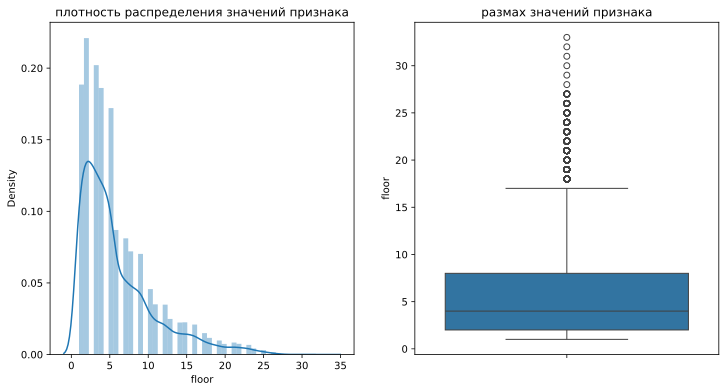

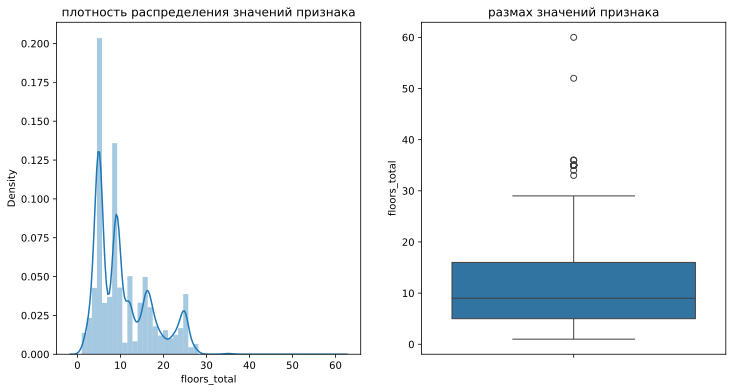

In [137]:
# парные диаграммы признака 'floor', 'floors_total'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['floor'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['floor'])

plt.show()

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['floors_total'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['floors_total'])

plt.show()

In [138]:
# описательная статистика по признаку
df[['floor', 'floors_total']].describe().astype(int)

,floor,floors_total
count,23016,23016
mean,5,10
std,4,6
min,1,1
25%,2,5
50%,4,9
75%,8,16
max,33,60


In [139]:
# медианное значение признака
df[['floor', 'floors_total']].median()

floor           4.0
floors_total    9.0
dtype: float64

На первый взгляд значение признака `floor` распределено нормально, а в признаке `floors_total` судя по диаграмме плотности распределения значений, есть некорректные данные.

In [140]:
# выявляем некорректные данные
df['floors_total'].max()

60

На территории Кронштадта нет 60-этажных высотных зданий. Налицо опечатка, которую мы можем заменить.

In [141]:
# замена некорректных значений признака 
df.loc[(df['floors_total'] == 60), 'floors_total'] = 6

In [142]:
# выявляем некорректные данные
flr = df.loc[(df['floor'] > df['floors_total'])]
print(flr.shape[0])

35


Таких строк всего 35, и ранее по ним было выполнено заполнение пропусков медианной этажностью зданий по конкретной локации. Мы можем выполнить замену значений исходя из следующей логики: указанный этаж в карточке объявления является последним, поэтому этот факт не был отмечен пользователем дополнительно.

In [143]:
# замена некорректных значений признака 
df.loc[(df['floor'] > df['floors_total']), 'floors_total'] = df['floor']

In [144]:
# посчитаем соотношение этажности здания и этажа продаваемой квартиры
df.pivot_table(index='floors_total', values='floor', aggfunc='count').sort_values(by='floor')

,floor
floors_total,
29,1
33,1
34,1
52,1
36,3
1,21
28,21
35,22
26,123


**Вывод:** в полученных количественных значениях мы видим очередное подтверждение основных тенденций на рынке недвижимости Санкт-Петербурга в период 2014-2019 годов. Большое количество объявлений сообщает о продаже квартиры `на 2 или 3 этаже` в типовой `5-этажке` и `9-этажке`. Такие объявления по 5-этажкам встречаются 5 532 раз и по 9-этажкам 3 687 раз.

`Малоквартирные дома 1940-1950-х годов постройки высотностью до 4 этажей` выставлены на продажу в 2 168 объявлениях. По своей сути, это старый жилой фонд, который потенциально может быть в скором времени признан ветхим, аварийным и подлежать сносу: но на фотографиях опрятной и светлой квартиры едва ли будет сгнивший фундамент или запах из подтекающих подвальных труб.

`Кирпичные многоэтажки высотой в 12 и 16 этажей`, построенные по типовым точечным проектам во второй половине 1960-1970-х гг. делят между собой третью строчку условного рейтинга и представлены 1364 и 1351 объявлениями о продаже. Остальные дома разной этажности представлены в малых долях и по количеству не превышают 1165 объявлений. 

Ощутимый провал в значениях признаков наступает после 28 этажа, и этому есть несколько причин. Во-первых, неустойчивые грунты, насыщенные подземными водами, делают строительство высоких и тяжелых сооружений технологически сложным и затратным. Во-вторых, существует регламент высотности, который запрещает возводить здания выше определенного уровня. Особенно серьезно за его соблюдением следят в историческом центре. В-третьих, в Санкт-Петербурге как ни в одном другом городе России активные градозащитники, готовые биться с властями и застройщиками за каждый дом и каждый метр. Санкт-Петербург настолько консервативен в этом вопросе, что на протяжении 286 лет лидерство по высоте удерживал Петропавловский собор, построенный еще в XVIII веке. Словно символ перемен, самое высокое здание Европы появилось в Санкт-Петербурге только в 2018 году. Речь идёт о Лахта центре. С высотными многоквартирными комплексами Санкт-Петербурга дела обстоят аналогично: их пока очень мало. В текущем датафрейме за период с 2014 по 2019 год мы можем насчитать всего 51 квартиру в высотных домах, в общей массе данных это 0.2%.

<a id=2.4.7.></a>
#### 2.4.7. Аномальные значения признаков **`'cityCenters_nearest'`**, **`'airports_nearest'`**

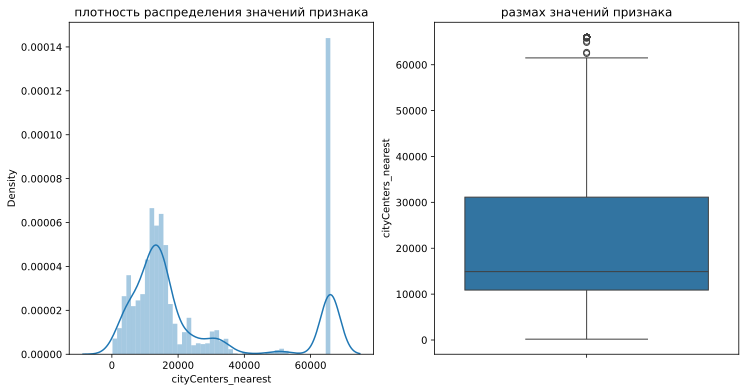

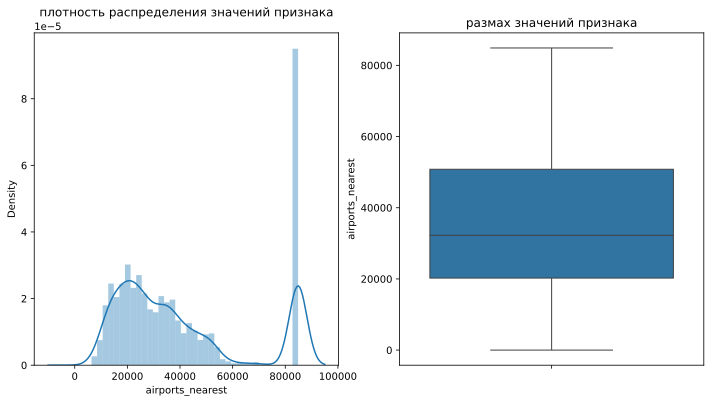

In [145]:
# парные диаграммы признака 'cityCenters_nearest'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['cityCenters_nearest'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['cityCenters_nearest'])

plt.show()

# парные диаграммы признака 'airports_nearest'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['airports_nearest'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['airports_nearest'])

plt.show()

In [146]:
# описательная статистика по признаку
df[['cityCenters_nearest', 'airports_nearest']].describe().astype(int)

,cityCenters_nearest,airports_nearest
count,23016,23016
mean,24857,40000
std,22060,25172
min,181,0
25%,10881,20234
50%,14900,32257
75%,31136,50800
max,65968,84869


In [147]:
# медианное значение признака
df[['cityCenters_nearest', 'airports_nearest']].median()

cityCenters_nearest    14900.5
airports_nearest       32257.5
dtype: float64

In [148]:
# выявление некорректных значений признака
df['airports_nearest'].sort_values()

21080        0.0
12898     6450.0
4016      6450.0
7777      6914.0
23142     6949.0
          ...   
16794    84869.0
22       84869.0
23690    84869.0
5        84869.0
23688    84869.0
Name: airports_nearest, Length: 23016, dtype: float64

In [149]:
# замена значений восстановленными данными по признаку `cityCenters_nearest`
df.loc[(df['cityCenters_nearest'] == 22801.0), 'airports_nearest'] = 25200.0

In [150]:
df[['cityCenters_nearest', 'airports_nearest']].describe().astype(int)

,cityCenters_nearest,airports_nearest
count,23016,23016
mean,24857,40001
std,22060,25171
min,181,6450
25%,10881,20234
50%,14900,32257
75%,31136,50800
max,65968,84869


In [151]:
# сводная таблица с данными по распределению квартир в соответствии с удалённостью от Санкт-Петербурга
df.pivot_table(index='cityCenters_category', values='cityCenters_nearest', aggfunc='count')

,cityCenters_nearest
cityCenters_category,
Ленинградская область,8916
исторический центр города,520
пригородные районы,6804
удалённые районы города,4494
центральные районы города,2282


**Вывод:** данные по признакам расстояния до центра города и до ближайшего аэропорта распределены нормально, искажений и аномалий не выявлено. Была восстановлена 1 величина расстояния до ближайшего аэропорта. Количество квартир к продаже имеет обратную взаимосвязь с расстоянием от центра города Санкт-Петербург и нарастает по мере удаления от него. Так, в центральной части Санкт-Петербурга на продажу были выставлены 2 802 объекта, в удалённых районах города эта цифра уже вдвое больше и составляет 4 500 объявлений, в пригородных районах и в Ленинградской области количество сделок по купле-продаже примерно равно и составляет величину от 7 556 до 8 147. Ротационная воронка владельцев недвижимого имущества охватывает всю Ленинградскую область, и её спокойное тихое место, конечно, в самом сердце Санкт-Петербурга.

<a id=2.4.8.></a>
#### 2.4.8. Аномальные значения признаков **`'parks_nearest'`**, **`'ponds_nearest'`**, **`'parks_around3000'`**, **`'ponds_around3000'`**

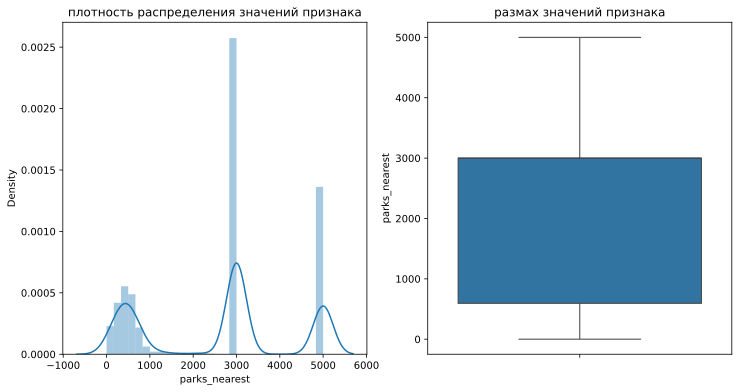

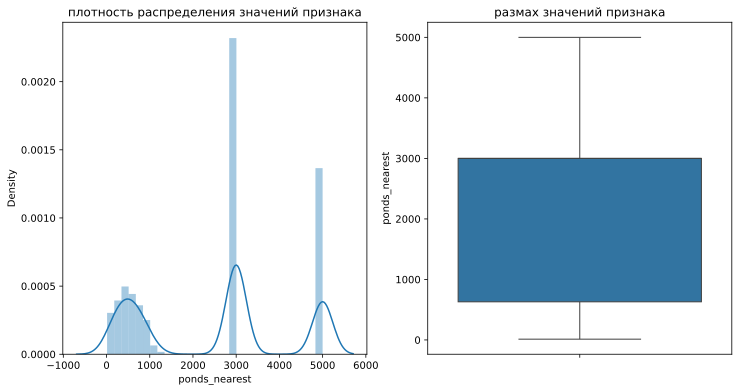

In [152]:
# парные диаграммы признака 'parks_nearest'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['parks_nearest'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['parks_nearest'])

plt.show()

# парные диаграммы признака 'ponds_nearest'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['ponds_nearest'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['ponds_nearest'])

plt.show()

In [153]:
# описательная статистика по признаку
df[['parks_nearest', 'ponds_nearest']].describe().astype(int)

,parks_nearest,ponds_nearest
count,23016,23016
mean,2589,2492
std,1717,1751
min,1,13
25%,595,630
50%,3000,3000
75%,3000,3000
max,5000,5000


In [154]:
# медианное значение признака
df[['parks_nearest', 'ponds_nearest']].median()

parks_nearest    3000.0
ponds_nearest    3000.0
dtype: float64

In [155]:
# выявляем некорректное значение признака `parks_nearest`
df['parks_nearest'].sort_values()

14622       1
11948       3
22933       4
9343        7
2526        9
         ... 
8153     5000
23688    5000
8        5000
23684    5000
23687    5000
Name: parks_nearest, Length: 23016, dtype: int64

In [156]:
# заменяем некорректное значение
df.loc[(df['parks_nearest'] < 10), 'parks_nearest'] = 10

In [157]:
# количество объектов рядом с парками
df.query('parks_nearest <= 1000').shape[0]

7557

In [158]:
# срез данных по озеленению и благоустройству близлежащих территорий
df.query('parks_nearest <= 1000').groupby('cityCenters_category').count()

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,floors_total,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition
cityCenters_category,,,,,,,,,,,,,,,,,,,,,
Ленинградская область,984,984,984,984,984,984,984,984,984,984,...,984,984,984,984,984,984,984,984,984,984
исторический центр города,430,430,430,430,430,430,430,430,430,430,...,430,430,430,430,430,430,430,430,430,430
пригородные районы,2317,2317,2317,2317,2317,2317,2317,2317,2317,2317,...,2317,2317,2317,2317,2317,2317,2317,2317,2317,2317
удалённые районы города,2513,2513,2513,2513,2513,2513,2513,2513,2513,2513,...,2513,2513,2513,2513,2513,2513,2513,2513,2513,2513
центральные районы города,1313,1313,1313,1313,1313,1313,1313,1313,1313,1313,...,1313,1313,1313,1313,1313,1313,1313,1313,1313,1313


In [159]:
# количество объектов рядом с водоёмами
df.query('ponds_nearest <= 1000').shape[0]

8581

In [160]:
# срез данных по водоёмам у близлежащих территорий
df.query('ponds_nearest <= 1000').groupby('cityCenters_category').count()

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,floors_total,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition
cityCenters_category,,,,,,,,,,,,,,,,,,,,,
Ленинградская область,1895,1895,1895,1895,1895,1895,1895,1895,1895,1895,...,1895,1895,1895,1895,1895,1895,1895,1895,1895,1895
исторический центр города,495,495,495,495,495,495,495,495,495,495,...,495,495,495,495,495,495,495,495,495,495
пригородные районы,2596,2596,2596,2596,2596,2596,2596,2596,2596,2596,...,2596,2596,2596,2596,2596,2596,2596,2596,2596,2596
удалённые районы города,2121,2121,2121,2121,2121,2121,2121,2121,2121,2121,...,2121,2121,2121,2121,2121,2121,2121,2121,2121,2121
центральные районы города,1474,1474,1474,1474,1474,1474,1474,1474,1474,1474,...,1474,1474,1474,1474,1474,1474,1474,1474,1474,1474


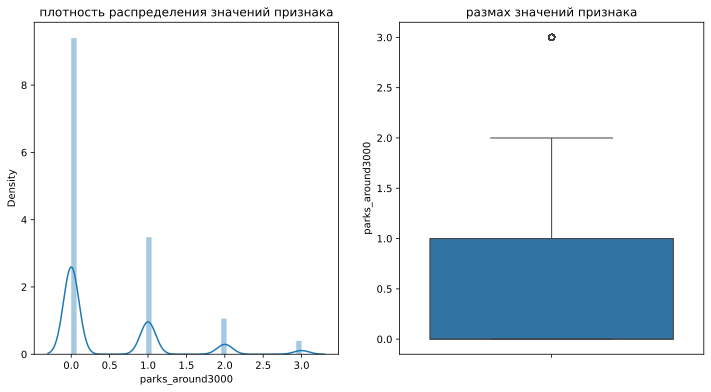

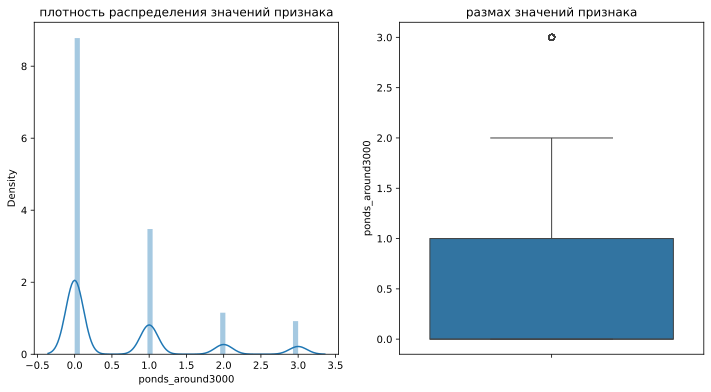

In [161]:
# парные диаграммы признака 'parks_around3000'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['parks_around3000'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['parks_around3000'])

plt.show()

# парные диаграммы признака 'ponds_around3000'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['ponds_around3000'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['ponds_around3000'])

plt.show()

In [162]:
# описательная статистика по признаку
df[['parks_around3000', 'ponds_around3000']].describe().astype(int)

,parks_around3000,ponds_around3000
count,23016,23016
mean,0,0
std,0,0
min,0,0
25%,0,0
50%,0,0
75%,1,1
max,3,3


In [163]:
# медианное значение признака
df[['parks_around3000', 'ponds_around3000']].median()

parks_around3000    0.0
ponds_around3000    0.0
dtype: float64

In [164]:
# срез данных по паркам у близлежащих территорий
df.query('parks_nearest >= 3000').shape[0]

15091

In [165]:
# срез данных по водоёмам у близлежащих территорий
df.query('ponds_nearest >= 3000').groupby('cityCenters_category').count()

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,floors_total,cityCenters_nearest,airports_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,total_images,first_day_exposition,days_exposition
cityCenters_category,,,,,,,,,,,,,,,,,,,,,
Ленинградская область,6949,6949,6949,6949,6949,6949,6949,6949,6949,6949,...,6949,6949,6949,6949,6949,6949,6949,6949,6949,6949
исторический центр города,25,25,25,25,25,25,25,25,25,25,...,25,25,25,25,25,25,25,25,25,25
пригородные районы,4071,4071,4071,4071,4071,4071,4071,4071,4071,4071,...,4071,4071,4071,4071,4071,4071,4071,4071,4071,4071
удалённые районы города,2288,2288,2288,2288,2288,2288,2288,2288,2288,2288,...,2288,2288,2288,2288,2288,2288,2288,2288,2288,2288
центральные районы города,768,768,768,768,768,768,768,768,768,768,...,768,768,768,768,768,768,768,768,768,768


**Вывод:** признаки, описывающие расстояние от квартиры до ближайшего парка или водоёма и их количество, содержат минимальное количество выбросов. Также, на диаграммах мы видим добавленные значения радиуса 5 км для данных, ранее содержавших пропуски. Расстояние до парка в 1 метр, равно как и 3, 7, 9 метров не выдерживают проверку реальностью. Смеем надеяться, что такое значение авторами объявления было сокращено умышленно, но из лучших побуждений. Мы заменили эти значения на "джентельменские" 10 метров. В данных по расстояниям до водоёмов искажений не выявлено.

Из данных по доступности зон отдыха и рекреации складывается весьма удручающая картина. Только 7 563 локации недвижимости могут порадовать пешей прогулкой по тенистым аллеям или вдоль берега озера: это удалённые районы города (2516 объявлений), пригородные районы (2319 объявлений), которые формировались в советское время без оглядки на парковочные площади и с чётким следованием нормативу количества кв.м зелёных насаждений на 1 жителя города. Ещё 1744 квартиры в центральных районах и в самом историческом центре города прилегают к старинным паркам, садам и скверам. В Ленинградской области таких "зелёных" квартир чуть меньше 1000. Сходным образом обстоят дела и с наличием водоёмов, хотя для квартир, расположенных на большом удалении в области этот показатель становится выше в 2 раза и достигает 1887.

Необходимо отметить, что в пригородных районах и на объектах Ленинградской области эти данные приобретают совершенно обратный смысл: объекты купли-продажи расположены в многоквартирных жилых домах в малочисленных городах, п.г.т., посёлках, сёлах, деревнях, где человек постоянно пребывает в контакте с естественной природой, а не с общественными пространствами, где природа воссоздана искусственно, хоть и умело.

<a id=2.4.9.></a>
#### 2.4.9. Аномальные значения признака **`'total_images'`**

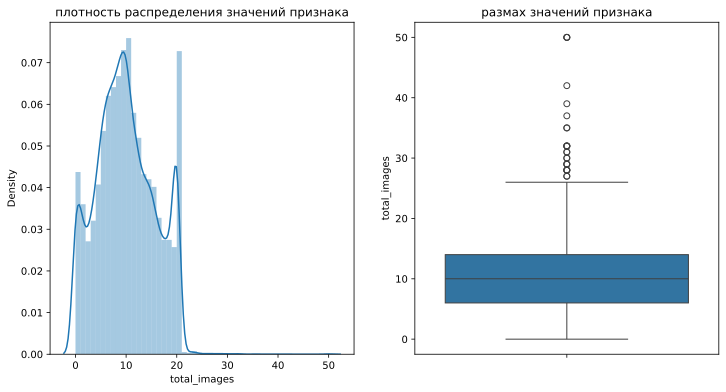

In [166]:
# парные диаграммы признака 'total_images'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['total_images'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['total_images'])

plt.show()

In [167]:
# описательная статистика по признаку количества фотографий
df['total_images'].describe().astype(int)

count    23016
mean         9
std          5
min          0
25%          6
50%         10
75%         14
max         50
Name: total_images, dtype: int64

In [168]:
# медианное значение признака
df['total_images'].median()

10.0

**Вывод:** на диаграммах по признаку количества фотографий мы видим равномерное распределение данных. Редкие значения начинаются после 25 фотографий. Превалирующее большинство пользователей довольствуется 10 фотографий объекта продажи. Аномалий по этому признаку не выявлено.

<a id=2.4.10.></a>
#### 2.4.10. Аномальные значения признака **`'days_exposition'`**

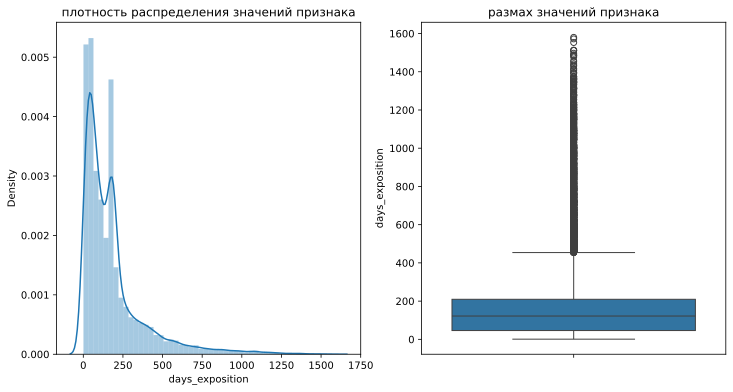

In [169]:
# парные диаграммы признака 'days_exposition'
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(df['days_exposition'])

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y = df['days_exposition'])

plt.show()

In [170]:
# переводим в целочисленный формат для удобства исследования
df['days_exposition'] = df['days_exposition'].astype(int)

In [171]:
# описательная статистика по признаку количества фотографий
df['days_exposition'].describe().astype(int)

count    23016
mean       182
std        206
min          1
25%         46
50%        122
75%        209
max       1580
Name: days_exposition, dtype: int64

In [172]:
# медианное значение признака
df['days_exposition'].median()

122.0

На гистограмме отчётливо видны всплески значений в промежутке примерно от 30 до 200. Сделаем срез данных и изучим полученный результат.

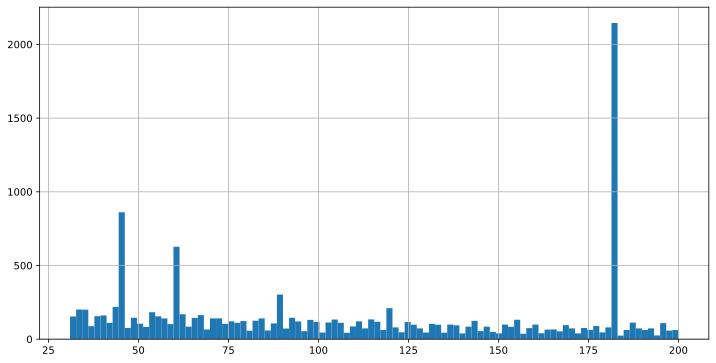

In [173]:
# срез данных по длительности периода размещения объявления от 30 до 200 дней и его визуализация
midday = df.query('days_exposition > 30 and days_exposition <= 200')
midday['days_exposition'].hist(bins=100);

На полученной гистограмме среза мы можем отметить аномальные значения в отрезках:

* от 30 до 75
* от 75 до 100
* от 110 до 125
* от 175 до 200

Сделаем последовательные срезы и выясним точный день аномального значения для каждого указанного временного интервала.

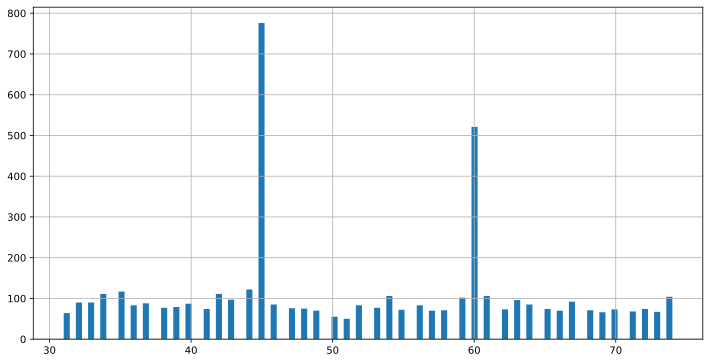

In [174]:
# аномальные значения в периоде от 30 до 75
midday1 = df.query('days_exposition > 30 and days_exposition < 75')
midday1['days_exposition'].hist(bins=100);

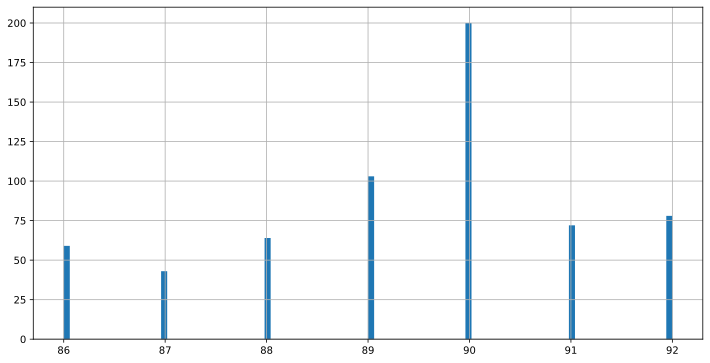

In [175]:
# аномальные значения в периоде от 75 до 100
midday2 = df.query('days_exposition > 85 and days_exposition <= 92')
midday2['days_exposition'].hist(bins=100);

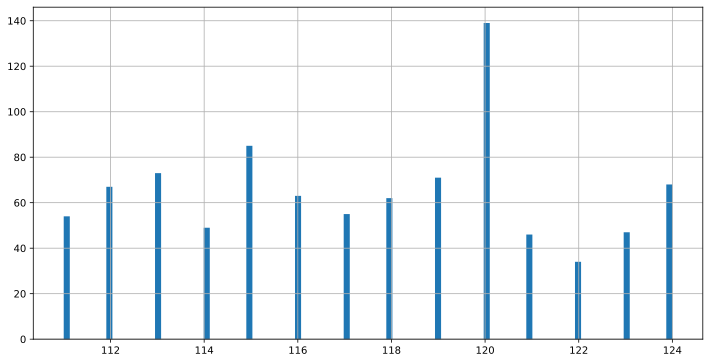

In [176]:
# аномальные значения на 120 день публикации объявления
midday3 = df.query('days_exposition > 110 and days_exposition < 125')
midday3['days_exposition'].hist(bins=100);

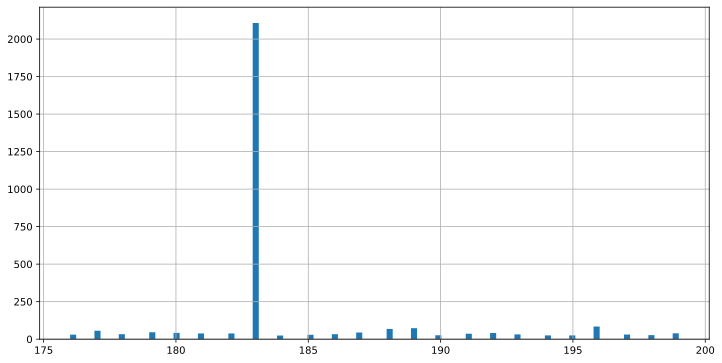

In [177]:
# аномальные значения на 183 день публикации объявления
midday4 = df.query('days_exposition > 175 and days_exposition < 200')
midday4['days_exposition'].hist(bins=100);

Итого: имеем аномальные значения на 45, 60, 90, 120, 183 день в общем массиве данных по признаку `days_exposition`.

In [178]:
# последовательно создаём индексы по каждому срезу, и затем проводим удаление данных по индексу
days45 = df.query('days_exposition == 45')
days45_index = days45.index
df.drop(days45.index, inplace = True)

days60 = df.query('days_exposition == 60')
days60_index = days60.index
df.drop(days60.index, inplace = True)

days90 = df.query('days_exposition == 90')
days90_index = days90.index
df.drop(days90.index, inplace = True)

days120 = df.query('days_exposition == 120')
days120_index = days120.index
df.drop(days120.index, inplace = True)

days183 = df.query('days_exposition == 183')
days183_index = days183.index
df.drop(days183.index, inplace = True)

**Вывод:** кажущиеся на первый взгляд аномальными значения периода длительности публикации являются прямым следствием  [политики размещения объявлений платформы Яндекс Недвижимость](https://yandex.ru/support/realty/paid.html). На основании информации датафрейма, подтверждаемой [наличием опций бесплатных и платных объявлений, а также существованием нескольких тарифов](https://yandex.ru/support/realty/realtor/home/add-ads-housing.html), которые позволяют продлевать период публикации объявления на ограниченный срок, мы можем выделить следующие даты:
* 45 дней - квартиры стоимостью до 4,5 млн
* 45 дней - комнаты
* 60 дней - квартиры стоимостью от 4,5 до 10 млн
* 90 дней - квартиры стоимостью от 10 млн
* 120 дней - вообще продажа недвижимого имущества в Санкт-Петербурге и Ленинградской области 
* 183 дня - поскольку за полгода в Санкт-Петербурге и Ленинградской области можно разместить только 1 бесплатное объявление, поэтому, на 183-й день такое объявление снимается с публикации автоматически.

В указанных объявлениях квартиры по факту проданы не были и это всего лишь свидетельство того, что истёк срок длительности публикации. Эти строки, даже с учётом их существенного объёма в общей массе данных, мы вынуждены удалить.

In [179]:
# выведем размер очищенного датафрейма
df.shape

(19273, 23)

**Вывод:** в рамках предварительной обработки данных нами были выявлены и изучены пропущенные значения по всем числовым признакам. Для этого была разработана и реализована соответствующая стратегия: заполнение пропусков значением `0` там, где это логически обосновано; заполнение медианным или минимальным нормативным значением; восстановление данных с помощью получения геокода и с помощью дополнительного созданного признака категории удалённости населённого пункта от центра Ленинградской области – Санкт-Петербурга для восстановления сбалансированных значений по целому ряду взаимосвязанных признаков.

Также, нами были рассмотрены типы данных в датафрейме, выполнено необходимое преобразование вещественных типов данных к целочисленным: `floors_total`, `parks_nearest`, `ponds_nearest`, `parks_around3000`, `ponds_around3000`, `balcony`, `apartment`.

По итогам изучения уникальных значений признака `locality_name` были устранены 43 неявных дубликата и укрупнены смысловые синонимы: к типу посёлок отнесён городской посёлок, городского типа, городской, коттеджный, при железнодорожной станции, а к садовому товариществу отнесено садоводческое некоммерческое товарищество.

Исследованы и обработаны редкие и выбивающиеся значения. Выполнена проверка на соблюдение логических условий по взаимосвязанным признакам, обработаны некорректные данные с механическими или смысловыми ошибками ввода.

В датафрейме выявлено присутствие экономичного, среднего и люксового ценового сегмента рынка недвижимости Санкт-Петербурга и Ленинградской области. В целях получения полной и объективной картины считаем необходимым сохранение данных по люксовому сегменту с последующим сравнительным исследованием (информация представлена в `Шаг 4.`).

После предварительной обработки исходный датафрейм сократился с 23 699 до 19 273, потери данных составили 4 426 строк или 18.7%.

<a id=3></a>
## Шаг 3. Создание новых признаков

<a id=3.1.></a>
### 3.1. Цена одного квадратного метра

In [180]:
# расчёт стоимости одного квадратного метра жилья
df['price_m2'] = df['last_price'] / df['total_area']

<a id=3.2.></a>
### 3.2. День недели публикации объявления

In [181]:
# проставим день недели в формате числа (1 - понедельник, 7 - воскресенье):
df['day_exp'] = df['first_day_exposition'].apply(lambda x: x.isoweekday())

In [182]:
# создадим словарь для замены числовых значений на текстовые
dict_of_weekdays = {1: '1 - понедельник', 2: '2 - вторник', 3: '3 - среда',
                    4: '4 - четверг', 5: '5 - пятница',
                    6: '6 - суббота', 7: '7 - воскресенье'}

In [183]:
# заменяем значения по ранее созданному словарю
df['day_exp'] = df['day_exp'].map(dict_of_weekdays)

<a id=3.3.></a>
### 3.3. Месяц публикации объявления

In [184]:
df['month_exp'] = df['first_day_exposition'].apply(lambda x: x.month)

<a id=3.4.></a>
### 3.4. Год публикации объявления

In [185]:
df['year_exp'] = df['first_day_exposition'].apply(lambda x: x.year)

<a id=3.5.></a>
### 3.5. Тип этажа квартиры

In [186]:
# значения — «первый», «последний», «другой»
df['floor_type'] = np.where(df['floor'] == 1, 'первый', 'другой')
df['floor_type'] = np.where(df['floor'] == df['floors_total'], 'последний', df['floor_type'])

<a id=3.6.></a>
### 3.6. Расстояние до центра города в километрах

In [187]:
# создаём новый признак километража
df['cityCenters_km'] = (df['cityCenters_nearest'] / 1000).astype(int)

In [188]:
# выведем датафрейм для ознакомления с изменениями
df.head()

,locality_name,last_price,total_area,living_area,kitchen_area,rooms,ceiling_height,balcony,is_apartment,studio,...,total_images,first_day_exposition,days_exposition,cityCenters_category,price_m2,day_exp,month_exp,year_exp,floor_type,cityCenters_km
1,поселок Шушары,3350000.0,40.4,18.6,11.0,1,2.60,1,False,False,...,7,2018-12-04,81,Ленинградская область,82920.792079,2 - вторник,12,2018,первый,18
2,Санкт-Петербург,5196000.0,56.0,34.3,8.3,2,2.60,0,False,False,...,10,2015-08-20,558,пригородные районы,92785.714286,4 - четверг,8,2015,другой,13
3,Санкт-Петербург,64900000.0,159.0,53.5,6.0,3,2.70,0,False,False,...,0,2015-07-24,424,удалённые районы города,408176.100629,5 - пятница,7,2015,другой,6
4,Санкт-Петербург,10000000.0,100.0,32.0,41.0,2,3.03,0,False,False,...,2,2018-06-19,121,удалённые районы города,100000.000000,2 - вторник,6,2018,другой,8
5,поселок Янино-1,2890000.0,30.4,14.4,9.1,1,2.60,0,False,False,...,10,2018-09-10,55,Ленинградская область,95065.789474,1 - понедельник,9,2018,другой,65


**Вывод:** нами были последовательно добавлены в датафрейм следующие новые признаки: цена одного квадратного метра `price_m2`, день недели публикации объявления `day_exp`, месяц публикации объявления `month_exp`, год публикации объявления `year_exp`, тип этажа квартиры `floor_type`, расстояние до центра города в километрах `cityCenters_km`.

<a id=4></a>
## Шаг 4. Исследовательский анализ данных

В целях эффективной исследовательской работы с ключевыми признаками полагаем целесообразным из текущего датафрейма размером 19 273 строк на 29 столбцов сформировать новый датафрейм со следующими признаками:

* `locality_name` - населённый пункт
* `total_area` - общая площадь
* `last_price` - цена объекта
* `price_m2` - цена одного квадратного метра

* `living_area` - жилая площадь
* `kitchen_area` - площадь кухни
* `rooms` - количество комнат
* `ceiling_height` - высота потолков

* `floor` - этаж квартиры
* `floor_type` - тип этажа квартиры («первый», «последний», «другой»)
* `floors_total` - общее количество этажей в доме

* `cityCenters_nearest` - расстояние до центра города в метрах
* `cityCenter_km` - расстояние до центра города в километрах 
* `airports_nearest` - расстояние до ближайшего аэропорта
* `parks_nearest` - расстояние до ближайшего парка

* `first_day_exposition` – дата (день и месяц) публикации объявления
* `days_exposition` - длительность периода размещения объявления
* `day_exp` - день недели публикации объявления 
* `month_exp` - месяц публикации объявления 
* `year_exp` - год публикации объявления

Из этого датафрейма методом среза `query` создать 2 датафрейма, содержащих сведения о среднем ценовом сегменте **`middle`** и люксовом ценовом сегменте **`luxury`** по всем вышеназванным признакам. Линией разделения ценовых сегментов станет значение признака `last_price` выше или ниже 10 000 000 руб. 75-й перцентиль этого признака равен 6 850 000 руб., а верхний ус `boxplot` находится на отметке в 11 000 000 руб. Возьмём для анализа **верхний порог значений в 11 000 000 руб.** и сделаем по нему срез датафрейма.

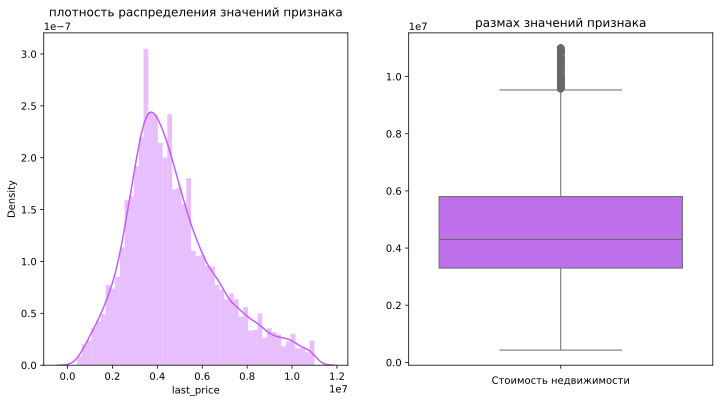

In [189]:
# парные диаграммы признака `last_price`
# визуализация среза признака `last_price`
last_price_detailed = df.query('last_price < 11000000')

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.title('плотность распределения значений признака')
sns.distplot(last_price_detailed['last_price'], color = '#c25cfd')

plt.subplot(1,2,2)
plt.title('размах значений признака')
sns.boxplot(y=last_price_detailed['last_price'], color = '#c25cfd').set(ylabel = '', xlabel = 'Стоимость недвижимости')

plt.show()

In [190]:
# создание общего датафрейма с необходимыми признаками
df_common = df[['locality_name', 'total_area', 'last_price', 'price_m2', 
                'living_area', 'kitchen_area', 'rooms', 'ceiling_height', 
                'floor', 'floor_type', 'floors_total', 
                'cityCenters_nearest', 'cityCenters_km', 'airports_nearest', 'parks_nearest', 
                'first_day_exposition', 'days_exposition', 'day_exp', 'month_exp', 'year_exp']]

In [191]:
# создание двух отдельных массивов данных по среднему и люксовому сегменту
middle = df_common.query('last_price <= 11000000')
luxury = df_common.query('last_price > 11000000')

In [192]:
# проверяем полноту каждого созданного датафрейма
print('Сводный датафрейм:', df_common.shape[0], 'записей всего. Из них:')
print('датафрейм по среднему ценовому сегменту:', middle.shape[0])
print('датафрейм по люксовому ценовому сегменту:', luxury.shape[0])

Сводный датафрейм: 19273 записей всего. Из них:
датафрейм по среднему ценовому сегменту: 17697
датафрейм по люксовому ценовому сегменту: 1576


<a id=4.1.></a>
### 4.1. Изучение параметров объектов
     
* общая площадь;
* жилая площадь;
* площадь кухни;
* цена объекта;
* количество комнат;
* высота потолков;
* этаж квартиры;
* тип этажа квартиры («первый», «последний», «другой»);
* общее количество этажей в доме;
* расстояние до центра города в метрах;
* расстояние до ближайшего аэропорта;
* расстояние до ближайшего парка;
* день и месяц публикации объявления.

Постройте отдельные гистограммы для каждого из этих параметров. Опишите все ваши наблюдения по параметрам в ячейке с типом markdown.

In [193]:
# заменяем текстовые значения числовыми для построения диаграмм
# 'floor_type' тип этажа квартиры
floor_cat = {'первый': 1, 'другой': 2, 'последний': 3}
middle['floor_type'].replace(floor_cat, inplace=True)
luxury['floor_type'].replace(floor_cat, inplace=True)

In [194]:
# заменяем текстовые значения числовыми для построения диаграмм
# 'day_exp' день размещения объявления
day_cat = {'1 - понедельник':1, '2 - вторник': 2, '3 - среда':3,
           '4 - четверг':4, '5 - пятница':5,
           '6 - суббота':6, '7 - воскресенье':7}
middle['day_exp'].replace(day_cat, inplace=True)
luxury['day_exp'].replace(day_cat, inplace=True)

In [195]:
# создаём словарь признаков
columns = {'last_price':'цена квартиры',
'total_area':'общая площадь', 
'living_area':'жилая площадь',
'kitchen_area':'площадь кухни',
'rooms':'количество комнат',
'ceiling_height':'высота потолков',
'floor':'этаж квартиры',
'floor_type':'тип этажа квартиры',
'floors_total':'общее количество этажей в доме',
'cityCenters_nearest':'расстояние до центра города в метрах',
'airports_nearest':'расстояние до ближайшего аэропорта',
'parks_nearest':'расстояние до ближайшего парка',
'day_exp':'день публикации объявления',
'month_exp':'месяц публикации объявления'}

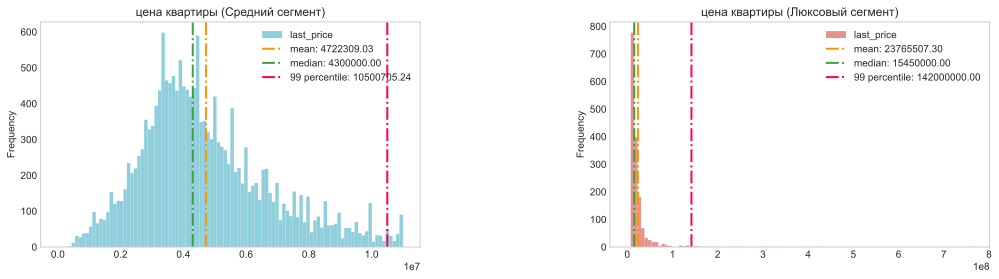

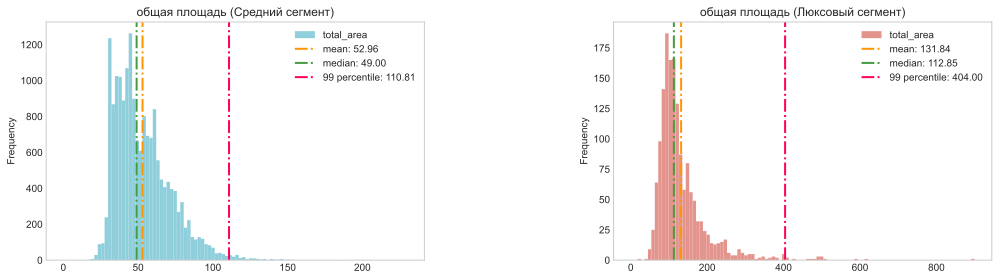

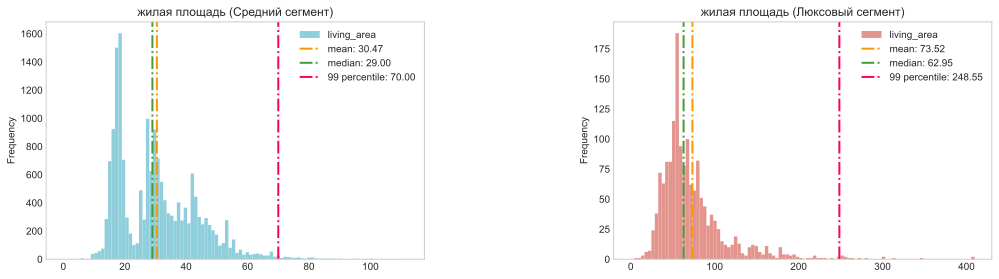

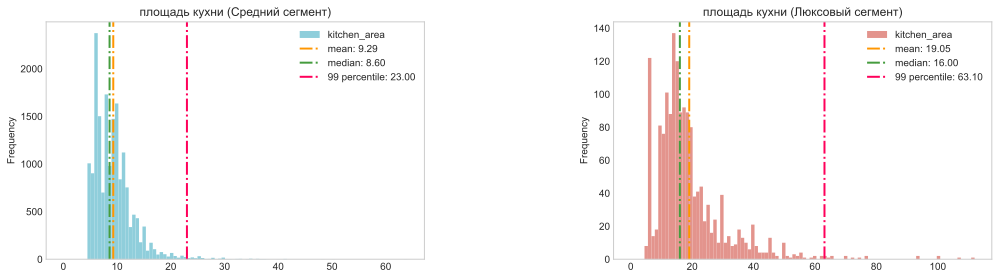

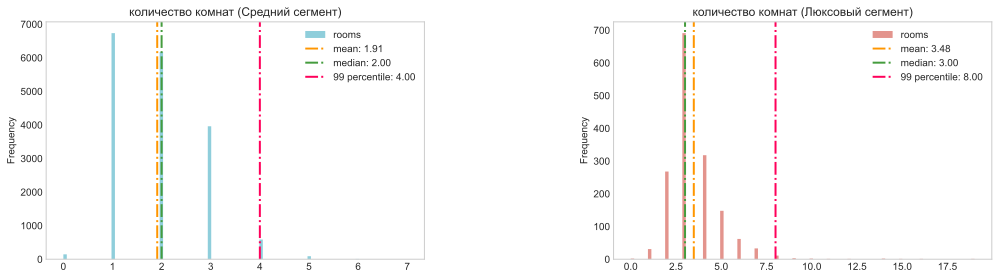

...

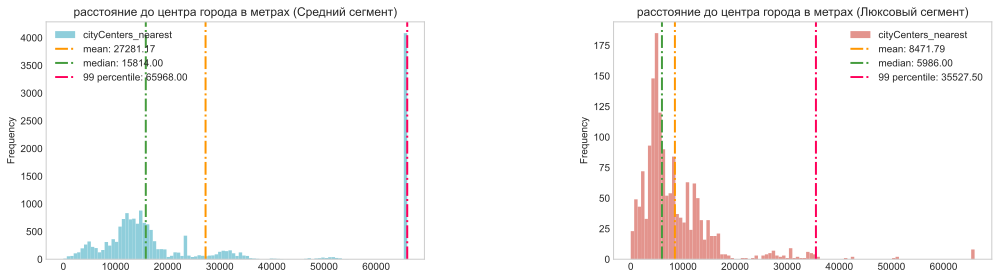

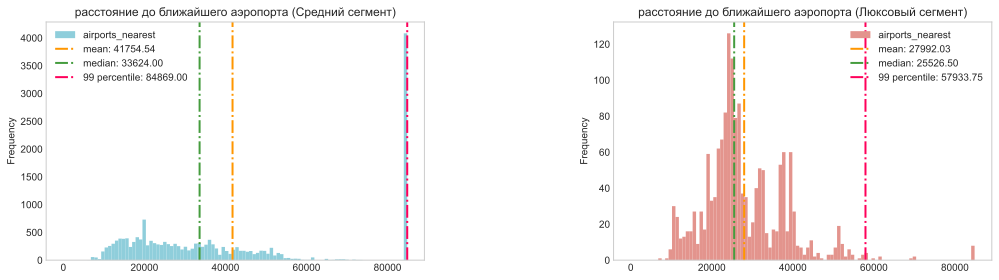

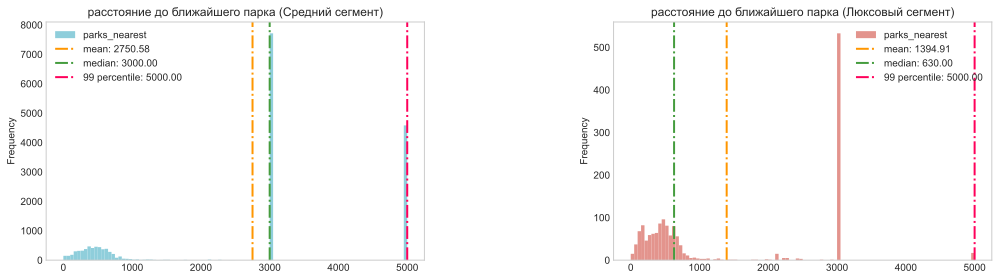

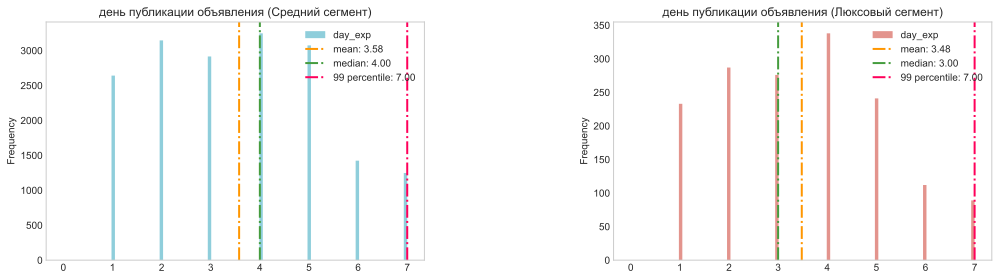

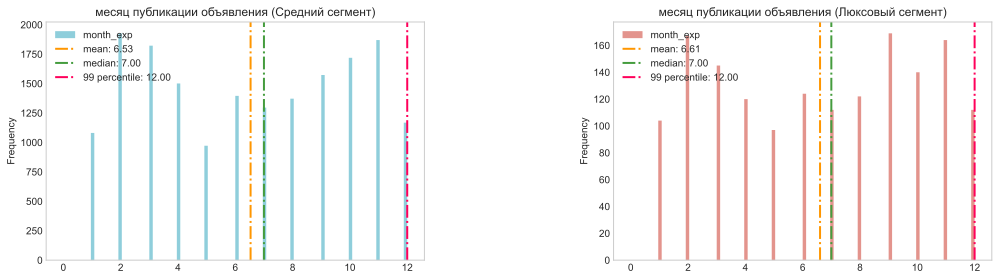

In [196]:
# задаём общий стиль сетки
plt.style.use('seaborn-v0_8-whitegrid')

# цикл отрисовки: для каждого признака создаём одно поле с двумя графиками
for col, title in columns.items():
    # создаём фигуру с двумя сабплотами (1 строка, 2 столбца)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
    
    # левый график: средний ценовой сегмент
    middle[col].plot(kind='hist', bins=100, range=(0, middle[col].max()), ax=ax1, color='#8fcedb', grid=False, legend=False)
    ax1.set_title(f'{title} (Средний сегмент)')
    ax1.axvline(x=middle[col].mean(), color='#ff9600', linestyle='-.', linewidth=2, label=f'mean: {middle[col].mean():.02f}')
    ax1.axvline(x=middle[col].median(), color='#459c3e', linestyle='-.', linewidth=2, label=f'median: {middle[col].median():.02f}')
    ax1.axvline(x=np.percentile(middle[col], 99), color='#ff005a', linestyle='-.', linewidth=2, label=f'99 percentile: {np.percentile(middle[col], 99):.02f}')
    ax1.legend()
    
    # правый график: люксовый ценовой сегмент
    luxury[col].plot(kind='hist', bins=100, range=(0, luxury[col].max()), ax=ax2, color='#e3948d', grid=False, legend=False)
    ax2.set_title(f'{title} (Люксовый сегмент)')
    ax2.axvline(x=luxury[col].mean(), color='#ff9600', linestyle='-.', linewidth=2, label=f'mean: {luxury[col].mean():.02f}')
    ax2.axvline(x=luxury[col].median(), color='#459c3e', linestyle='-.', linewidth=2, label=f'median: {luxury[col].median():.02f}')
    ax2.axvline(x=np.percentile(luxury[col], 99), color='#ff005a', linestyle='-.', linewidth=2, label=f'99 percentile: {np.percentile(luxury[col], 99):.02f}')
    ax2.legend()
    
    # оптимизируем расположение подписей и выводим единый график
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.5) 
    plt.show()

**Вывод** по данному блоку исследований представлен в виде таблицы ниже.

*Таблица 5. Сравнительные характеристики ключевых параметров среднего и люксового ценового сегмента рынка недвижимости Санкт-Петербурга и Ленинградской области за период 2014 - 2019 годов*

| наименование признака | средний ценовой сегмент                              |               люксовый ценовой сегмент     |
|:----------------------|:-----------------------------------------------------|:-------------------------------------------|
|`цена объекта`|Диапазон цен на квартиры находится в пределах от 430 000 до 11 000 000 руб. Средняя цена в 4 818 126 руб. незначительно превосходит медианное значение в 4 300 000 руб. Абсолютное большинство квартир было продано по цене до 5 826 345 руб.|Диапазон цен на квартиры находится в пределах от 11 050 000 руб. до 763 000 000 руб. Стоит отметить, что верхний порог стоимостных значений принадлежит только одному объекту.  В люксовом ценовом сегменте по определению существует не массовый, а штучный товар с уникальными, выбивающимися из общей картины характеристиками и параметрами, поэтому медианное значение по этому признаку в 15 545 000 руб. ниже, чем средняя цена люкс-объекта в 23 769 725 руб. Большинство квартир в этом сегменте были проданы по стоимости от 15 450 000 руб. до 23 000 000 руб.|
|`общая площадь`|Минимальный метраж квартиры среднего ценового сегмента начинается от скромных 15 кв.м и заканчивается площадью почти целого этажа в 230 кв.м. Если соотнести максимальную цену и максимальную площадь в этом сегменте, можем получить большую квартиру сильной степени износа, капитальный ремонт которой встанет в сумму, равную самой квартире. Медианное значение общей площади фиксирует величину 49 кв.м., а средне значение расположилось чуть повыше на уровне 52 кв.м. Таким образом, большая часть квартир среднего ценового сегмента располагает площадью от 49 до 110 кв.м.|Запросы покупателей в этом сегменте существенно больше, как и площади квартир. Так, минимальный метраж начинается от 25 кв.м. В среднем, общая площадь люксовой квартиры совпадает с её медианным значением, и колеблется от 112 кв.м  до 150 кв.м. Хотя, отдельные гиганты расположились явно в двух- или трёх-ярусных квартирах на 900 кв.м.|
|`жилая площадь`|Умение разместиться с комфортом на жилой площади в 6 метров на 3 человек присуще жителям “хрущёвок”. Медианное значение этого признака почти равно среднему – это 29 кв.м – 30 кв.м. Большинство квартир могут похвастаться жилой площадью от 39 кв.м и более. Просторные квартиры с метражом 112 кв.м редкость для среднего ценового сегмента и, потенциально, обременены негативными факторами, которые не позволяют оценить эти метры по большей стоимости.|Минимальные 6 кв.м жилой площади в элитной квартире сочетаются с 16-метровой кухней и общей жилой площадью в 139 кв.м. Открытая планировка, дизайнерские решения по объединению или зонированию пространств элит-квартиры объясняют причины столь малых величин жилой площади. Медианное значение этого признака для элитной недвижимости составляет 63 кв.м., среднее немногим больше – 73 кв.м. Абсолютное большинство квартир располагают площадью от 84 кв.м. Максимальная жилая площадь в этом сегменте составляет 409 кв.м.|
|`площадь кухни`| Сердце квартиры – это кухня, и площадь сердца начинается с 5 кв.м. В большинстве квартир площадь кухни от 8 до 11 кв.м. За редким исключением кухня может достигать 64 кв.м., что характерно для квартир с большой общей площадью или квартир с открытой планировкой.| От минимальных 5 кв.м до 22 кв.м может достигать площадь кухни в элитном жилье. Но, как и в случае с жилой площадью, мы имеем дело с большой общей площадью квартиры, и потому владельцам такого жилья не придётся тесниться. Эти маленькие квадратные метры кухни с лихвой компенсируются включением в зонирование жилой площади или общей площади квартиры. Медианное значение равно 16 кв.м, а самая большая кухня – есть где развернуться! – составляет 112 кв.м.|
|`количество комнат`|В среднем ценовом сегменте в большей мере присутствуют 2-комнатные и 3-комнатные квартиры. Многокомнатные квартиры в домах повышенной степени комфортности здесь большая редкость.|От открытой планировки без комнат и границ до 19 отдельных комнат: большое разнообразие при малой представленности на рынке недвижимости в целом. В большинстве элитных квартир количество комнат не меньше 4.|
|`высота потолков`|Высота потолков – это главный визуальный признак, по которому даже обыватель сможет отличить квартиру обычную от дорогостоящей. В основной массе жилья среднего ценового сегмента находятся квартиры с потолками от 2.6 до 2.7 м. Вторую ступеньку по массовости занимают квартиры с минимальной высотой потолка в 2.1 м. Квартиры с высокими потолками, иными словами, дешёвые «сталинки», здесь встречаются чрезвычайно редко.|Для «пациента» из люксового сегмента нормотипичной будет высота потолков от 3 м и выше. Второй по частотности уровень потолков находится на отметке 4 – 4.2 м. Двухярусные квартиры с необычайно высокими потолками по 10 м – это уникальное явление даже на рынке элитной недвижимости.|
|`этаж квартиры`|Квартиры на 1 этаже явно не пользуются ни спросом, ни популярностью. Большинство объявлений – о продаже квартиры на 4-8 этаже. Редкое исключение в силу объективных причин – это квартира в высотной многоэтажке.|Картина в элитном сегменте похожа на средний: зачастую продаются квартиры на 4-8 этаже. Объявлений о продаже элитной недвижимости на 1 – 3 этаже в датафрейме присутствует минимальное количество.|
|`тип этажа квартиры`|Тип этажа квартиры «другой», исключающий первый и последний этажи здания, характерен как для среднего ценового сегмента, так и для люксового.|Предпочтительными являются квартиры в «середине» здания, первый и последний этаж явно проигрывают и не пользуются спросом.|
|`этажей в доме, всего`|Высоко сижу, далеко гляжу – это про квартиру среднего сегмента на 33 этаже 36-этажного дома. Остальные представители предпочитают расположиться в 5-этажном или 9-этажном доме. Также существенно представлены 16-этажные дома, их в датафрейме 75%.|Этажность застройки, характерная для люксового сегмента – это 8-, 9- и 14-этажные здания. По этому характерному признаку уже можно говорить о сроках ввода в эксплуатацию этих зданий: конец 80-х и вплоть до новостроек. Максимальное количество этажей было отмечено цифрой 27.|
|`расстояние до центра города, м`|Очень показательной является разница в расстоянии до центра города между средним и люксовым сегментом. Обычному горожанину придётся преодолеть расстояние от 12 до 15 км, чтобы приобщиться к прекрасному или организовать себе культурный досуг.|Житель Санкт-Петербурга с высоким уровнем достатка проживает в непосредственной близости к культурному центру: от 4,3 км до 11 км в худшем случае.|
|`расстояние до ближайшего аэропорта`|Большая удалённость от аэропорта заключает в себе и плюсы, и минусы. Уровень шумового загрязнения и постоянные транспортные коллапсы исключаются при большой удалённости от аэропорта, но, если есть необходимость добраться до места назначения именно воздушным транспортом, придётся приложить много усилий и затратить много времени. Медианное расстояние до аэропорта в среднем сегменте составляет 29.5 км., минимальное – 6 км, большинство квартир из этого сегмента расположены на существенном удалении почти в 40 км.|Время – деньги, а время, потраченное в пробках до аэропорта – деньги вдвойне. Люксовые объекты недвижимости расположены рядом с историческим центром города, и, как следствие, незначительно удалены от аэропорта: от 7.3 км до 25 км. Максимальное расстояние в 33 км придётся преодолеть владельцам загородного жилья или пригорода Санкт-Петербурга. Если наложить эти километры на карту местности, то получим Павловск, Пушкин, Стрельну, Петергоф, Васильевский остров и Петроградский район.|
|`расстояние до ближайшего парка`|Вопрос экологического благополучия места проживания для многих представителей среднего сегмента далеко не вопрос. В том смысле, что до парка или любого другого объекта рекреации им далеко. Представлено очень мало квартир с шаговой доступностью озеленённых участков города, и в большинстве случаев для отдыха и выезда в парк придётся потратить пару часов.|Дисклокация квартир люксового сегмента в историческом центре города по умолчанию решает вопрос с озеленённостью и благоустройством прилегающих территорий. Минимальный километраж от квартиры до парка составляет не километры, а вполне реальные 379 м, а в среднем 630 м. Но элитные квартиры на большом удалении от парков и зон отдыха тоже не редкость.|
|`день публикации объявления`|Мы можем предположить, что на графиках виден результат не только самостоятельного размещения объявлений продавцами, но и риэлторами: пик значений приходится на среду и четверг.|Ожидаемо, элитная недвижимость реализуется через риэлторские агентства и среда в качестве дня самой большой нагрузки, выглядит естественной и ожидаемой.|
|`месяц публикации объявления`|Вне зависимости от сегмента, рынок недвижимости, в общем и целом, живёт по своим законам: пик количества публикаций объявлений приходится на июль, хотя мы можем отметить определённую сезонность для февраля и марта, а также ноября.|Такие же всплески активности характерны и для люксового сегмента. Это свидетельство общности рынка недвижимости этого региона.|

<a id=4.2.></a>
### 4.2. Сроки продажи квартир

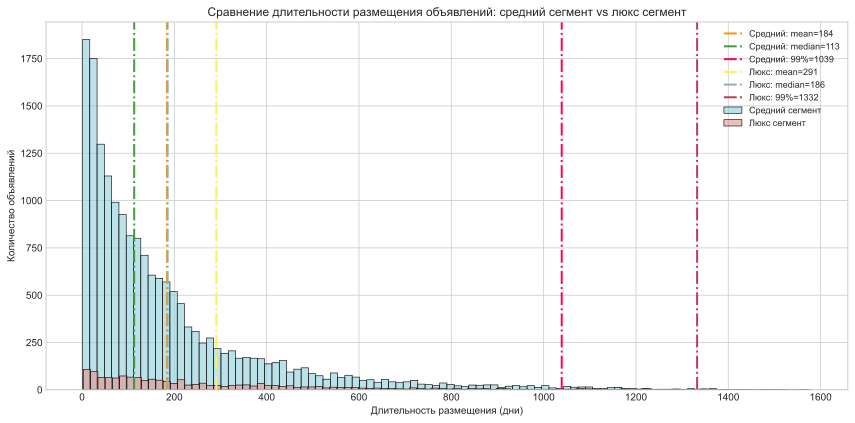

In [197]:
# визуализация: длительность периода размещения объявления (совмещённый график)
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(12, 6))

# совмещённые гистограммы с прозрачностью
sns.histplot(data=middle, x='days_exposition', color='#8fcedb', label='Средний сегмент', bins=100, alpha=0.6)
sns.histplot(data=luxury, x='days_exposition', color='#e3948d', label='Люкс сегмент', bins=100, alpha=0.6)

# статистики для среднего сегмента
plt.axvline(middle['days_exposition'].mean(), color='#ff9600', linestyle='-.', linewidth=2, label=f"Средний: mean={middle['days_exposition'].mean():.0f}")
plt.axvline(middle['days_exposition'].median(), color='#459c3e', linestyle='-.', linewidth=2, label=f"Средний: median={middle['days_exposition'].median():.0f}")
plt.axvline(np.percentile(middle['days_exposition'], 99), color='#ff005a', linestyle='-.', linewidth=2, label=f"Средний: 99%={np.percentile(middle['days_exposition'], 99):.0f}")

# статистики для люкс сегмента
plt.axvline(luxury['days_exposition'].mean(), color='#fef055', linestyle='-.', linewidth=2, label=f"Люкс: mean={luxury['days_exposition'].mean():.0f}")
plt.axvline(luxury['days_exposition'].median(), color='#93aeb9', linestyle='-.', linewidth=2, label=f"Люкс: median={luxury['days_exposition'].median():.0f}")
plt.axvline(np.percentile(luxury['days_exposition'], 99), color='#bd3a59', linestyle='-.', linewidth=2, label=f"Люкс: 99%={np.percentile(luxury['days_exposition'], 99):.0f}")

plt.title('Сравнение длительности размещения объявлений: средний сегмент vs люкс сегмент')
plt.xlabel('Длительность размещения (дни)')
plt.ylabel('Количество объявлений')
plt.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

Чтобы ответить на вопрос о том, какие продажи можно считать очень быстрыми и очень долгими, мы можем воспользоваться методом описательной статистики и выбрать данные в каждом ценовом сегменте по Q1-Q2 и Q3-Q4.

In [198]:
# описательная статистика по среднему ценовому сегменту
middle['days_exposition'].describe()

count    17697.000000
mean       183.939764
std        212.175283
min          1.000000
25%         42.000000
50%        113.000000
75%        235.000000
max       1580.000000
Name: days_exposition, dtype: float64

In [199]:
# описательная статистика по люкосовому ценовому сегменту
luxury['days_exposition'].describe()

count    1576.000000
mean      290.983503
std       295.544282
min         3.000000
25%        81.000000
50%       185.500000
75%       403.250000
max      1572.000000
Name: days_exposition, dtype: float64

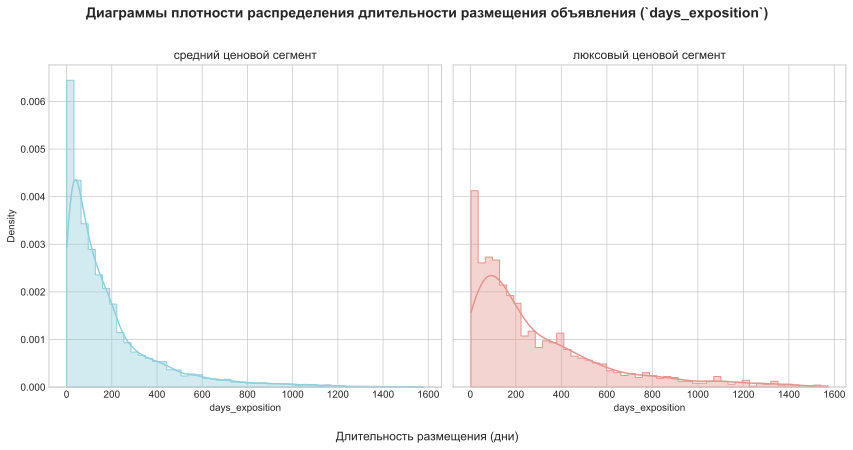

In [200]:
# диаграммы плотности распределения значений признака `days_exposition`
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

sns.histplot(data=middle, x='days_exposition', color='#8fcedb', kde=True, stat='density', bins=50, ax=ax1, alpha=0.4, element='step')
ax1.set_title('средний ценовой сегмент')

sns.histplot(data=luxury, x='days_exposition', color='#e3948d', kde=True, stat='density', bins=50, ax=ax2, alpha=0.4, element='step')
ax2.set_title('люксовый ценовой сегмент')

# подписи
fig.suptitle('Диаграммы плотности распределения длительности размещения объявления (`days_exposition`)', fontsize=14, fontweight='bold', y=1.02)
fig.supxlabel('Длительность размещения (дни)', fontsize=12)

plt.tight_layout()
plt.show()

**Вывод:** очень быстрая продажа в среднем ценовом сегменте состоялась за 1 день. Редкость, но и такое бывает! Как правило, а это правило подтверждается полученными статистическими данными, быстрой продажа квартиры может считаться, если сделка состоялась в период до 42 дней. Далее мы видим плавное, но уверенное нарастание длительности прозябания объекта в предложениях. Медианное значение длительности периода размещения объявления с последующей продажей для среднего ценового сегмента составляет 113 дней (почти 4 месяца). 99-ый перцентиль значений находится на отметке 1040 дней. Зависших объявлений в среднем ценовом сегменте всего 177 единиц.

Люксовый ценовой сегмент в силу своей уникальности и большей разреженности числа потенциальных покупателей даёт “утяжеление” срока продажи почти в 2 раза. Так, самой быстрой в люксовом сегменте стала сделка через 3 дня после публикации объявления. Быстрая продажа люксовой квартиры может состояться в период до 81 дня. Медианное значение периода размещения объявления о продаже люксовой квартиры достигает 186 дней (порядка 7 месяцев). 99-ый перцентиль значений находится на отметке 1333 дня. Зависших объявлений о продаже люксового жилья на сайте за период 2014 – 2019 годов всего 16 единиц.

Примечательно, что максимальная длительность периода размещения объявлений почти равна в обеих ценовых категориях, и составляет 1580 дней. Полагаем, после превышения этого временного порога объявление было автоматически удалено с сайта.

В общем и целом, **на стоимость квартиры влияет** её метраж, планировка и месторасположение (между историческим центром города и Токсово - пропасть социокультурного разрыва на много километров), развитость инфраструктуры, тип здания (малоквартирный дом, многоквартирный дом "хрущёвка", "брежневка", "путинка") и его состояние (новостройка, средняя степень износа, ветхий или аварийный старый жилой фонд), собственно, этажность постройки и этаж, на котором находится квартира. В последние десятилетия появился запрос на экологическую благополучность и доступность зон отдыха и рекреации.

<a id=4.3.></a>
### 4.3. Зависимость цены от ряда признаков
* общей площади;
* жилой площади;
* площади кухни;
* количества комнат;
* этажа, на котором расположена квартира (первый, последний, другой);
* даты размещения (день недели, месяц, год).

Постройте графики, которые покажут зависимость цены от указанных выше параметров. Для подготовки данных перед визуализацией вы можете использовать сводные таблицы.

Чтобы выявить меру взаимосвязи и зависимости цены объекта с остальными признаками, мы можем рассчитать корреляцию и построить графики зависимости.

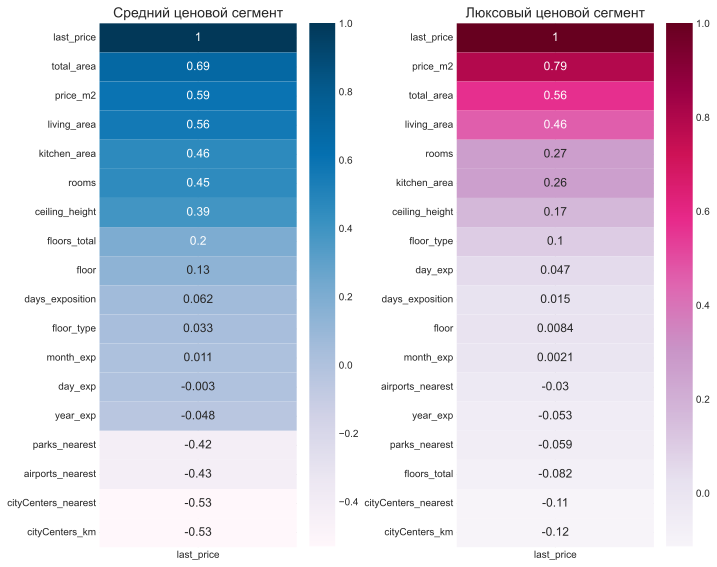

In [201]:
# поиск взаимосвязей в среднем ценовом сегменте: корреляция целевого признака с остальными признаками
# создание общего поля для двух графиков (1 строка, 2 столбца)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

# тепловая карта для среднего ценового сегмента
sns.heatmap(middle.corr(numeric_only=True)[['last_price']].sort_values(by='last_price', ascending=False), cmap='PuBu', annot=True, annot_kws={'size': 12}, ax=ax1)
ax1.set_title('Средний ценовой сегмент', fontsize=14)

# тепловая карта для люксового ценового сегмента
sns.heatmap(luxury.corr(numeric_only=True)[['last_price']].sort_values(by='last_price', ascending=False), cmap='PuRd', annot=True, annot_kws={'size': 12}, ax=ax2)
ax2.set_title('Люксовый ценовой сегмент', fontsize=14)

# подгонка отступов, чтобы графики не накладывались друг на друга
plt.tight_layout()
plt.show()

In [202]:
# взаимосвязь площадей со стоимостью квартиры в среднем и люксовом ценовом сегментах
# создаём фигуру с сеткой 3 строки × 2 столбца (возвращаем нормальный размер)
fig, axes = plt.subplots(3, 2, figsize=(14, 14))

# параметры для каждой строки: (признак, название признака)
features = [
    ('total_area', 'Общая площадь'),
    ('living_area', 'Жилая площадь'),
    ('kitchen_area', 'Площадь кухни')
]

# проходим по строкам и строим графики
for i, (feature, title) in enumerate(features):
    # левый столбец — средний сегмент
    sns.regplot(data=middle, x=feature, y='last_price', ax=axes[i, 0], scatter_kws={'color': '#8fcedb'}, line_kws={'color': 'red'})
    
    # правый столбец — люксовый сегмент
    sns.regplot(data=luxury, x=feature, y='last_price', ax=axes[i, 1], scatter_kws={'color': '#e3948d'}, line_kws={'color': 'black'})
    
    # подписи осей X и Y
    axes[i, 0].set_ylabel('Стоимость объекта, руб.' if i == 0 else '')
    axes[i, 1].set_ylabel('')
    
    axes[i, 0].set_xlabel(f'{title} (средний сегмент), кв.м')
    axes[i, 1].set_xlabel(f'{title} (люксовый сегмент), кв.м')

# общие подписи и заголовок
fig.supylabel('Стоимость объекта, руб.', fontsize=13, fontweight='bold')
fig.supxlabel('Площадь, кв.м', fontsize=13, fontweight='bold')
fig.suptitle('Сравнение регрессионных зависимостей \n в среднем vs люксовом ценовых сегментах', fontsize=15, fontweight='bold')

# подгоняем отступы: оставляем минимально необходимые поля для общих подписей
plt.tight_layout(rect=[0.04, 0.04, 0.98, 0.95])

# добавляем вертикальное расстояние между рядами (0.35 достаточно для заголовков строк)
fig.subplots_adjust(hspace=0.35)

# добавляем общие заголовки для каждой строки после настройки отступов
for i, (feature, title) in enumerate(features):
    # получаем реальную позицию графика
    pos = axes[i, 0].get_position()
    # размещаем текст чуть выше верхней границы графика
    fig.text(0.5, pos.y1 + 0.015, f'стоимость квартиры и {title.lower()}', ha='center', fontsize=13, fontweight='bold')

plt.show()

**Вывод:** точечные диаграммы среднего ценового сегмента наглядно показывают сильный коэффициент корреляции по всем типам площадей и его линейную положительную направленность. При росте величины любого из типов площадей квартиры в среднем ценовом сегменте, неизбежно и предсказуемо будет расти стоимость такой квартиры. Считаем необходимым отметить, что для среднего ценового сегмента сила взаимосвязи типа площади квартиры и стоимости квартиры большая и по своей силе примерно равна в каждом из типов площадей. Иную картину мы увидим в люксовом ценовом сегменте.

Последовательно построенные диаграммы рассеяния с линией регрессии, показывающей тенденцию в данных, демонстрируют наличие сильной линейной взаимосвязи стоимости объекта от общей площади квартиры (здесь мы видим наибольшую взаимосвязь), чуть меньше - от жилой площади и совсем малую меру зависимости стоимости квартиры от площади кухни. Коэффициент корреляции по всем видам площадей является достаточно сильным и линейным положительным. Следовательно, при росте одной величины (любого типа площади квартиры) мы гарантированно получим рост величины стоимости квартиры в люксовом сегменте данных.

In [203]:
# визуализация зависимости стоимости квартиры ценового сегмента от этажа, на котором расположена квартира
# добавляем столбец с указанием ценового сегмента
middle['segment'] = 'Средний сегмент'
luxury['segment'] = 'Люксовый сегмент'

# объединяем датафреймы в один
df_combined = pd.concat([middle, luxury])

# строим два графика рядом с помощью параметра col
g = sns.catplot(data=df_combined, x='floor_type', y='last_price', col='segment', hue='segment', palette=['#5b9bd5', '#e3948d'], height=6, aspect=1, alpha=0.5, legend=False)

# настройка подписей осей и общего заголовка
g.set_axis_labels('Этаж расположения квартиры', 'Стоимость квартиры')
g.fig.suptitle('Зависимость стоимости квартиры от типа этажа', y=1.02, fontsize=14)
g.despine(left=True)
plt.show()

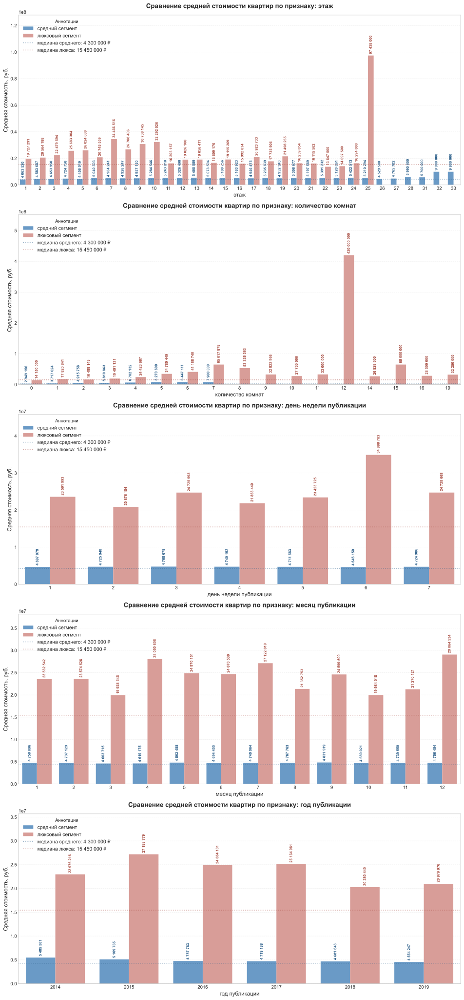

In [204]:
# визуализация зависимости стоимости квартиры каждого ценового сегмента от этажа / количества комнат / хронологических признаков
# объединяем датафреймы и добавляем столбец с названием сегмента
df_combined = pd.concat([
    middle[['floor', 'rooms', 'day_exp', 'month_exp', 'year_exp', 'last_price']].assign(Сегмент='средний сегмент'),
    luxury[['floor', 'rooms', 'day_exp', 'month_exp', 'year_exp', 'last_price']].assign(Сегмент='люксовый сегмент')
], ignore_index=True)

# словарь признаков и их названий для подписей осей
features = {
    'floor': 'этаж',
    'rooms': 'количество комнат',
    'day_exp': 'день недели публикации',
    'month_exp': 'месяц публикации',
    'year_exp': 'год публикации'
}

# функция для красивого форматирования чисел с разделителями тысяч
def format_price(x):
    return f'{int(x):,}'.replace(',', ' ')

# создаём фигуру с подграфиками (1 столбец, 5 строк)
fig, axes = plt.subplots(len(features), 1, figsize=(14, 6 * len(features)))

# цикл построения графиков
for i, (col, title) in enumerate(features.items()):
    bars = sns.barplot(data=df_combined, x=col, y='last_price', hue='Сегмент', estimator=np.mean, palette=['#5b9bd5', '#e3948d'], ci=None, ax=axes[i])
    
    # заголовки и подписи
    axes[i].set_title(f'Сравнение средней стоимости квартир по признаку: {title}', fontsize=14, fontweight='bold', pad=15)
    axes[i].set_xlabel(title, fontsize=12)
    axes[i].set_ylabel('Средняя стоимость, руб.', fontsize=12)
    axes[i].grid(axis='y', alpha=0.3, linestyle='--')
    
    # медианы по каждому сегменту
    median_middle = df_combined[df_combined['Сегмент'] == 'средний сегмент']['last_price'].median()
    median_luxury = df_combined[df_combined['Сегмент'] == 'люксовый сегмент']['last_price'].median()
    
    axes[i].axhline(y=median_middle, color='#2c5f8a', linestyle=':', linewidth=1.5, alpha=0.6, label=f'медиана среднего: {format_price(median_middle)} ₽')
    axes[i].axhline(y=median_luxury, color='#a84e43', linestyle=':', linewidth=1.5, alpha=0.6, label=f'медиана люкса: {format_price(median_luxury)} ₽')
    axes[i].legend(title='Аннотации', fontsize=11, loc='upper left')
    
    # подписи каждого сегмента соответствующим цветом
    segment_colors = ['#2c5f8a', '#a84e43']
    for j, container in enumerate(axes[i].containers):
        axes[i].bar_label(container, fmt=lambda x: format_price(x), fontsize=8, color=segment_colors[j], rotation=90, padding=3, fontweight='bold')

    # увеличиваем верхнюю границу оси Y для вертикальных подписей
    ymin, ymax = axes[i].get_ylim()
    axes[i].set_ylim(ymin, ymax * 1.25)

# подгоняем отступы
plt.tight_layout()
plt.show()

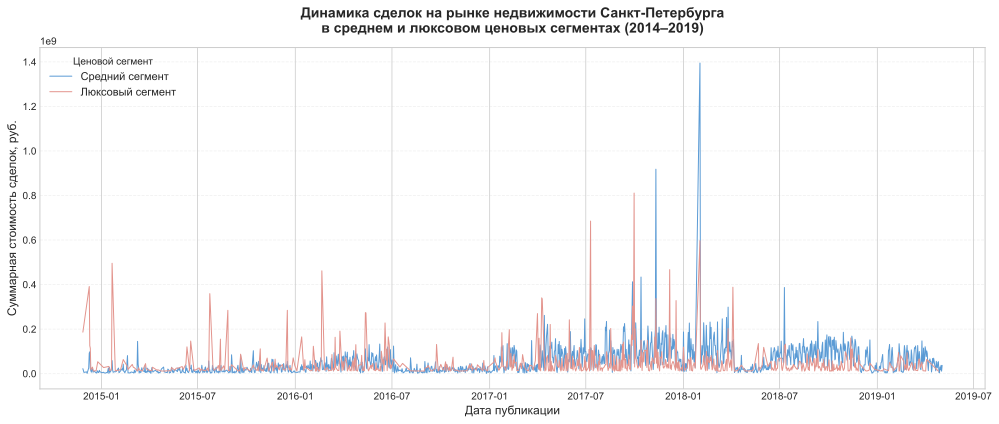

In [205]:
# динамика рынка недвижимости Санкт-Петербурга и Ленинградской области в период с 2014 по 2019 год
# создаём единую фигуру
plt.figure(figsize=(14, 6))

# средний сегмент
exp_lineplot_middle = (middle[['last_price', 'first_day_exposition']]
                       .groupby('first_day_exposition')
                       .sum()
                       .sort_values('first_day_exposition', ascending=True)
                       .reset_index())

sns.lineplot(data=exp_lineplot_middle, x='first_day_exposition', y='last_price', 
             color='#5b9bd5', label='Средний сегмент', linewidth=1)

# люксовый сегмент
exp_lineplot_luxury = (luxury[['last_price', 'first_day_exposition']]
                       .groupby('first_day_exposition')
                       .sum()
                       .sort_values('first_day_exposition', ascending=True)
                       .reset_index())

sns.lineplot(data=exp_lineplot_luxury, x='first_day_exposition', y='last_price', 
             color='#e3948d', label='Люксовый сегмент', linewidth=1)

# оформление графика
plt.title('Динамика сделок на рынке недвижимости Санкт-Петербурга\nв среднем и люксовом ценовых сегментах (2014–2019)', 
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Дата публикации', fontsize=12)
plt.ylabel('Суммарная стоимость сделок, руб.', fontsize=12)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.legend(title='Ценовой сегмент', fontsize=11, loc='upper left')

# подгоняем отступы и выводим
plt.tight_layout()
plt.show()

**Выводы:** по данному блоку исследований представлен в виде таблицы ниже.

*Таблица 6. Мера взаимосвязи целевого признака стоимости квартиры с другими признаками объектов среднего и люксового ценового сегмента рынка недвижимости Санкт-Петербурга и Ленинградской области за период 2014 - 2019 годов*

| наименование признака | средний ценовой сегмент                              |               люксовый ценовой сегмент     |
|:----------------------|:-----------------------------------------------------|:-------------------------------------------|
|`total_area`| Мера корреляции высокая положительная и равна 0.69     |   Мера корреляции высокая положительная и равна 0.56|
|`price_m2`|Мера корреляции высокая положительная и равна 0.59|Мера корреляции высокая положительная и равна 0.79|
|`living_area`|Мера корреляции высокая положительная и равна 0.56|Мера корреляции положительная и равна 0.46|
|`kitchen_area`|Мера корреляции положительная и равна 0.46|Мера корреляции положительная и равна 0.27|
|`rooms`|Мера корреляции положительная и равна 0.45. Наибольшая стоимость квартир соответствует 2 комнатам, следом за ними идут по цене 1-комнатные квартиры и замыкают тройку лидеров 3-комнатные квартиры.|Мера корреляции положительная и равна 0.27. Абсолютный лидер – это 3-комнатные квартиры. Их стоимость почти в 2 раза выше остальных предлагаемых вариантов жилья. |
|`ceiling_height`|Мера корреляции положительная и равна 0.39|Мера корреляции положительная и равна 0.17|
|`floor`|Мера корреляции чрезвычайно мала и равна 0.14. Самые дорогие квартиры в этом сегменте расположены на 2 этаже, на ступеньке за ним идёт 3 этаж, и ещё ниже по стоимости – 4 этаж.|Мера корреляции чрезвычайно мала и равна 0.0083. Самые дорогие квартиры – на 4 этаже, немногим дешевле – на 3 этаже, и следом за ним по стоимости объекта идёт квартира на 2 этаже. |
|`floor_type`|Мера корреляции чрезвычайно мала и равна 0.03. В среднем ценовом сегменте цена квартиры, безусловно, зависит от этажа расположения квартиры. Меньше всего ценятся квартиры на 1 этаже, чуть побольше – на последнем. Но в приоритете – этажность за пределами этих значений, то есть, в средине дома.|Мера корреляции положительная и равна 0.1. В люксовом ценовом сегменте квартиры на 1 этаже практически не представлены и очень низко котируются. Есть существенная масса объявлений, предлагающих квартиры не на 1 и не на последнем этажах многоквартирных домов.|
|`day_exp`|Мера корреляции чрезвычайно мала и равна -0.0029. Одно пиковое количество объявлений здесь выделить довольно трудно. Самый загруженный день – четверг, но и вторник, и пятница практически «дышат ему в спину». Причиной этому явлению могут быть консолидированные усилия риэлторов и собственников жилья.|Мера корреляции чрезвычайно мала и равна 0.0047. В люксовом сегменте ярко выраженный пик соответствия стоимости объекта и дня размещения объявления. С понедельника по четверг стоимостные характеристики объектов плавно растут, достигая максимума в четверг, а с пятницы начинается системное снижение ценовой категории. Это является следствием заранее разработанной стратегии продвижения элитного жилья на общем рынке недвижимости.|
|`month_exp`|Мера корреляции чрезвычайно мала и равна 0.01. Взаимосвязь цены объекта и интенсивности движения рынка недвижимости в целом носит сезонный характер для среднего ценового сегмента. Так, можно выделить два сезона: весенний (февраль, март) и осенний (сентябрь, октябрь, ноябрь). На зимние месяцы декабрь и январь приходится период затишья.|Мера корреляции чрезвычайно мала и равна 0.0019. Рынок люксовой недвижимости в течение календарного года движется достаточно плавно, без резких сезонных подъёмов или спадов. Незначительно большим значением количества и суммы сделок отмечается сентябрь и февраль.|
|`year_exp`|Мера корреляции чрезвычайно мала и равна -0.048. Здесь для чистоты выводов мы обязаны взять в рассмотрение только полные календарные отрезки: 2015 – 2018 включительно. С каждым годом количество объявлений и, следовательно, суммарная стоимость сделок по недвижимости, сильно нарастала. Серьёзный подъём приходится на 2017 год. Февраль 2018 года встречает нас огромнейшим пиком по количеству операций с недвижимостью.|Мера корреляции чрезвычайно мала и равна -0.053. Нарастание количества сделок с недвижимостью на платформе Яндекс Недвижимость так же характерно и для люксового сегмента. Но, если присмотреться внимательнее, то можно увидеть высокую амплитуду движений стоимости сделок не только в феврале 2018 года, но и до этого периода, и после. Предположим, что это может быть связано с инфляцией и изменением курса USD.|



<a id=4.4.></a>
### 4.4. Средняя цена одного квадратного метра в топ-10 населённых пунктах с наибольшим числом объявлений

Выделите населённые пункты с самой высокой и низкой стоимостью квадратного метра. Эти данные можно найти по имени в столбце `locality_name`.

In [206]:
# топ-10 стоимости 1 кв.м в 10 населённых пунктах с наибольшим числом объявлений для среднего ценового сегмента
topmid = middle.groupby('locality_name').agg(count=('locality_name', 'count'), mean_price_m2=('price_m2', 'mean')) 
topmid.sort_values(by='count', ascending=False, inplace=True)
top_mid_10 = topmid.iloc[:10]
top_mid_10.sort_values(by='mean_price_m2', ascending=False)

,count,mean_price_m2
locality_name,,
Санкт-Петербург,10952,103644.076789
Пушкин,314,100546.803729
деревня Кудрово,260,92170.915328
поселок Парголово,288,90550.927407
поселок Мурино,492,85149.717141
поселок Шушары,392,78686.016815
Колпино,303,75520.660793
Гатчина,265,68060.206660
Всеволожск,360,67053.902238


In [207]:
# топ-10 стоимости 1 кв.м в 10 населённых пунктах с наибольшим числом объявлений для люксового ценового сегмента
toplux = luxury.groupby('locality_name').agg(count=('locality_name', 'count'), mean_price_m2=('price_m2', 'mean')) 
toplux.sort_values(by='count', ascending=False, inplace=True)
top_lux_10 = toplux.iloc[:10]
top_lux_10.sort_values(by='mean_price_m2', ascending=False)

,count,mean_price_m2
locality_name,,
Санкт-Петербург,1500,175268.785274
Пушкин,32,134579.322298
Сестрорецк,12,131936.175263
Петергоф,7,130181.360574
поселок Репино,2,121935.021780
Павловск,2,119257.613731
Гатчина,2,118193.355730
Колпино,2,115593.525180
Кронштадт,2,104742.965368


**Выводы:** в среднем и люксовом ценовых сегментах рынка в лидеры по стоимости 1 кв.м жилья вышел Санкт-Петербург со стоимостью 103 656 руб./кв.м и 175 268 руб./кв.м соответственно. Существенная разница в списках населённых пунктов, следующих за Санкт-Петербургом и Пушкиным, подводят нас к выводу о приоритетах, престижности и ценовой доступности жилья на удалении от северной столицы для представителей обоих ценовых сегментов. Так, средний ценовой сегмент ориентирован на север рядом с Парголово, Мурино, Кудрово, и далее - до самого Выборга с ценой 58 021 руб./кв.м. Люксовая пригородная и загородная недвижимость располагается в Петергофе, Павловске, Гатчине, Кронштадте и только в Красном Селе цена за кв.м падает до уровня 70 712 руб./кв.м.

<a id=4.5.></a>
### 4.5. Зависимость цены от расстояния до центра города

Ранее вы посчитали расстояние до центра в километрах. Теперь выделите квартиры в Санкт-Петербурге с помощью столбца `locality_name` и вычислите среднюю цену каждого километра. Опишите, как стоимость объектов зависит от расстояния до центра города.

In [208]:
# делаем срез данных по среднему сегменту Санкт-Петербурга
middle_SPb = middle.query('locality_name == "Санкт-Петербург"')

In [209]:
# переводим километры в метры, средний сегментmiddle_SPb['cityCenters_km'] = (middle_SPb['cityCenters_nearest'] / 1000).round()
middle_SPb['cityCenters_km'].value_counts().index

Index([14, 12, 13, 11, 15, 16, 10,  9,  4,  8, 17,  5,  3,  6,  7,  2, 21, 18,
       22,  1, 25, 19, 20,  0, 23, 24, 28, 26, 29, 27],
      dtype='int64', name='cityCenters_km')

In [210]:
# создаём сводную таблицу с километражом и стоимостью кв.м, средний сегмент
price_mid_km = (middle_SPb.pivot_table(index='cityCenters_km', values='price_m2', aggfunc='mean'))
price_mid_km

,price_m2
cityCenters_km,
0,112580.102635
1,109078.399675
2,110244.008673
3,105000.762984
4,116728.330557
5,119672.115072
6,116913.233079
7,115852.595615
8,109344.822896


In [211]:
# из индекса таблицы создаём столбец с дополнительными данными для построения графика
price_mid_grade = price_mid_km
price_mid_grade['SPb_km'] = price_mid_km.index

In [212]:
# делаем срез данных по люксовому сегменту Санкт-Петербурга
luxury_SPb = luxury.query('locality_name == "Санкт-Петербург"')

In [213]:
# переводим километры в метры, люксовый сегмент
luxury_SPb['cityCenters_km'] = (luxury_SPb['cityCenters_nearest'] / 1000).round()
luxury_SPb['cityCenters_km'].value_counts().index

Index([ 5.0,  4.0,  6.0,  7.0,  8.0,  2.0,  1.0, 11.0, 12.0, 13.0,  3.0,  9.0,
       10.0, 15.0, 14.0, 16.0, 17.0,  0.0, 18.0, 19.0, 22.0, 27.0],
      dtype='float64', name='cityCenters_km')

In [214]:
# создаём сводную таблицу с километражом и стоимостью кв.м, люксовый сегмент
price_lux_km = (luxury_SPb.pivot_table(index='cityCenters_km', values='price_m2', aggfunc='mean'))
price_lux_km

,price_m2
cityCenters_km,
0.0,310976.834418
1.0,207812.135937
2.0,217334.860045
3.0,145538.355928
4.0,173785.755119
5.0,171187.436563
6.0,203891.218947
7.0,236562.077412
8.0,160943.579710


In [215]:
# из индекса таблицы создаём столбец с дополнительными данными для построения графика  
price_lux_grade = price_lux_km
price_lux_grade['SPb_km'] = price_lux_km.index

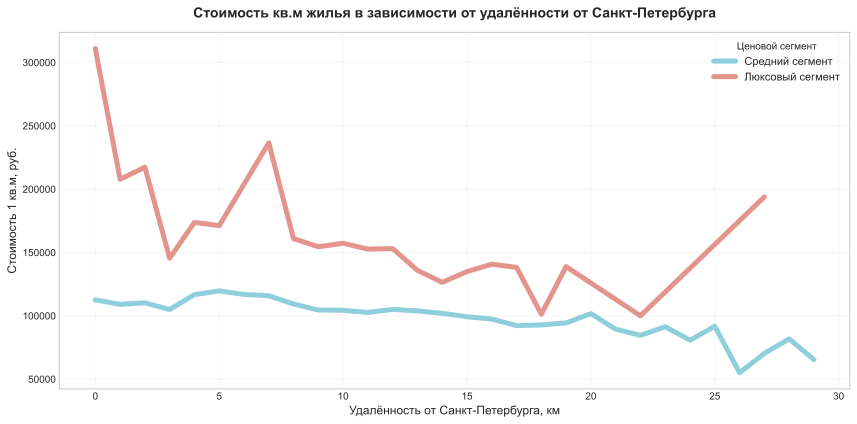

In [216]:
# создаём единую фигуру и оси
fig, ax = plt.subplots(figsize=(12, 6))

# визуализация стоимости квадратного метра в зависимости от километража и сегмента
price_mid_grade.plot(x='SPb_km', y='price_m2', kind='line', linewidth=5, color='#8fcedb', ax=ax, label='Средний сегмент')
price_lux_grade.plot(x='SPb_km', y='price_m2', kind='line', linewidth=5, color='#e3948d', ax=ax, label='Люксовый сегмент')

# оформление графика
ax.set_title('Стоимость кв.м жилья в зависимости от удалённости от Санкт-Петербурга', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Удалённость от Санкт-Петербурга, км', fontsize=12)
ax.set_ylabel('Стоимость 1 кв.м, руб.', fontsize=12)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(title='Ценовой сегмент', fontsize=11, loc='upper right')

# подгоняем отступы и выводим
plt.tight_layout()
plt.show()

**Вывод:** стоимость объектов, безусловно, взаимосвязана с расстоянием до центра города. Но характер этой взаимосвязи в обоих сегментах выглядит несколько по-разному. 

Высокая ценовая категория стоимости характерна для обоих сегментов только на отрезке первых 5 км исторической части города, но и там разница стоимости квартир и квадратного метра бросается в глаза. Для среднего сегмента квартира в исторической части города будет стоить от 116 000 до 119 000 руб/кв. В люксовом сегменте стоимость жилья в этом же районе варьируется от 217 000 до 310 000 руб./кв.м.

И только на единственном отрезке от 6 до 7 км от центра города, а это Васильевский остров и Петроградская сторона, эти линии динамики цен очень близки: стоимость кв.м для среднего сегмента здесь составит 113 000 - 120 000 руб./кв.м, элитное жильё от 203 000 до 236 000 руб./кв.м.

Чем дальше от центра города, тем сильнее выражена градация уровня дохода и покупательской способности. В среднем сегменте в соответствии с этим цена квадратного метра жилплощади плавно снижается до 70 000 - 80 000 руб./кв.м, а люксовый сегмент опять подтверждает свою исключительность и приобретает дорогостоящее загородное жильё в экологически чистых пригородных районах или в городах-парках, как Пушкин или Петергоф по цене от 100 000 руб./кв.м. до 193 000 руб./кв.м., и это отчётливо видно на последнем отрезке графика в 25 км.

<a id=5></a>
## Шаг 5. Вывод

Ежедневно миллионы людей по всей России совершают сделки с недвижимостью, будь то продажа дачного участка или приобретение ипотечной квартиры в новостройке. Разнообразие типов жилья в совокупности с большим количеством потребительских факторов создаёт для потенциального покупателя широкий спектр возможностей выбора в соответствии с имеющимся бюджетом. 

Рынок недвижимости Санкт-Петербурга – это система организационных мер, при помощи которой участники рынка (покупатели и продавцы) встают плечом к плечу вместе для определения цены, по которой происходит обмен товара - недвижимости. И рядом с продавцами и покупателями на одной ступени стоят **профессиональные участники рынка недвижимости**: брокеры, оценщики, банкиры, юристы, страховщики и, конечно, **аналитики**, занимающиеся исследованием рынка недвижимости и подготовкой информации для принятия стратегических решений по его развитию.

Получение объективной информации о положении дел на рынке недвижимости возможно только после всестороннего анализа имеющейся информации. Архив объявлений сервиса Яндекс Недвижимость по Санкт-Петербургу и Ленинградской области за период с 2014 по 2019 год включительно может стать серьёзным источником статистических данных для подобного исследования.

В целях изучения статистических данных нами была импортирована библиотека `pandas` для работы с массивами данных, `matplotlib` и `seaborn` для визуализации полученных результатов, осуществлена загрузка исходного файла с данными методом `read_csv`. В работу поступил датафрейм `real_estate_data.csv`, в котором содержится 23 699 объявлений о продаже недвижимости в разрезе следующих 22 признаков:

| № п/п  | Название               | Краткое описание                            |
|--------|:-----------------------|:--------------------------------------------|
| 1.     | `locality_name`        | название населённого пункта                 | 
| 2.     | `last_price`           | цена на момент снятия с публикации          | 
| 3.     | `total_area`           | общая площадь квартиры в квадратных метрах  |
| 4.     | `living_area`          | жилая площадь в квадратных метрах           | 
| 5.     | `kitchen_area`         | площадь кухни в квадратных метрах           | 
| 6.     | `rooms`                | число комнат                                | 
| 7.     | `ceiling_height`       | высота потолков                             | 
| 8.     | `balcony`              | число балконов                              |
| 9.     | `is_apartment`         | апартаменты                                 |  
| 10.    | `studio`               | квартира-студия                             |  
| 11.    | `open_plan`            | свободная планировка                        | 
| 12.    | `floor`                | этаж                                        | 
| 13.    | `floors_total`         | всего этажей в доме                         | 
| 14.    | `cityCenters_nearest`  | расстояние до центра города                 | 
| 15.    | `airports_nearest`     | расстояние до ближайшего аэропорта в метрах | 
| 16.    | `parks_around3000`     | число парков в радиусе 3 км                 |
| 17.    | `parks_nearest`        | расстояние до ближайшего парка              | 
| 18.    | `ponds_around3000`     | число водоёмов в радиусе 3 км               | 
| 19.    | `ponds_nearest`        | расстояние до ближайшего водоёма            |
| 20.    | `total_images`         | число фотографий квартиры в объявлении      | 
| 21.    | `first_day_exposition` | дата публикации                             |
| 22.    | `days_exposition`      | длительность периода размещения объявления  |

Перед нами была поставлена задача выполнить предварительную обработку данных, изучить и выявить интересные особенности и зависимости, которые существуют на рынке недвижимости. На основании результатов последовательного применения методов `info()`, `describe()` и визуализации гистограммы числовых признаков датафрейма методом `hist()` мы получили информацию для первичного статистического анализа. 

В рамках **предварительной обработки данных** мы подробно изучили общую информацию о состоянии исходного датафрейма. Происхождение сведений о каждом объекте в базе имеет разную природу, а именно: 1) сведения, добавленные пользователем и 2) сведения картографические.  Сведения, добавленные пользователем, описывают потребительские характеристики самого жилья, которые, в свою очередь, регулируются целым рядом ГОСТ, СНиП, СанПиН и СП, а также правилами размещения достоверной информации об объекте на платформе Яндекс Недвижимость. Имеющиеся 22 признака представлены количественными (17 столбцов), категориальными (4 столбца) и временным (1 столбец) значениями. 

С помощью цепочки методов `isna().sum()` нами были выявлены и изучены пропущенные значения по всем числовым признакам. Визуализация полученных результатов представлена на тепловой карте `heatmap`. Установлено отсутствие данных по 14 признакам в объёме более 22% от общего массива, а именно 101 441 пропуск из предполагающихся 521 378 значений. Только в 8 признаках присутствует полный набор информации. Установлено несоответствие типов признаков хранимой в них информации, а также аномальные и дублирующие значения. Исходные данные были серьёзно загрязнены.

Для обработки количественных и качественных потерь информации была разработана и реализована следующая комплексная стратегия, предусматривающая **заполнение пропусков**:

* **значением `0` там, где это логически обосновано** (признак `is_apartment` - восстановлено 20 924 или 88.24% данных по признаку; признак `balcony` - восстановлено 11 519 или 48.61% данных по признаку).

* **значением в соответствии с логическим условием** (признак `locality_name` заполнен в соответствии со значениями признака `cityCener_nearest` - восстановлено 29 или 0.2% данных по признаку;  признаки `airports_nearest` и `cityCenters_nearest` заполнены по перекрёстным пропускам в каждом из них, а также в соответствии с данными по признаку `locality_name` - восстановлено 5 542 и 5 519 строк, что составляет 23.38% и 23.29% соответственно; парные признаки `parks_nearest`, `parks_around3000` и `ponds_nearest`, `ponds_around3000` заполнены по перекрёстным пропускам в каждом из них - восстановлено 15 620 и 14 589 данных по количеству парков и водоёмов или 65.91% и 61.56% соответственно и по километражу до зон рекреации 5518 и 5518 или 23.28% и 23.28% соответственно).

* **минимальным нормативным значением** (признаки `kitchen_area` и `living_area` заполнены минимальными нормативными значениями в соответствии с СП 54.13330.2016, а также логическим условием численного превосходства признака `toral_area` над суммой этих признаков и наличии минимальной разности в 2.5 кв.м для мест общего пользования и сантехнических помещений - восстановлено 2 278 и 1 903 строк соответственно, что составляет 9.61% и 8.03% соответственно).

* **медианным или средним значением** (признак `ceiling_height` заполнен в соответствии со значениями признака `cityCener_nearest` и дополнительно созданным признаком категории удалённости - восстановлено 9 195 или 40% данных по признаку; признак `floors_total` заполнен аналогичным образом - восстановлено 86 строк или 0.36% данных по признаку; признак `days_exposition` заполнен средним групповым значением по каждому населённому пункту, остальные значения заполнены медианой - восстановлено 3 181 или 13.42% данных по признаку).

* **удаление пропусков там, где ни один из вышеперечисленных методов не может быть реализован в силу объективных причин** (единственный признак, по которому были удалены строки с пропусками `locality_name`, количество удалённых строк - 12).

Среди причин, повлекших за собой весьма плачевное состояние исходных данных, могли быть:


* **ошибка выгрузки данных** (пропуски по парам признаков `parks_nearest`, `parks_around3000` в равном количестве строк).

* при заполнении карточки объекта на платформе Яндекс Недвижимость **значение не было указано пользователем ввиду очевидных для него истин**: балкона - нет; квартира - в Санкт-Петербурге; квартира — это не апартаменты в люксовом жилом комплексе с охраняемой территорией, своим парком и бессменным консьержем на входной группе (`balcony`, `locality_name`, `is_apartment`).

* **значение не было указано пользователем умышленно** в целях сокрытия негативных пользовательских характеристик жилья: квартира - не в Санкт-Петербурге, а в пригороде, а то и вовсе в Ленинградской области; ближайший сосед - шумный аэропорт "Пулково", этаж - первый или последний, что ставит ребром вопрос безопасности проживания или вопрос сохранности имущества в случае слабого напора воды, коммунальной аварии и сезонно протекающей крыши; а высота потолка — скромные 2.1 метра (`locality_name`, `airports_nearest`, `floors_total`, `ceiling_height`). В эту же группу характеристик попадают признаки `kitchen_area` и `living_area`, которые своими малыми значениями могут оттолкнуть потенциального покупателя. 

* **ошибка ввода данных** могла быть допущена при заполнении нужного признака (упущен знак десятичной дроби) или корректная информация попала в ошибочный признак (`ceiling_height`, `kitchen_area`, `living_area`).

* **отсутствие объективных данных** у пользователя для корректного заполнения объявления о продаже, либо он попросту пренебрегает этими данными в виду их малой значимости для него (`airports_nearest`, `cityCenters_nearest`, `parks_nearest`, `ponds_nearest`, `parks_around3000`, `ponds_around3000`). Так, целевая аудитория покупателей с запросом на экологическое благополучие будущего места жительства не увидит в тематической выборке на сайте очень большое количество объявлений.

* **неактуальная информация по объявлению** Так, в признаке `days_exposition` 3 181 объявление не было закрыто. С большой долей вероятности в реальности сделка по купле-продаже состоялась, но карточка объявления так и не была снята на платформе Яндекс Недвижимость.

Также, нами были **изучены типы данных** в датафрейме, выполнено необходимое преобразование вещественных типов данных к целочисленным: `floors_total`, `parks_nearest`, `ponds_nearest`, `parks_around3000`, `ponds_around3000`, `balcony`, а также из вещественного к булевым по признаку `is_apartment`.

Выполнена обязательная **проверка на наличие дубликатов**. По итогам изучения уникальных значений признака `locality_name` устранены 43 неявных дубликата и укрупнены смысловые синонимы: к типу посёлок отнесён городской посёлок, городского типа, городской, коттеджный, при железнодорожной станции, а к садовому товариществу отнесено садоводческое некоммерческое товарищество.

Отдельного внимания заслуживает **этап работы с аномальными и выбивающимися значениями** в данных, которые к этому моменту насчитывали 23 691 строки в разрезе 23 столбцов. 

Нами был составлен перечень обязательных методов, с помощью которых мы изучим выбросы: 1) создание попарных диаграмм плотности распределения значений признака `distplot` и размаха значений признака `boxplot`, 2) вывод описательной статистики по признаку цепочкой методов `describe().astype(int)` , 3) дополним описательную статистику выводом медианного значения, полученного одноимённым методом `median()`, 4) приступим непосредственно к аномальным значениям, выявленным с помощью методов `max()`, `min()`.

Выявленные с помощью этой последовательности действий аномалии:
* подвергнем обработке в случае, если некорректные данные в них подразумевают ошибку ввода или могут пройти проверку логическим условием;
* удалим в случае, если они не проходят проверку логическим условием.


* Аномальные значения группы признаков `total_area`, `living_area`, `kitchen_area` были обработаны совместно. Выполнена замена на минимальные допустимые размеры жилой площади в 6 кв.м, проверка численного превосходства общей площади квартиры сумме жилой площади и площади кухни. 548 строк, в которых это условие не выполняется, были удалены.

* Количество комнат `rooms` подверглось проверке в части типа жилья (студия, открытая планировка) и соответствия минимальным нормативным площадям на каждую комнату в квартире. 7 строк, не прошедших проверку соразмерности площади, были удалены.

* Высота потолка `ceiling_height` изобилует неточностями. Проверку на минимальную нормативную высоту в 2.1 м не прошли 13 объявлений, они были удалены. Аномальные двухзначные высоты потолков были циклично обработаны. После обработки данных диапазон высот находится в пределах от 2.25 до 10.0 м.

* Количество балконов `balcony` также подверглось проверке на выполнение логического условия соответствия количества комнат и общей площади квартиры, выполнена замена по нормативному условию.

* Признаки `parks_nearest`, `ponds_nearest`, `parks_around3000`, `ponds_around3000` , описывающих расстояние от квартиры до ближайшего парка или водоёма и их количество, содержат минимальное количество выбросов. Указанные пользователями расстояния до парка в 1 метр, равно как и 3, 7, 9 метров не выдерживают критики и проверки реальностью, эти значения были заменены на минимальные 10 м. В данных по расстоянию до водоёмов искажений не выявлено.

* Аномальные значения признака `days_exposition` являются прямым следствием политики размещения объявлений платформы Яндекс Недвижимость. Отмечены выбросы на отметке в следующее количество дней: `45`, `60`, `90`, `120`, `183`. На указанных временных рубежах объявление автоматически снималось с продажи без совершения реальной сделки. Эти строки были удалены.

* Скорректированы механические ошибки ввода в признаках `last_price` (замена значения `12 190` на `12 190 000`), `floors_total` (замена значения `60` на `6`), `ceiling_height` (замена `100` на `10`).

В признаках `floor`, `total_images`, `cityCenters_nearest`, `airports_nearest` аномалий не обнаружено, данные распределены равномерно. В завершение предварительной обработки данных исходный датафрейм сократился с 23 699 до 19 273 строк, потери данных составили 4 426 строк или 18.7% всего объёма записей.

Следующим этапом аналитической работы было **создание новых признаков**, структурно и качественно описывающих полученные данные, а именно: цена одного квадратного метра `price_m2`, расстояние до центра города в километрах `cityCenters_km`, тип этажа квартиры `floor_type`. Для выявления характера цикличности и общих тенденций на рынке недвижимости Санкт-Петербурга и Ленинградской области были созданы признаки день недели публикации объявления `day_exp`, месяц публикации объявления `month_exp`, год публикации объявления `year_exp`.

В целях формирования полной и **объективной исследовательской картины** для дальнейшей работы считаем необходимым объединение экономичного и среднего ценовых сегментов рынка недвижимости Санкт-Петербурга и Ленинградской области, а также сохранение люксового сегмента в качестве самостоятельной части рынка недвижимости без удаления присущих ему аномально больших значений по отношению к обоим вышеназванным сегментам. Так, полученный к этому моменту исходный датафрейм `df`, содержащий всего 19 273 строки на 29 столбцов, был разделён по ключевому признаку `last_price` на его верхнем пороге значений в 11 000 000 руб. Методом `query` были сформированы два новых датафрейма для анализа, содержащие данные по среднему ценовому сегменту `middle` в размере 17 697 строк и аналогичный ему люксовый сегмент `luxury` с 1 576 объявлениями.  

В ходе исследования нами были подробно **изучены ключевые потребительские параметры объекта**. С помощью автоматизированной циклической обработки были выведены графики `boxplot` и `plot()` с данными по стоимости объекта и всем типам его площадей, количеству комнат, высоте потолка, номеру и типу этажа размещения объекта, а также общее количество этажей в доме, данные по дислокации объекта (удалённость от центра города, парка, аэропорта) и информация о дате публикации объявления (день и месяц). На графики выведена вспомогательная статистическая информация о среднем, медианном значении и границе 99 перцентиля.

Одним из приоритетных направлений нашего исследования было установление зависимости целевого признака `last_price` от всех видов площадей объекта, количества комнат, типа этажа и даты размещения.
Для этого нами был использован расчёт корреляции методом `corr` и выведена визуализация её меры с помощью `heatmap`. Линейная регрессионная взаимосвязь целевого признака `last_price` в динамике признаков всех видов площадей `total_area`, `living_area`, `kitchen_area` была выведена на графиках `regplot`. Последовательно построенные точечные диаграммы рассеяния с линией регрессии отчётливо демонстрируют линейную положительную тенденцию в данных разной степени величины по среднему и люксовому ценовым сегментам. Для среднего ценового сегмента сила взаимосвязи типа площади квартиры и стоимости квартиры большая и по своей силе примерно равна в каждом из типов площадей. Наличие сильной линейной взаимосвязи стоимости объекта от общей площади квартиры большое в люксовом сегменте, чуть меньше мера зависимости цены от жилой площади и совсем малая - мера зависимости цены от площади кухни. Следовательно, при росте одной величины (любого типа площади квартиры) мы гарантированно получим рост величины стоимости квартиры в обоих сегментах рынка недвижимости Санкт-Петербурга.

Для визуализации разброса внутри типов этажей, на которых расположен объект продажи, мы использовали график `catplot()`. Низкая степень популярности первого и последнего этажа характерна для обоих сегментов, хотя большое количество квартир на последнем этаже среднего сегмента в сочетании с расположением квартиры в радиусе 0 -10 км от исторического центра Санкт-Петербурга может навести на мысль о целенаправленной покупке такого жилья с перспективой доступа на знаменитые крыши Санкт-Петербурга или создание мансарды.

Визуализация данных по обоим сегментам с помощью графика `barplot` помогла нам установить характерные особенности, приведённые ниже:

**`Ценовая ситуация`** Нами были выделены **средний** и **люксовый ценовой сегмент** рынка недвижимости Санкт-Петербурга и Ленинградской области. Ценовым порогом разделения стала отметка стоимости объекта в 11 000 000 руб. Разница между весовыми категориями средней стоимости объекта по каждому сегменту очень велика. Диапазон цен на квартиры среднего сегмента находится в пределах от 430 000 до 11 000 000 руб. Средняя цена в 4 818 126 руб. незначительно превосходит медианное значение в 4 300 000 руб. Большинство квартир было продано по цене до 5 826 345 руб. Люксовый диапазон цен на квартиры находится в пределах от 11 050 000 руб. до 763 000 000 руб. Стоит отметить, что верхний порог стоимостных значений принадлежит только одному объекту. В этом ценовом сегменте по определению существует штучный товар с уникальными, выбивающимися из общей картины характеристиками и параметрами, поэтому медианное значение по этому признаку в 15 545 000 руб. ниже, чем средняя цена люкс-объекта в 23 769 725 руб. Большинство квартир в этом сегменте были проданы по стоимости от 15 450 000 руб. до 23 000 000 руб.

**`Особенности`** Географическая особенность расположения Санкт-Петербурга и Ленинградской области в европейской части России, помноженная на исторический контекст многовекового столичного статуса города, влагонасыщенные болотистые грунты как характерная геологическая особенность, климатическая карта местности создают уникальный и неповторимый портрет этого региона. 

**`Тенденции`** Российский рынок недвижимости находится в фазе активного развития, и Санкт-Петербург явный тому пример. Высокая деловая активность в целом характерна как для жителей центральных районов самой северной столицы, так и для жителей её отдалённых районов Ленинградской области. Скорость оборотов ротационной воронки владельцев недвижимого имущества нарастает по мере удаления от исторического центра города. В среднем ценовом сегменте смена владельцев происходит в срок от 1.5 до 4 месяцев. Люксовый ценовой сегмент в силу своей уникальности и большей разреженности числа потенциальных покупателей даёт увеличение длительности срока продажи почти в 2 раза. В этом случае мы говорим о сроках от 2.5 до 7 месяцев. Рынок недвижимости Санкт-Петербурга, тем не менее, представляет собой качественно другую нишу и не может быть стандартом для всей России. Здесь сильно включены не только российские, но и зарубежные капиталы. Мы отчётливо видим, как после падения в 2015–2016 гг. и стабилизации в 2017 г. цены предложения на рынке жилой недвижимости Санкт-Петербург в основном перешли в стадию роста, и это характерно для обоих сегментов.

**`Объём предложения и его структура`** Полагаем важным отметить существование исторически сложившихся типов городского и сельского жилья в России, обладающих характерными потребительскими признаками и являющихся неизменным символом той или иной эпохи: объекты культурного наследия (постройки XIX века), «сталинки», «хрущёвки», «брежневки», «пентагоны», «чешки», «П-44», «путинки» как наследие XX века. За последних два десятилетия на рынке недвижимости появились совершенно новые типы домов и гораздо большее разнообразие планировок. Альтернативой привычным новостройкам стали студии, апартаменты, лофты, размещённые в перепрофилированных промышленных или офисных зданиях. По сумме описательных характеристик всех параметров мы можем с большой долей успеха воссоздать тип и год постройки без выезда на место, и выдвинуть предположения о сильных и слабых сторонах выставленного на продажу объекта.

Поскольку средний сегмент представлен в гораздо большем количестве, чем люксовый, то становится очевидным и различие в объёмах предложения по каждому из сегментов: 17 697 объектов против 1 576 объектов. Имеющиеся в нашем распоряжении описательные характеристики параметров по каждому из сегментов помогут нам сформировать типовые "портреты" с характерными чертами. 

В среднем ценовом сегменте Санкт-Петербурга в большом количестве присутствуют 2- и 3-комнатные квартиры в типовых 5-, 9- и 16-этажных зданиях советской постройки средней степени износа. В таких квартирах зачастую нет балкона, общая площадь достигает значения 52 кв.м, кухня 8 кв.м, и высота потолка 2.6 – 2.7 м. До центра города, как и до зоны отдыха и рекреации, придётся преодолеть 12-15 км пути. За такую квартиру придётся заплатить сумму порядка 5 – 6 млн. руб.

В люксовом ценовом сегменте запросы выше и простор жилья гораздо больше. Общая площадь типичной элитной недвижимости начинается от скромных 112 кв.м. с жилой площадью от 84 кв.м и непоказательно маленькими кухнями по 16 кв.м. В такой квартире количество комнат больше 4, а высота потолка зачастую 4 – 4.2 м. Визуальная середина многоэтажной новостройки в 8-, 9- и 14 этажей – именно там расположены дорогостоящие квартиры.  Люксовые объекты могут быть расположены в самом сердце города, где парки и скверы на каждом шагу, а могут быть и далеко за городом в экологически благополучных городах-парках. Стоимость такой элитной недвижимости составит порядка 15 – 23 млн. руб.

**`Характерные черты`** Спрос на недвижимость определяется не только и не столько потребительскими качествами самих объектов, сколько их местонахождением. Товары этого рынка уникальны, недвижимы и их ценность в значительной мере зависит от внешней окружающей среды. Эти тезисы подтверждаются расчётами стоимости кв./м жилья для обоих сегментов в зависимости от удалённости от центра северной столицы. Пропасть значений начинается от 310 000 руб./кв.м в люксовом сегменте и 116 000 руб./кв.м в среднем сегменте, и заканчивается за 25-м километром около КАД и стоимостью 193 000 руб./кв.м люксового сегмента и 80 000 руб./кв.м. среднего сегмента.

Такой широкий спектр значений напрямую связан с рядом других факторов, таких, как расстояние до ближайшего аэропорта и зоны рекреации и отдыха. В среднем сегменте большинство объектов расположены на существенном удалении от аэропорта: от 29.5 км до 40 км. придётся преодолеть, чтобы добраться до воздушной гавани. В люксовом сегменте характерно расположение объектов на расстоянии от 7.3 км до 25 км. И только обладателям загородных объектов придётся проделать путь длиной в 33 км до аэропорта.

Экологическое благополучие места расположения объекта в последние десятилетия уверенно набирает вес и значимость, но только не для представителей среднего сегмента. Здесь дислокация объекта зачастую подразумевает отсутствие рекреационной зоны с парком или водоёмом для отдыха в шаговой доступности. Диаметрально противоположным образом обстоят дела в люксовом сегменте: здесь ярко выражены приоритетные группы объектов в историческом центре города, где вопрос озеления, парков, скверов и каналов решён по умолчанию и группы загородных или пригородных объектов, расположенных в городах-парках, таких, как Петергоф, Пушкин, Кронштадт.

**`Низкая эластичность предложения`** определяется через призму историчности самой локации и существования ряда запретительных мер на высотные постройки в центре города и его исторических районах, где предметом охраны является ансамбль фасадов не только одного особняка, а целой улицы. К тому же, болотистые почвы гарантируют трудности и многократное увеличение сметы на строительные работы. Поэтому количество предложений объектов среднего и люксового сегмента в домах высотной постройки выше 16 этажей весьма мало.

**`Цикличность`** Спад на рынке недвижимости предшествует спаду экономики в целом, и подъём на рынке недвижимости наступает раньше, чем в экономике. Созданные нами графики зависимости стоимости квартиры обоих сегментов рынка недвижимости Санкт-Петербурга от года, месяца и дня недели публикации помогли нам выявить существование цикличности и сезонности в развитии данного рынка. Вне зависимости от сегмента, рынок недвижимости, в общем и целом, живёт по своим законам: пик количества публикаций объявлений приходится на июль, хотя мы можем отметить определённую сезонность для февраля и марта, а также ноября. Для среднего сегмента характерна публикация наибольшего количества объявлений в среду и четверг, здесь видны консолидированные усилия и самих собственников объектов, и риэлторских агентств. Элитная недвижимость реализуется только через риэлторские агентства и среда в качестве дня самой большой нагрузки по количеству опубликованных объявлений, является естественной и ожидаемой.

Сфера вложения капитала в объекты недвижимости и систему экономических отношений, возникающих при операциях с недвижимостью – это основа основ национальной рыночной экономики. Проанализировав статистические данные платформы Яндекс Недвижимость Санкт-Петербурга и Ленинградской области за период 2014 – 2019 годов мы можем утверждать, что **вышеназванный рынок недвижимости хорошо развит и эффективно решает социальные задачи, связанные с использованием полезных свойств недвижимости. Здесь в полной мере присутствует свободное формирование цен на объекты. На сегодняшний день доля рынка недвижимости в валовом национальном продукте очень высока. К тому же, активные операции с недвижимостью обеспечивают высокий уровень сборов в бюджет от налогов на недвижимость и сделок с ней. Всё вышеперечисленное подтверждает большое значение рынка недвижимости Санкт-Петербурга как сектора рыночной экономики.** Полагаем, что задача данной проектной работы по исследованию данных сервиса Яндекс Недвижимость выполнена.